# M5 Demand Forecasting — Baselines & Model Evaluation

**Project:** Agentic AI for Retail Demand & Inventory Decision Support (IDS 560, Group 4)

**Focus:** Forecasting Baselines, Chronological Validation, Model Evaluation, Error Analysis, Prediction Intervals & Integration

**Data:** M5 Forecasting (Walmart-originated, Kaggle): `sales_train_evaluation.csv`, `calendar.csv`, and `sell_prices.csv`.

**Dataset Scope:** The full dataset contains 30,490 item-store daily sales time series. The pipeline uses a 100-series prototype, a 20% stratified sample (6,098 series), and an expanded 50% stratified sample (15,245 series). The 20% sample is nested within the 50% sample, with stratification by state and product category.

**Forecast Horizons:** 7, 14, and 28 days for baseline evaluation; 7 days for the current prediction interval evaluation and item-level forecast generation.

**Baseline Models:** Zero Naive, Weekly Seasonal Naive, and Recent Mean (7-day window).

**Evaluation Metrics:** MAE, RMSE, WAPE, Forecast Bias, Forecast Value Added (FVA), Prediction Interval Coverage, Mean Interval Width, and P10/P90 Pinball Loss.

**Objective:** Develop a reproducible, memory-efficient, and leakage-aware forecasting pipeline using the M5 retail sales dataset.

The pipeline establishes interpretable forecasting baselines, evaluates their accuracy across multiple forecast horizons, investigates forecasting errors across different demand patterns, and quantifies forecast uncertainty using prediction intervals.

The resulting outputs provide a standardized foundation for future comparisons with advanced forecasting models, including TimeCopilot, and downstream integration with RAG and Streamlit.


**How the Notebook Is Organized:**

The notebook follows a structured forecasting workflow, progressing from data preparation and baseline evaluation to error diagnostics, prediction interval calibration, and downstream integration.

| # | Section | Question It Answers |
|---|---|---|
| 1 | Configuration & Memory-Efficient Data Loading | How do we load and configure the M5 dataset efficiently? |
| 2 | Data Alignment & Integrity Checks | Are the source datasets correctly aligned and reliable? |
| 3 | Series Sampling | How do we construct reproducible, nested, and proportionally representative samples? |
| 4 | Chronological Splitting | How do we separate training, validation, and test periods without overlap? |
| 5 | Preprocessing | How do we prepare the sales data for forecasting? |
| 6 | Baseline Forecasting | How do Zero Naive, Weekly Seasonal Naive, and Recent Mean generate predictions? |
| 7 | Rolling-Origin Validation | How do we evaluate forecasts across multiple historical origins? |
| 8 | Horizon Evaluation, Model Comparison & FVA | How do the baselines perform across 7-, 14-, and 28-day horizons, and how much improvement does Recent Mean provide? |
| 9 | Error Analysis | Where do forecasting errors occur across states, categories, and demand patterns? |
| 10 | Forecast Bias Analysis | Do forecasts systematically overestimate or underestimate observed sales? |
| 11 | Demand Segmentation Evaluation | How does forecasting performance vary across demand quantiles and demand types? |
| 12 | Prediction Interval Evaluation | How do Pooled and Demand-Type P10–P90 prediction intervals quantify forecast uncertainty? |
| 13 | Sample & Metadata Validation | Are sampled sales matrices, metadata, and original source records correctly aligned? |
| 14 | Forecast Generation & Export | How do we generate, validate, and export standardized seven-day item-level forecasts? |
| 15 | Forecasting Integration & RAG / Streamlit Handoff | How can standardized forecasts support downstream RAG explanations, Streamlit visualization, and future model comparisons? |

**Workflow Summary:**

**Phase 1 — Data Preparation (Sections 1–5):** Data loading, integrity validation, stratified sampling, chronological splitting, and preprocessing.

**Phase 2 — Baseline Forecasting & Evaluation (Sections 6–8):** Baseline models, rolling-origin validation, horizon comparison, and Forecast Value Added.

**Phase 3 — Forecast Diagnostics (Sections 9–11):** Error analysis, forecast bias, demand quantiles, and demand types.

**Phase 4 — Uncertainty Estimation (Section 12):** Pooled and Demand-Type prediction interval calibration and evaluation.

**Phase 5 — Validation & Integration (Sections 13–15):** Source reconciliation, item-level forecast generation, export validation, and downstream integration handoff.

**Execution:**

Run the notebook cells sequentially from top to bottom.
Use the 100-series prototype to validate the forecasting pipeline before scaling to the 20% and 50% stratified samples.
The 20% and 50% samples are nested rather than independent. Comparisons between these samples are intended to assess the consistency of results across different sample populations, not to establish a causal relationship between sample size and forecasting accuracy.

**Chronological Validation:**

The dataset is divided chronologically:
- **Training Period:** January 29, 2011 – December 31, 2014 (1,433 days)
- **Validation Period:** January 1, 2015 – December 31, 2015 (365 days)
- **Reserved Test Period:** 2016, excluded from the reported validation evaluations

Rolling-origin backtesting evaluates forecasts across multiple historical origins, using 7-, 14-, and 28-day forecast horizons and a seven-day step.

At each forecast origin, only sales observations available up to that date are used to generate predictions.

Demand classifications and prediction interval calibration are based on training-period information to reduce future-information leakage.

**Reproducibility:**

Record sampling rules, random seeds where applicable, chronological boundaries, model configurations, calibration settings, and evaluation metrics.
Apply data integrity checks, sample nesting validation, source-to-matrix reconciliation, and forecast output validation.
Keep the reserved test period separate from model selection and reported validation evaluation.
The notebook uses reusable forecasting and evaluation functions to support consistent experiments across the prototype, 20%, and 50% samples.

**Outputs:**

Forecasting outputs are saved to the shared Google Drive folder:
`M5 Forecasting/M5_Forecasting_Outputs/`

The pipeline produces:
- Sampling manifests and experiment configurations
- Baseline evaluation metrics and model rankings
- Forecast Value Added (FVA) and forecast bias summaries
- State, category, demand quantile, and demand type error analysis
- Prediction interval evaluation metrics and calibration offsets
- Seven-day item-level point forecasts with P10/P90 intervals
- Forecast data dictionary and integration handoff documentation

The current item-level forecast file, `forecast_predictions_7day_50.csv`, contains **213,430 records**, covering 15,245 item-store series, seven forecast dates, and two prediction interval calibration methods.

The forecasts originate on December 31, 2015, and cover January 1–7, 2016. They represent historical holdout forecasts rather than live operational predictions.

**Key Findings:**

**1. Baseline Model Performance**

Recent Mean achieved the lowest pooled WAPE among the three evaluated baselines across all three forecast horizons in both the 20% and 50% samples.
For the 50% sample:

| Model | 7-Day WAPE | 14-Day WAPE | 28-Day WAPE |
|---|---:|---:|---:|
| Zero Naive | 100.00% | 100.00% | 100.00% |
| Weekly Seasonal Naive | 91.12% | 92.41% | 94.02% |
| **Recent Mean** | **77.52%** | **79.06%** | **81.01%** |

**2. Forecast Error Analysis**

Forecasting performance varies across states, product categories, demand levels, and demand types.
FOODS generally shows lower WAPE than HOBBIES. Intermittent and Lumpy demand patterns present substantial forecasting challenges.
High-demand series account for a large share of total absolute forecast error, despite having lower relative error than low-demand series.

**3. Prediction Interval Evaluation**

The Recent Mean baseline was extended with nominal 80% P10–P90 prediction intervals using Pooled and Demand-Type residual calibration.
Results for the 50% sample:

| Calibration Method | Coverage | Mean Interval Width | P10 Pinball Loss | P90 Pinball Loss |
|---|---:|---:|---:|---:|
| Pooled | 79.379% | 1.832 | 0.225 | 0.367 |
| Demand-Type | 78.435% | 2.100 | 0.206 | 0.345 |

Pooled Calibration achieved coverage closer to the nominal 80% target and narrower intervals, while Demand-Type Calibration achieved lower P10 and P90 pinball loss.

These findings indicate a trade-off between empirical coverage, interval sharpness, and quantile accuracy. Nominal 80% coverage is not guaranteed for every individual item-store series.

**4. Forecasting Integration:**

The pipeline generated standardized item-level forecasts containing Recent Mean point predictions and P10/P90 uncertainty bounds.
These outputs support future model comparisons, structured forecast queries, Streamlit visualization, and evidence-grounded RAG explanations.
The item-level forecast CSV, data contract, and initial handoff documentation have been prepared. End-to-end application integration remains pending.

**Limitations:**
- Forecasts model observed unit sales rather than directly measuring unconstrained customer demand.
- Zero sales cannot be interpreted as confirmed stockouts.
- Inventory availability, lead times, holding costs, and realized service levels are not established by the current forecasting data.
- Prediction interval evaluation currently covers the 7-day horizon only.
- Residual-based intervals do not guarantee nominal coverage for individual series.
- The 20% and 50% samples are nested and should not be treated as independent experiments.
- Historical RAG documents must be filtered by actual publication dates relative to the forecast origin to prevent future-information leakage.

**Future Development & Integration:**

The forecasting pipeline establishes a consistent benchmark for future models, including TimeCopilot and other machine learning approaches.

Future models should be evaluated using comparable forecast origins, sample populations, forecast horizons, and performance metrics. Each model must have its own validated uncertainty estimation approach rather than automatically reusing Recent Mean calibration offsets.

For **Streamlit**, the standardized outputs can support item-store selection, forecast visualization, P10/P90 uncertainty bands, and model comparison.

For **RAG**, structured forecast queries can be combined with retrieved methodology, evaluation findings, and appropriately dated business documents to generate grounded explanations.
The RAG component is intended to explain and contextualize forecasts, not replace the forecasting model or invent unsupported inventory outcomes.

**Current Status:** Baseline evaluation, error analysis, prediction interval evaluation, item-level forecast generation, and CSV export are completed. Final interface confirmation, integration testing, and application deployment remain pending.

## 1. Configuration & Memory-Efficient Data Loading

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
warnings.filterwarnings("ignore", category=RuntimeWarning)   # all-NaN slices are expected here

SALES_FILE = "sales_train_evaluation.csv"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)          # each person signs in with their own Google account
except ImportError:
    pass

# --- Locate the shared data folder automatically (works for Shared drives and for My Drive shortcuts) ---
# Leave BASE_PATH as None to auto-detect. Only set it by hand if auto-detect finds the wrong folder, e.g.
# BASE_PATH = "/content/drive/Shareddrives/<drive name>/<folders>/M5 EDA/datasets/"
BASE_PATH = "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 EDA/datasets/"

def find_datasets_folders():
    import glob
    found = []
    for root in ["/content/drive/Shareddrives/*", "/content/drive/MyDrive"]:
        for depth in range(0, 4):                       # looks up to 3 folders deep
            pattern = os.path.join(root, *(["*"] * depth), "M5 EDA", "datasets")
            found += [p for p in glob.glob(pattern) if os.path.isdir(p)]
    return found

if BASE_PATH is None:
    matches = find_datasets_folders()
    if not matches:
        raise FileNotFoundError(
            "Could not find 'M5 EDA/datasets' in your Shared drives or My Drive. "
            "One-time fix: in Google Drive open 'Shared with me', right-click the folder "
            "'IDS 560- Agentic AI & Inventory Project', choose Organize > Add shortcut > My Drive, then re-run this cell. "
            "(Or set BASE_PATH by hand above.)")
    BASE_PATH = matches[0].rstrip("/") + "/"
    print("Using data folder:", BASE_PATH)
    if len(matches) > 1:
        print("Other matching folders were ignored:", matches[1:])

missing = [f for f in ["calendar.csv", "sell_prices.csv", SALES_FILE] if not os.path.exists(BASE_PATH + f)]
if missing:
    raise FileNotFoundError(f"Missing in {BASE_PATH}: {missing}. Files found: {sorted(os.listdir(BASE_PATH))[:20]}")

NAVY, ACCENT, LIGHT, GRAY = "#142F52", "#3E75BC", "#8FB4E3", "#5D6B7B"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
})
from pathlib import Path
Forecasting_OUTPUT = Path(
    "/content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/"
)
Forecasting_OUTPUT.mkdir(parents=True, exist_ok=True)
print("Forecasting outputs:", Forecasting_OUTPUT)
def save_chart(name=None):
    plt.tight_layout()
    plt.show()

Mounted at /content/drive
Forecasting outputs: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:
# Memory-efficient loading: small integer types for sales/weeks, float32 for prices, categories for IDs.
calendar = pd.read_csv(BASE_PATH + "calendar.csv", parse_dates=["date"])

prices = pd.read_csv(BASE_PATH + "sell_prices.csv",
                     dtype={"store_id": "category", "item_id": "category",
                            "wm_yr_wk": "int16", "sell_price": "float32"})

ID_COLS = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
_header = pd.read_csv(BASE_PATH + SALES_FILE, nrows=1).columns
day_cols = [c for c in _header if c.startswith("d_")]
sales = pd.read_csv(BASE_PATH + SALES_FILE,
                    dtype={**{c: "category" for c in ID_COLS[1:]}, **{c: "int16" for c in day_cols}})

print("calendar:", calendar.shape, "| prices:", prices.shape, "| sales:", sales.shape)

calendar: (1969, 14) | prices: (6841121, 4) | sales: (30490, 1947)


## 2. Data Alignment & Integrity Checks

In [ ]:
#Chronologically ordered sales columns
day_cols = sorted( [c for c in sales.columns if c.startswith("d_")],key=lambda c: int(c.split("_")[1]))

# Align calendar information with sales columns
cal_by_d = calendar.set_index("d")
dates = pd.DatetimeIndex(cal_by_d.loc[day_cols, "date"])
week_of_day = cal_by_d.loc[day_cols, "wm_yr_wk"].to_numpy()

#Preserve series identifiers for sampling
series = sales[ID_COLS].copy()
for c in ID_COLS[1:]:
    series[c] = series[c].astype(str)

#Basic dimensions
n_series = len(sales)
n_days = len(day_cols)

#Validate alignment
assert sales["id"].is_unique
assert cal_by_d.index.is_unique
assert dates.is_monotonic_increasing
assert dates.is_unique
assert len(dates) == n_days
# Check Item × Store uniqueness
assert not sales.duplicated(["item_id", "store_id"]).any(), "Duplicate Item-Store combinations"
# Check non-negative and non-missing sales
for start in range(0, len(sales), 1000):
    chunk = sales.iloc[start:start + 1000][day_cols].to_numpy()
    assert np.isfinite(chunk).all(), "Missing or invalid sales values"
    assert (chunk >= 0).all(), "Negative sales values"
print("Calendar alignment successful.")
print("Total series:", n_series)
print("Total days:", n_days)
print("Date range:", dates.min().date(), "to", dates.max().date())

Calendar alignment successful.
Total series: 30490
Total days: 1941
Date range: 2011-01-29 to 2016-05-22


##3. Series Sampling

In [ ]:
# Configuration & Stratification
import numpy as np
import pandas as pd
from pathlib import Path

RANDOM_SEED = 42
PROTOTYPE_SIZE = 100
SAMPLE_FRACTIONS = (0.20, 0.50)
STRATA_COLS = ["state_id", "cat_id"]

# One row = one Item × Store series
series_base = (series[ID_COLS].sort_values("id").reset_index(drop=True).copy())
assert series_base["id"].is_unique
assert len(series_base) == 30490

# Count series in each State × Category stratum
strata_counts = (series_base.groupby(STRATA_COLS, observed=True).size().reset_index(name="n_series"))
assert strata_counts["n_series"].sum() == len(series_base)

print("Full series:", len(series_base))
print("Number of strata:", len(strata_counts))
print(strata_counts)

Full series: 30490
Number of strata: 9
  state_id     cat_id  n_series
0       CA      FOODS      5748
1       CA    HOBBIES      2260
2       CA  HOUSEHOLD      4188
3       TX      FOODS      4311
4       TX    HOBBIES      1695
5       TX  HOUSEHOLD      3141
6       WI      FOODS      4311
7       WI    HOBBIES      1695
8       WI  HOUSEHOLD      3141


In [ ]:
#Reusable Largest Remainder Allocation
def allocate_quotas(counts, target):
    """
    Allocate an exact number of series proportionally across State × Category strata.
    Method: Largest Remainder (Hamilton) allocation.
    """
    result = counts.copy()
    total = int(result["n_series"].sum())

    if not 0 <= target <= total:
        raise ValueError("Target must be between 0 and total series.")

    # Exact proportional quota
    result["quota_exact"] = (result["n_series"] * target / total)
    # Floor allocation
    result["quota_floor"] = (np.floor(result["quota_exact"]).astype(int))
    # Fractional remainder
    result["remainder"] = (result["quota_exact"] - result["quota_floor"])
    # Remaining series to allocate
    remaining = (target - int(result["quota_floor"].sum()))
    # Stable tie-breaking
    result = (result.sort_values(["remainder", "state_id", "cat_id"],ascending=[False, True, True]).reset_index(drop=True))

    # Add one series to the strata with largest remainders
    result["extra"] = ((np.arange(len(result)) < remaining).astype(int))
    result["quota_final"] = (result["quota_floor"] + result["extra"])
    assert result["quota_final"].sum() == target
    assert (result["quota_final"] <= result["n_series"]).all()
    assert (result["quota_final"] >= 0).all()
    return result

In [ ]:
## Generate Exact 20% and 50% Quotas
target_20 = round(len(series_base) * 0.20)
target_50 = round(len(series_base) * 0.50)
quota_20 = allocate_quotas(strata_counts, target_20)
quota_50 = allocate_quotas(strata_counts, target_50)

quota_table = (
    strata_counts
    .merge(
        quota_20[
            STRATA_COLS + ["quota_final"]
        ].rename(columns={"quota_final": "quota_20"}),
        on=STRATA_COLS,
        how="left",
        validate="one_to_one"
    )
    .merge(
        quota_50[
            STRATA_COLS + ["quota_final"]
        ].rename(columns={"quota_final": "quota_50"}),
        on=STRATA_COLS,
        how="left",
        validate="one_to_one"
    )
)
assert quota_table["quota_20"].sum() == target_20
assert quota_table["quota_50"].sum() == target_50

# Verify quota nesting within each stratum
assert (quota_table["quota_20"] <= quota_table["quota_50"]).all()
print("20% target:", target_20)
print("50% target:", target_50)
print(quota_table)

20% target: 6098
50% target: 15245
  state_id     cat_id  n_series  quota_20  quota_50
0       CA      FOODS      5748      1150      2874
1       CA    HOBBIES      2260       452      1130
2       CA  HOUSEHOLD      4188       838      2094
3       TX      FOODS      4311       862      2156
4       TX    HOBBIES      1695       339       848
5       TX  HOUSEHOLD      3141       628      1571
6       WI      FOODS      4311       862      2155
7       WI    HOBBIES      1695       339       847
8       WI  HOUSEHOLD      3141       628      1570


In [ ]:
##Shuffle Series Within Each Stratum
# Shuffle all series within State × Category strata
shuffled = (
    series_base
    .groupby(STRATA_COLS, observed=True, group_keys=False)
    .sample(frac=1, random_state=RANDOM_SEED)
    .copy()
)

# Assign a deterministic within-stratum position
shuffled["rank"] = (
    shuffled
    .groupby(STRATA_COLS, observed=True)
    .cumcount() + 1
)

# Attach sampling quotas
ranked_series = shuffled.merge(
    quota_table[
        STRATA_COLS + ["quota_20", "quota_50"]
    ],
    on=STRATA_COLS,
    how="left",
    validate="many_to_one"
)

assert ranked_series["quota_20"].notna().all()
assert ranked_series["quota_50"].notna().all()

print(ranked_series.head())

                            id      item_id  dept_id cat_id store_id state_id  \
0  FOODS_2_211_CA_4_evaluation  FOODS_2_211  FOODS_2  FOODS     CA_4       CA   
1  FOODS_3_698_CA_1_evaluation  FOODS_3_698  FOODS_3  FOODS     CA_1       CA   
2  FOODS_3_758_CA_4_evaluation  FOODS_3_758  FOODS_3  FOODS     CA_4       CA   
3  FOODS_3_440_CA_3_evaluation  FOODS_3_440  FOODS_3  FOODS     CA_3       CA   
4  FOODS_2_156_CA_1_evaluation  FOODS_2_156  FOODS_2  FOODS     CA_1       CA   

   rank  quota_20  quota_50  
0     1      1150      2874  
1     2      1150      2874  
2     3      1150      2874  
3     4      1150      2874  
4     5      1150      2874  


In [ ]:
# Generate Nested Samples
# 20% sample
sample_20 = ranked_series.loc[ranked_series["rank"] <= ranked_series["quota_20"]].copy()
# 50% sample
sample_50 = ranked_series.loc[ranked_series["rank"] <= ranked_series["quota_50"]].copy()
# Prototype: first 100 series from the 20% sample
sample_prototype = (sample_20.sort_values(["rank", "state_id", "cat_id", "id"]).head(PROTOTYPE_SIZE).copy())
# Return samples to stable ID order
sample_prototype = sample_prototype.sort_values("id").reset_index(drop=True)
sample_20 = sample_20.sort_values("id").reset_index(drop=True)
sample_50 = sample_50.sort_values("id").reset_index(drop=True)

print("Prototype:", len(sample_prototype))
print("20% sample:", len(sample_20))
print("50% sample:", len(sample_50))

Prototype: 100
20% sample: 6098
50% sample: 15245


In [ ]:
#Sampling Validation
# Exact sample sizes
assert len(sample_prototype) == PROTOTYPE_SIZE
assert len(sample_20) == target_20
assert len(sample_50) == target_50

# Unique series IDs
assert sample_prototype["id"].is_unique
assert sample_20["id"].is_unique
assert sample_50["id"].is_unique

# Nested samples
prototype_ids = set(sample_prototype["id"])
sample_20_ids = set(sample_20["id"])
sample_50_ids = set(sample_50["id"])
full_ids = set(series_base["id"])

assert prototype_ids.issubset(sample_20_ids)
assert sample_20_ids.issubset(sample_50_ids)
assert sample_50_ids.issubset(full_ids)

# Check proportional representation
coverage = quota_table.copy()
coverage["full_share"] = (coverage["n_series"] / len(series_base))
coverage["sample_20_share"] = (coverage["quota_20"] / len(sample_20))
coverage["sample_50_share"] = (coverage["quota_50"] / len(sample_50))
coverage["diff_20_pp"] = (coverage["sample_20_share"] - coverage["full_share"]) * 100
coverage["diff_50_pp"] = (coverage["sample_50_share"] - coverage["full_share"]) * 100
print("Sampling validation: PASSED")
print()
print(coverage[STRATA_COLS+ ["n_series","quota_20","quota_50","diff_20_pp","diff_50_pp"]].round(4).to_string(index=False))
print()
print("Maximum absolute 20% share difference (pp):",round(coverage["diff_20_pp"].abs().max(), 4))
print("Maximum absolute 50% share difference (pp):",round(coverage["diff_50_pp"].abs().max(), 4))

Sampling validation: PASSED

state_id    cat_id  n_series  quota_20  quota_50  diff_20_pp  diff_50_pp
      CA     FOODS      5748      1150      2874      0.0066      0.0000
      CA   HOBBIES      2260       452      1130      0.0000      0.0000
      CA HOUSEHOLD      4188       838      2094      0.0066      0.0000
      TX     FOODS      4311       862      2156     -0.0033      0.0033
      TX   HOBBIES      1695       339       848      0.0000      0.0033
      TX HOUSEHOLD      3141       628      1571     -0.0033      0.0033
      WI     FOODS      4311       862      2155     -0.0033     -0.0033
      WI   HOBBIES      1695       339       847      0.0000     -0.0033
      WI HOUSEHOLD      3141       628      1570     -0.0033     -0.0033

Maximum absolute 20% share difference (pp): 0.0066
Maximum absolute 50% share difference (pp): 0.0033


### Sampling Validation Findings

The stratified sampling procedure was successfully validated using state and product category (`state_id × cat_id`).

- The 20% and 50% samples contain exactly **6,098** and **15,245** series, respectively, out of 30,490 total series.
- Nested sampling validation passed, confirming that the 100-series prototype is contained within the 20% sample, the 20% sample is contained within the 50% sample, and the 50% sample is contained within the full dataset.
- Both samples closely preserve the original state-category distribution. The maximum absolute difference in stratum representation is only **0.0066 percentage points** for the 20% sample and **0.0033 percentage points** for the 50% sample.

**Conclusion:** Both sampling scopes satisfy the intended size, nesting, and state-category representation requirements. They are ready for subsequent forecasting experiments and comparison.

**Limitation:** Proportional representation by state and category does not necessarily guarantee equivalent sales-volume, revenue, or demand-pattern representation. These aspects require separate evaluation.

In [ ]:
# Save Sampling Manifest
# Export Sampling Manifests
sample_prototype.to_csv(Forecasting_OUTPUT / "sample_prototype_manifest.csv",index=False)
sample_20.to_csv(Forecasting_OUTPUT / "sample_20_manifest.csv",index=False)
sample_50.to_csv(Forecasting_OUTPUT / "sample_50_manifest.csv",index=False)
quota_table.to_csv(Forecasting_OUTPUT / "sampling_quota_table.csv",index=False)
coverage.to_csv(Forecasting_OUTPUT / "sampling_coverage.csv",index=False)
print("Sampling manifests saved to:", Forecasting_OUTPUT)

Sampling manifests saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


### **Series Sampling Findings — Prototype / 20% / 50%**

**Question**
How can we reduce forecasting computational cost while preserving the geographic and product-category composition of the M5 dataset?

**Method**
We applied reproducible proportional stratified sampling at the Item × Store series level, using State × Product Category as the stratification dimensions. The Largest Remainder Method was used to allocate exact sample sizes across strata. A fixed random seed and within-stratum ranking were used to construct nested prototype, 20%, and 50% samples.

**Output**
- Prototype: 100 series for pipeline testing.
- 20% sample: 6,098 series.
- 50% sample: 15,245 series.
- Exported sampling manifests and allocation tables.

**Findings**
The sampling design preserves the State × Category composition up to integer-allocation differences and ensures that smaller samples are nested within larger samples. The actual representativeness checks and their numerical results should be reported after executing the validation code.

Revenue coverage and demand-pattern representativeness require separate validation. Unlike a revenue-ranked Top 20% selection, proportional stratified sampling does not guarantee concentration of estimated revenue.

# 4.Chronological Splitting

In [ ]:
# Align calendar dates with M5 sales day columns
calendar_sales = calendar.set_index("d").loc[day_cols].copy()
calendar_sales["date"] = pd.to_datetime(calendar_sales["date"])
# Validate chronological order
assert calendar_sales["date"].is_monotonic_increasing
assert calendar_sales["date"].is_unique

# Train: 2011-01-29 to 2014-12-31
train_mask = (calendar_sales["date"] <= pd.Timestamp("2014-12-31"))
# Validation: all of 2015
val_mask = ((calendar_sales["date"] >= pd.Timestamp("2015-01-01"))& (calendar_sales["date"] <= pd.Timestamp("2015-12-31")))
# Test: 2016-01-01 to 2016-05-22
test_mask = (calendar_sales["date"] >= pd.Timestamp("2016-01-01"))
train_days = calendar_sales.index[train_mask].tolist()
val_days = calendar_sales.index[val_mask].tolist()
test_days = calendar_sales.index[test_mask].tolist()
print("Train:", len(train_days), "days")
print("Validation:", len(val_days), "days")
print("Test:", len(test_days), "days")

Train: 1433 days
Validation: 365 days
Test: 143 days


In [ ]:
# Check expected lengths
assert len(train_days) == 1433
assert len(val_days) == 365
assert len(test_days) == 143
# Check all days are assigned exactly once
assert len(train_days + val_days + test_days) == len(day_cols)
assert set(train_days).isdisjoint(val_days)
assert set(train_days).isdisjoint(test_days)
assert set(val_days).isdisjoint(test_days)
# Check the original chronological sequence is preserved
assert train_days + val_days + test_days == day_cols
# Check boundary dates
assert calendar_sales.loc[train_days[-1], "date"] == pd.Timestamp("2014-12-31")
assert calendar_sales.loc[val_days[0], "date"] == pd.Timestamp("2015-01-01")
assert calendar_sales.loc[val_days[-1], "date"] == pd.Timestamp("2015-12-31")
assert calendar_sales.loc[test_days[0], "date"] == pd.Timestamp("2016-01-01")

print("Chronological splitting: PASSED")

Chronological splitting: PASSED


In [ ]:
def get_sales_split(sales, sample_ids, period_cols):
    """
    Select specific item-store series and day columns.
    Rows: selected item-store series
    Columns: identifiers + selected dates
    """
    result = sales.loc[sales["id"].isin(sample_ids),ID_COLS + period_cols].copy()
    assert len(result) == len(sample_ids)
    assert result["id"].is_unique
    return result

### Findings — Chronological Splitting

- The M5 sales data was successfully divided into three non-overlapping chronological periods: **Training (1,433 days, 2011–2014)**, **Validation (365 days, 2015)**, and **Test (143 days, 2016)**.
- All 1,941 daily sales columns were assigned exactly once, preserving the original chronological order and ensuring no overlap between periods.
- The `get_sales_split()` function provides a reusable way to extract selected item-store series and their corresponding sales dates for different samples and periods.
- Chronological splitting supports leakage-aware forecasting evaluation by separating historical training data from future validation and test observations.
- The 2016 test period remains reserved and is not used for baseline model selection or reported validation evaluation.

**Conclusion:** The chronological splitting process passed all validation checks and established a consistent, time-ordered data foundation for subsequent baseline forecasting and rolling-origin evaluation.

#5.Preprocessing

In [ ]:
# Preprocessing — Sample Selection & Sales Matrix
def preprocess_sample(sample_name):
    manifests = {"prototype": sample_prototype, "sample_20": sample_20, "sample_50": sample_50}
    manifest = manifests[sample_name]
    train_val_days = train_days + val_days
    sample_tv = get_sales_split(sales=sales, sample_ids=manifest["id"], period_cols=train_val_days)
    series_ids = sample_tv["id"].to_numpy()
    sales_matrix = sample_tv[train_val_days].to_numpy(dtype=np.float32)
    assert sales_matrix.shape == (len(manifest), len(train_val_days))
    assert len(np.unique(series_ids)) == len(series_ids)
    assert set(series_ids) == set(manifest["id"])
    assert np.isfinite(sales_matrix).all()
    assert (sales_matrix >= 0).all()
    print(f"Sample: {sample_name} | Series: {len(series_ids)} | Matrix: {sales_matrix.shape}")
    return series_ids, sales_matrix

prototype_ids, prototype_matrix = preprocess_sample("prototype")
sample20_ids, sample20_matrix = preprocess_sample("sample_20")
sample50_ids, sample50_matrix = preprocess_sample("sample_50")

Sample: prototype | Series: 100 | Matrix: (100, 1798)
Sample: sample_20 | Series: 6098 | Matrix: (6098, 1798)
Sample: sample_50 | Series: 15245 | Matrix: (15245, 1798)


In [ ]:
# Preprocessing Validation
train_val_days = train_days + val_days

def validate_preprocessing(sample_name, series_ids, sales_matrix):
    expected_sizes = {"prototype": 100, "sample_20": 6098, "sample_50": 15245}
    manifests = {"prototype": sample_prototype, "sample_20": sample_20, "sample_50": sample_50}
    assert sample_name in expected_sizes
    manifest = manifests[sample_name]
    assert sales_matrix.ndim == 2
    assert sales_matrix.shape == (len(manifest), len(train_val_days))
    assert len(np.unique(series_ids)) == len(series_ids)
    assert set(series_ids) == set(manifest["id"])
    assert np.isfinite(sales_matrix).all()
    assert (sales_matrix >= 0).all()
    assert len(train_val_days) == 1798
    assert len(series_ids) == expected_sizes[sample_name]
    print(f"{sample_name}: Preprocessing validation PASSED")

validate_preprocessing("prototype", prototype_ids, prototype_matrix)
validate_preprocessing("sample_20", sample20_ids, sample20_matrix)
validate_preprocessing("sample_50", sample50_ids, sample50_matrix)

assert set(sample20_ids).issubset(set(sample50_ids))

prototype: Preprocessing validation PASSED
sample_20: Preprocessing validation PASSED
sample_50: Preprocessing validation PASSED


### Preprocessing Findings

- **Consistent Sample Preparation:** The same preprocessing function was designed for all three sample sizes: Prototype (100 series), 20% (6,098 series), and 50% (15,245 series), ensuring a consistent data preparation process.
- **Time-Based Data Selection:** Training and validation periods were combined into 1,798 daily observations per series, while the 2016 test period remained excluded from preprocessing.
- **Forecasting-Ready Matrices:** Sales data was converted from pandas DataFrames into NumPy `float32` matrices to support efficient forecasting calculations.
- **Data Quality Validation:** Validation checks were implemented to detect duplicate series IDs, missing or infinite values, negative sales, and incorrect matrix dimensions.
- **Scalable Pipeline:** The reusable preprocessing function supports switching between sample sizes without rewriting the forecasting pipeline.

**Conclusion:** Preprocessing establishes a consistent, validated, and reusable data foundation for baseline forecasting, rolling-origin evaluation, and future model comparisons.

#6. Baseline Forecasting

In [ ]:
#Model configuration and validation
HORIZONS = [7, 14, 28]
SEASON_LENGTH = 7
RECENT_MEAN_WINDOW = 7

def validate_history(history, min_history=1):
    history = np.asarray(history, dtype=np.float32)
    if history.ndim != 2:
        raise ValueError("History must be a 2D array.")
    if history.shape[0] == 0:
        raise ValueError("History contains no series.")
    if history.shape[1] < min_history:
        raise ValueError("Insufficient historical days.")
    if not np.isfinite(history).all():
        raise ValueError("History contains NaN or Inf.")
    if (history < 0).any():
        raise ValueError("History contains negative sales.")
    return history

def validate_horizon(horizon):
    if (not isinstance(horizon, (int, np.integer))
        or isinstance(horizon, (bool, np.bool_))
        or horizon <= 0):
        raise ValueError("Horizon must be a positive integer.")

In [ ]:
def zero_naive(history, horizon):
    validate_horizon(horizon)
    n_series = history.shape[0]
    forecast = np.zeros((n_series, horizon),dtype=np.float32)
    assert np.all(forecast == 0)
    return forecast

def weekly_seasonal_naive(history,horizon,season_length=7):
    validate_horizon(horizon)
    if season_length <= 0:
        raise ValueError("Season length must be positive.")
    if history.shape[1] < season_length:
        raise ValueError("Insufficient seasonal history.")
    # Select the most recent seasonal cycle
    last_season = history[:, -season_length:]
    # Number of times the pattern must repeat
    repeats = int(np.ceil(horizon / season_length))
    # Repeat and truncate to requested horizon
    forecast = np.tile(last_season,(1, repeats))[:, :horizon]
    # Check the first seasonal block
    check_length = min(horizon, season_length)
    assert np.array_equal(
        forecast[:, :check_length],
        last_season[:, :check_length]
    )
    return forecast
def recent_mean(history,horizon,window=7):
    validate_horizon(horizon)
    if window <= 0:
        raise ValueError("Window must be positive.")
    if history.shape[1] < window:
        raise ValueError("Insufficient history for mean.")
    # Select recent observations
    recent_history = history[:, -window:]
    # One mean per series
    means = np.mean(recent_history,axis=1,dtype=np.float64).astype(np.float32)
    # Convert (n_series,) into (n_series, 1)
    means = means[:, None]
    # Repeat each series mean across future days
    forecast = np.repeat(means,horizon,axis=1)
    assert np.allclose(
        forecast,
        forecast[:, [0]]
    )
    return forecast
#Combine the three models
def generate_baselines(history,horizon,recent_mean_window=7,season_length=7):
    validate_horizon(horizon)
    history = validate_history(
        history,
        min_history=max(
            recent_mean_window,
            season_length
        )
    )
    forecasts = {
        "zero_naive": zero_naive(history, horizon),
        "weekly_seasonal_naive": weekly_seasonal_naive(history,horizon,season_length=season_length),
        "recent_mean": recent_mean(history,horizon,window=recent_mean_window)
    }
    expected_shape = (history.shape[0],horizon)
    for model_name, forecast in forecasts.items():
        assert forecast.shape == expected_shape, model_name
        assert np.isfinite(forecast).all(), model_name
        assert (forecast >= 0).all(), model_name
    return forecasts

In [ ]:
# Generate Baselines for Prototype, 20%, and 50%
HORIZONS = [7, 14, 28]
sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}
train_length = len(train_days)
baseline_forecasts = {}
generation_rows = []

for sample_name, matrix in sample_matrices.items():
    training_history = matrix[:, :train_length]
    baseline_forecasts[sample_name] = {}
    for horizon in HORIZONS:
        forecasts = generate_baselines(history=training_history, horizon=horizon, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH)
        baseline_forecasts[sample_name][horizon] = forecasts
        generation_rows.append({"Sample": sample_name, "Horizon (Days)": horizon, "Series": matrix.shape[0], "Models": len(forecasts), "Forecast Shape": str(next(iter(forecasts.values())).shape), "Status": "PASS" if all(f.shape == (matrix.shape[0], horizon) for f in forecasts.values()) else "FAIL"})

generation_summary = pd.DataFrame(generation_rows)
display(generation_summary)
print(f"Completed: {len(generation_summary)} sample-horizon combinations | {generation_summary['Models'].sum()} model forecasts")

,Sample,Horizon (Days),Series,Models,Forecast Shape,Status
0,prototype,7,100,3,"(100, 7)",PASS
1,prototype,14,100,3,"(100, 14)",PASS
2,prototype,28,100,3,"(100, 28)",PASS
3,sample_20,7,6098,3,"(6098, 7)",PASS
4,sample_20,14,6098,3,"(6098, 14)",PASS
5,sample_20,28,6098,3,"(6098, 28)",PASS
6,sample_50,7,15245,3,"(15245, 7)",PASS
7,sample_50,14,15245,3,"(15245, 14)",PASS
8,sample_50,28,15245,3,"(15245, 28)",PASS


Completed: 9 sample-horizon combinations | 27 model forecasts


In [ ]:
# Manual Sanity Check — Baseline Forecasts
sample_ids = {"prototype": prototype_ids, "sample_20": sample20_ids, "sample_50": sample50_ids}
series_index = 0
horizon = 14
sanity_rows = []

for sample_name, matrix in sample_matrices.items():
    history = matrix[series_index, :train_length][-7:]
    series_id = sample_ids[sample_name][series_index]
    for model_name, forecasts in baseline_forecasts[sample_name][horizon].items():
        prediction = forecasts[series_index]
        expected = np.zeros(horizon) if model_name == "zero_naive" else np.tile(history, int(np.ceil(horizon / 7)))[:horizon] if model_name == "weekly_seasonal_naive" else np.full(horizon, history.mean())
        sanity_rows.append({"Sample": sample_name, "Series ID": series_id, "Model": model_name, "Last 7 Actual": str(history.tolist()), "First 7 Forecast": str(np.round(prediction[:7], 3).tolist()), "Total Forecast": round(float(prediction.sum()), 3), "Check": "PASS" if np.allclose(prediction, expected) else "FAIL"})

sanity_summary = pd.DataFrame(sanity_rows)
display(sanity_summary)
assert (sanity_summary["Check"] == "PASS").all(), "Baseline sanity check failed."
print(f"Sanity Check: {len(sanity_summary)} / {len(sanity_summary)} model checks passed.")

,Sample,Series ID,Model,Last 7 Actual,First 7 Forecast,Total Forecast,Check
0,prototype,HOBBIES_1_115_CA_1_evaluation,zero_naive,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
1,prototype,HOBBIES_1_115_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]",8.0,PASS
2,prototype,HOBBIES_1_115_CA_1_evaluation,recent_mean,"[0.0, 3.0, 0.0, 1.0, 0.0, 0.0, 0.0]","[0.5709999799728394, 0.5709999799728394, 0.570...",8.0,PASS
3,sample_20,HOBBIES_1_003_CA_1_evaluation,zero_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
4,sample_20,HOBBIES_1_003_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]",2.0,PASS
5,sample_20,HOBBIES_1_003_CA_1_evaluation,recent_mean,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.14300000667572021, 0.14300000667572021, 0.1...",2.0,PASS
6,sample_50,HOBBIES_1_002_CA_1_evaluation,zero_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]",0.0,PASS
7,sample_50,HOBBIES_1_002_CA_1_evaluation,weekly_seasonal_naive,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]",2.0,PASS
8,sample_50,HOBBIES_1_002_CA_1_evaluation,recent_mean,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0]","[0.14300000667572021, 0.14300000667572021, 0.1...",2.0,PASS


Sanity Check: 9 / 9 model checks passed.


In [ ]:
# Baseline Prediction Summary
baseline_rows = []

for sample_name, horizons in baseline_forecasts.items():
    for horizon, forecasts in horizons.items():
        for model_name, forecast in forecasts.items():
            baseline_rows.append({"sample": sample_name, "horizon": horizon, "model": model_name, "n_series": forecast.shape[0], "total_predicted_units": float(forecast.sum()), "mean_prediction": float(forecast.mean()), "zero_prediction_share": float(np.mean(forecast == 0))})

baseline_summary = pd.DataFrame(baseline_rows)
display(baseline_summary)
baseline_summary.to_csv(Forecasting_OUTPUT / "baseline_prediction_summary.csv", index=False)

,sample,horizon,model,n_series,total_predicted_units,mean_prediction,zero_prediction_share
0,prototype,7,zero_naive,100,0.000000,0.000000,1.000000
1,prototype,7,weekly_seasonal_naive,100,354.000000,0.505714,0.762857
2,prototype,7,recent_mean,100,354.000000,0.505714,0.360000
3,prototype,14,zero_naive,100,0.000000,0.000000,1.000000
4,prototype,14,weekly_seasonal_naive,100,708.000000,0.505714,0.762857
5,prototype,14,recent_mean,100,708.000000,0.505714,0.360000
6,prototype,28,zero_naive,100,0.000000,0.000000,1.000000
7,prototype,28,weekly_seasonal_naive,100,1416.000000,0.505714,0.762857
8,prototype,28,recent_mean,100,1416.000000,0.505714,0.360000
9,sample_20,7,zero_naive,6098,0.000000,0.000000,1.000000


In [ ]:
# Baseline Visualization Configuration
import matplotlib.pyplot as plt

SAMPLES = ["sample_20", "sample_50"]
MODELS = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
MODEL_LABELS = {"zero_naive": "Zero Naive", "weekly_seasonal_naive": "Weekly Seasonal Naive", "recent_mean": "Recent Mean"}
MODEL_COLORS = {"zero_naive": "#777777", "weekly_seasonal_naive": "#E69F00", "recent_mean": "#0072B2"}

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False})

def save_baseline_plot(filename):
    plt.tight_layout()
    plt.savefig(Forecasting_OUTPUT / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

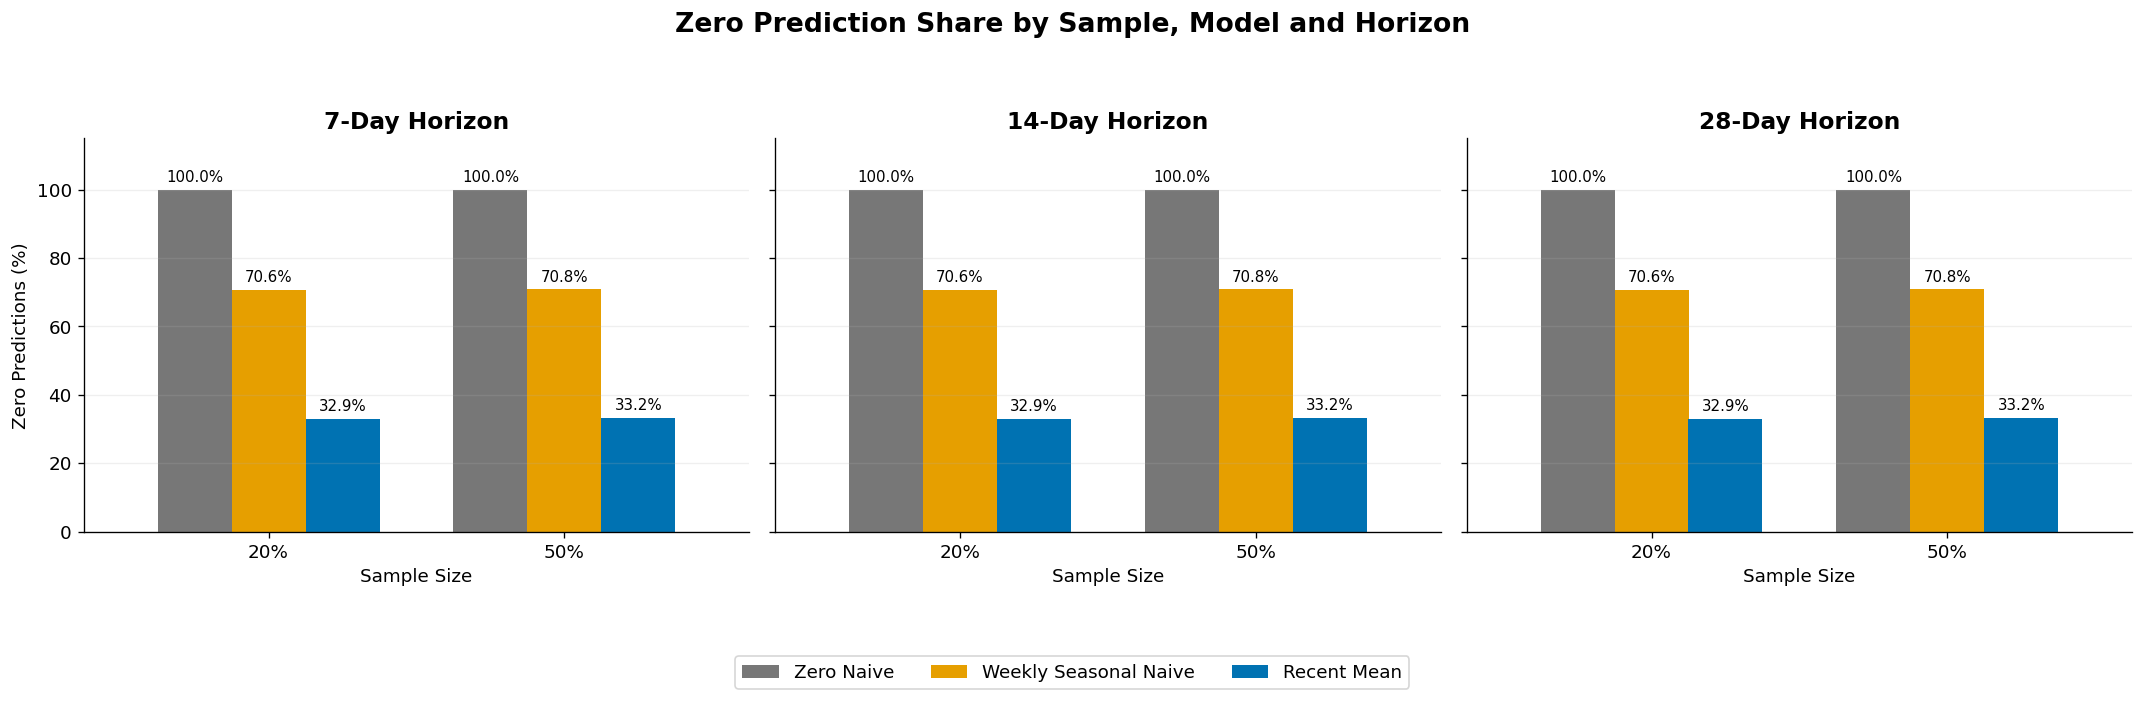

In [ ]:
# Figure 1 — Zero Prediction Share (20% vs 50%, 7/14/28 Days)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

for ax, horizon in zip(axes, HORIZONS):
    data = baseline_summary.query("sample in @SAMPLES and horizon == @horizon")
    pivot = data.pivot(index="sample", columns="model", values="zero_prediction_share").reindex(index=SAMPLES, columns=MODELS) * 100
    pivot.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.75, legend=False)
    ax.set_title(f"{horizon}-Day Horizon", fontweight="bold")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("Zero Predictions (%)")
    ax.set_xticklabels(["20%", "50%"], rotation=0)
    ax.set_ylim(0, 115)
    ax.grid(axis="y", alpha=0.2)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, [MODEL_LABELS[m] for m in MODELS], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Zero Prediction Share by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_zero_share_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 1 Findings — Zero Prediction Share Across Horizons

**Observation:** Zero Naive generates 100% zero predictions across all horizons. Weekly Seasonal Naive produces approximately 70.6%–70.8% zero predictions, compared with 32.9%–33.2% for Recent Mean. The proportions remain unchanged across 7-, 14-, and 28-day horizons, with minimal differences between the 20% and 50% samples.

**Interpretation:** Weekly Seasonal Naive preserves the zero-sales pattern of the most recent seven days, whereas Recent Mean distributes the seven-day average evenly across future days. The three horizons are multiples of seven, explaining the identical zero-prediction shares.

**Business Implication:** Different forecasting methods imply different daily replenishment patterns. Weekly Seasonal Naive produces more zero-demand days, while Recent Mean generates smoother forecasts. These differences may affect inventory planning, but zero-prediction share alone does not measure forecasting accuracy.

**Key Takeaway:** Model assumptions have a much stronger influence on predicted demand sparsity than the choice between the 20% and 50% samples.

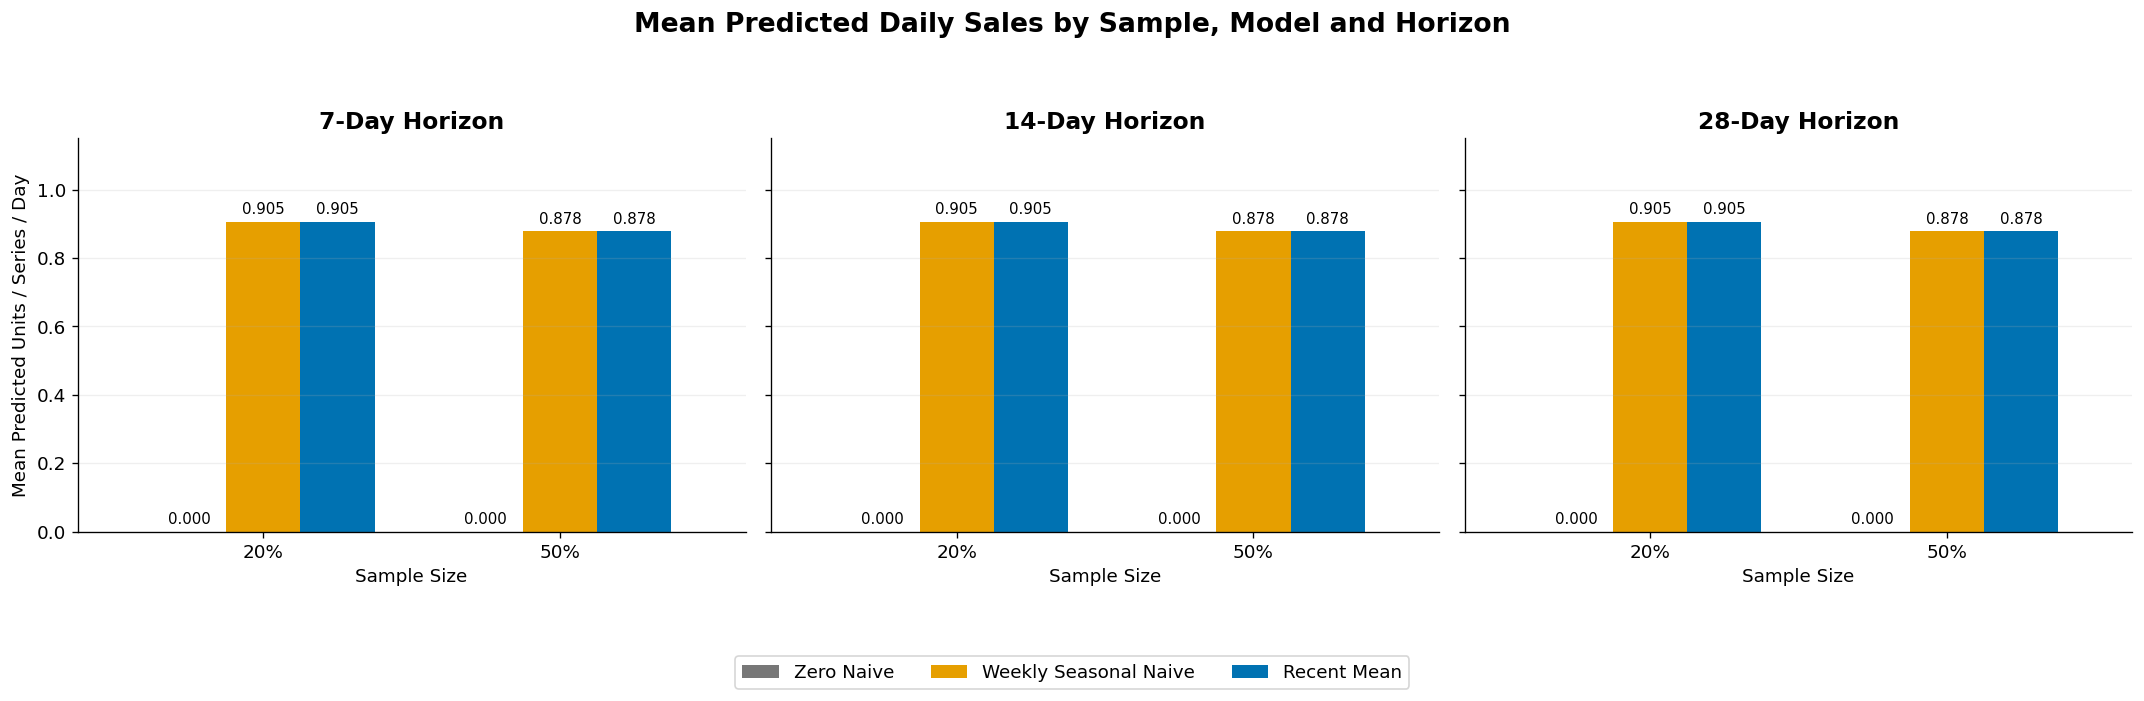

In [ ]:
# Figure 2 — Mean Predicted Daily Sales Across All Horizons
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)

for ax, horizon in zip(axes, HORIZONS):
    data = baseline_summary.query("sample in @SAMPLES and horizon == @horizon")
    pivot = data.pivot(index="sample", columns="model", values="mean_prediction").reindex(index=SAMPLES, columns=MODELS)
    pivot.plot(kind="bar", ax=ax, color=[MODEL_COLORS[m] for m in MODELS], width=0.75, legend=False)
    ax.set_title(f"{horizon}-Day Horizon", fontweight="bold")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("Mean Predicted Units / Series / Day")
    ax.set_xticklabels(["20%", "50%"], rotation=0)
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.2)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

handles, _ = axes[0].get_legend_handles_labels()
fig.legend(handles, [MODEL_LABELS[m] for m in MODELS], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Mean Predicted Daily Sales by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.08, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_mean_prediction_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 2 Findings — Mean Predicted Daily Sales Across Samples and Horizons

**Observation:** Weekly Seasonal Naive and Recent Mean produce identical mean predicted daily sales across all three forecasting horizons. Both models forecast approximately **0.905 units per series per day for the 20% sample** and **0.878 units for the 50% sample**. Zero Naive consistently predicts zero. The 20% sample has approximately 3.1% higher mean predicted daily sales than the 50% sample.

**Interpretation:** The identical mean predictions across the 7-, 14-, and 28-day horizons result from the models' fixed seven-day historical window and the fact that all three horizons are multiples of seven. The small difference between the 20% and 50% samples reflects differences in their sampled series composition.

**Business Implication:** The similar mean predictions across both samples suggest that expanding the sample from 20% to 50% does not substantially change the average forecast volume per product-store series. However, average predicted sales alone cannot establish forecasting accuracy or sample representativeness.

**Key Takeaway:** **Mean predicted daily sales remain constant across all three horizons, with only a small difference between the 20% and 50% samples.**

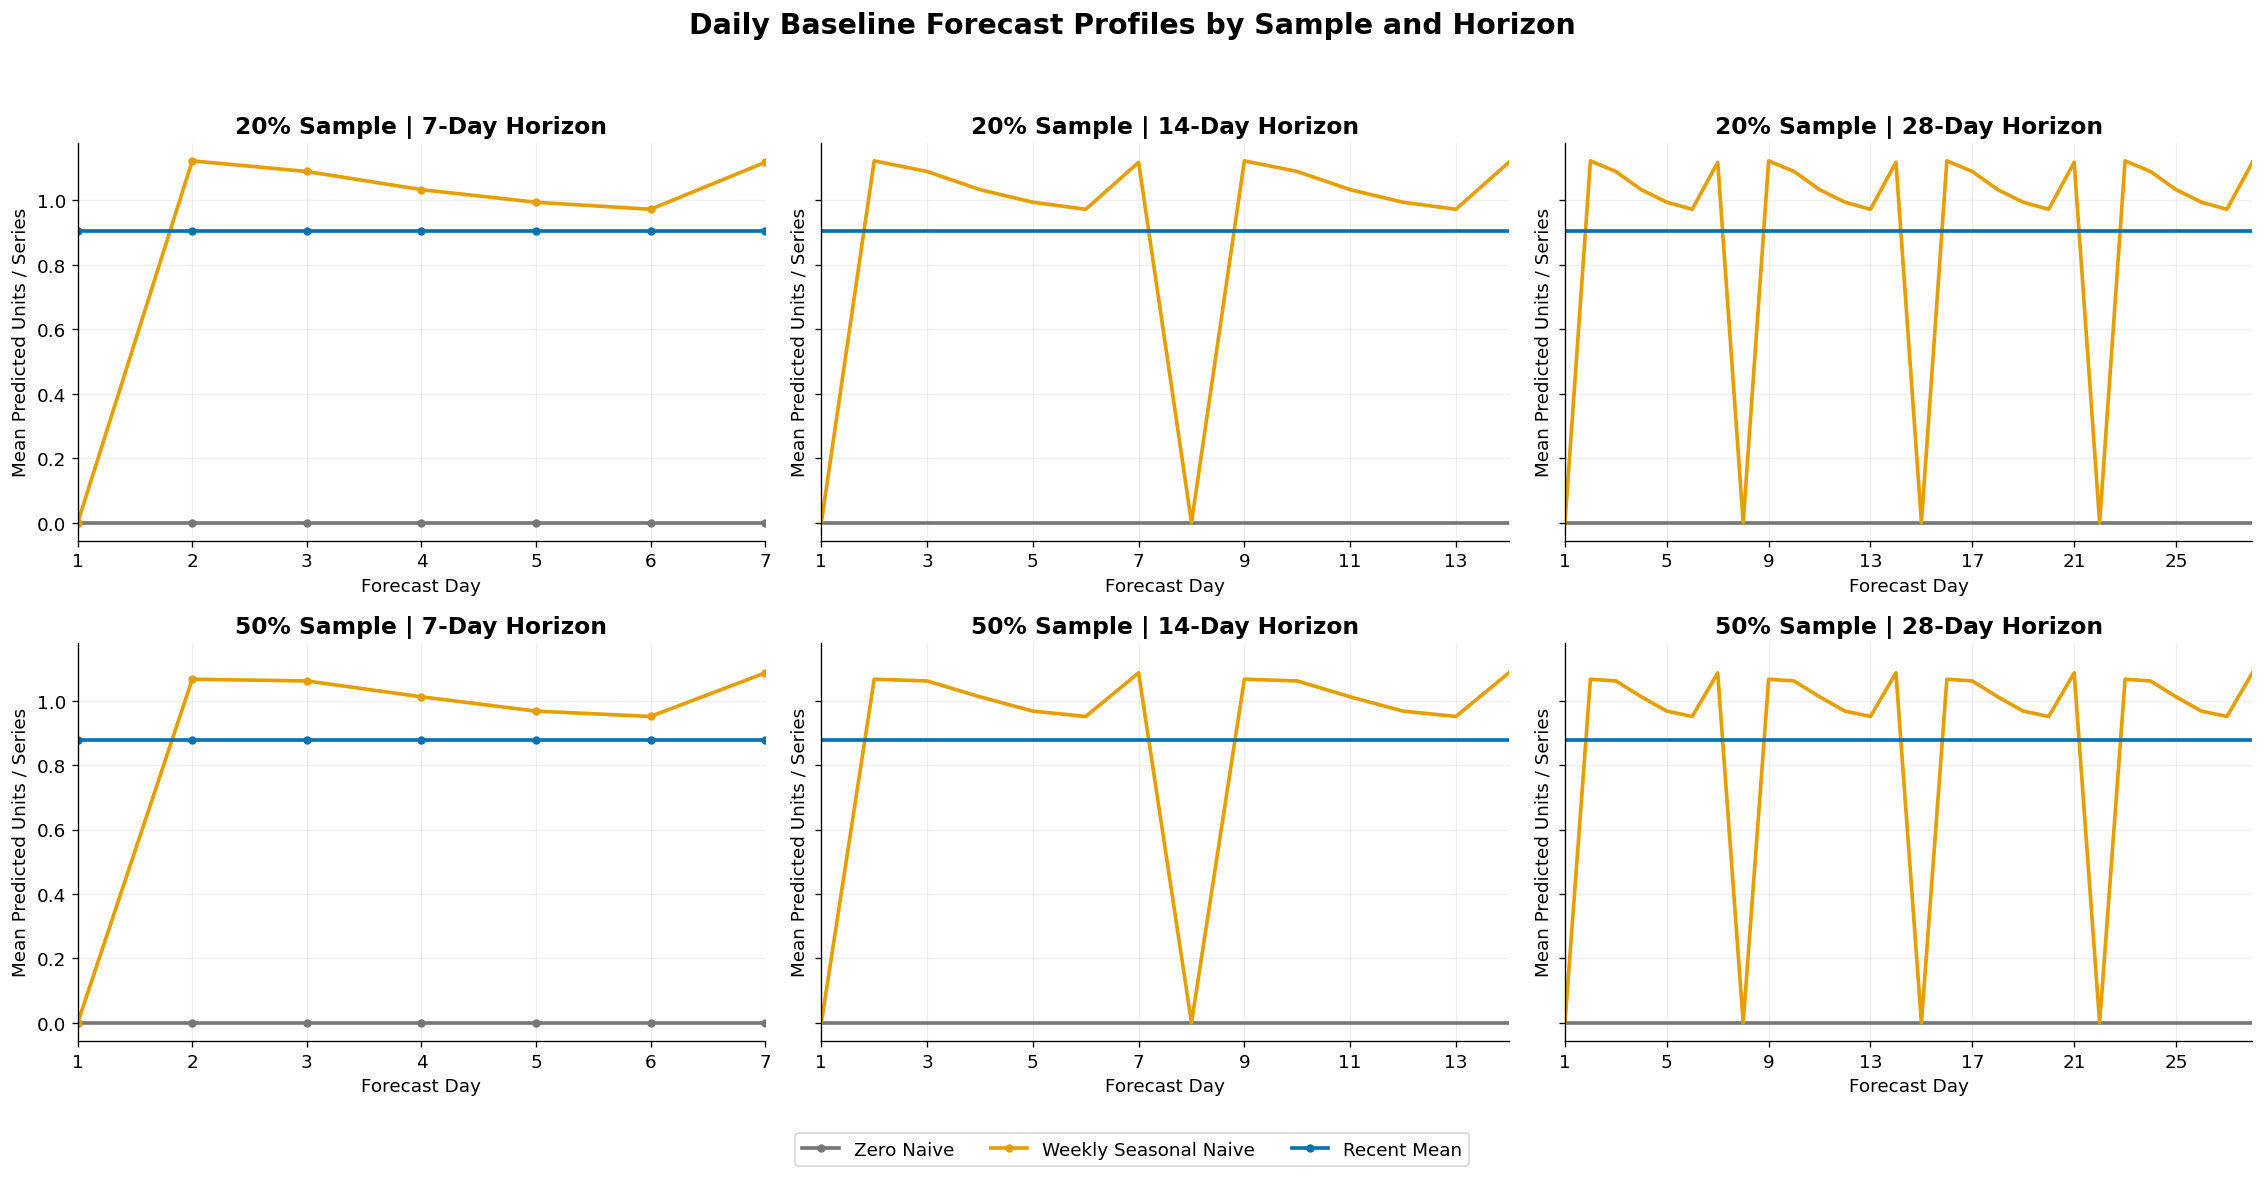

In [ ]:
# Figure 3 — Daily Baseline Forecast Profiles Across All Horizons
fig, axes = plt.subplots(2, 3, figsize=(19, 10), sharey=True)

for i, sample_name in enumerate(SAMPLES):
    for j, horizon in enumerate(HORIZONS):
        ax = axes[i, j]
        for model_name in MODELS:
            forecast = baseline_forecasts[sample_name][horizon][model_name]
            daily_mean = forecast.mean(axis=0)
            ax.plot(np.arange(1, horizon + 1), daily_mean, label=MODEL_LABELS[model_name], color=MODEL_COLORS[model_name], linewidth=2.2, marker="o" if horizon == 7 else None, markersize=4)
        ax.set_title(f"{'20%' if sample_name == 'sample_20' else '50%'} Sample | {horizon}-Day Horizon", fontweight="bold")
        ax.set_xlabel("Forecast Day")
        ax.set_ylabel("Mean Predicted Units / Series")
        ax.set_xlim(1, horizon)
        ax.set_xticks(np.arange(1, horizon + 1, 1 if horizon == 7 else 2 if horizon == 14 else 4))
        ax.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.01))
fig.suptitle("Daily Baseline Forecast Profiles by Sample and Horizon", fontsize=17, fontweight="bold")
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
fig.savefig(Forecasting_OUTPUT / "baseline_daily_profiles_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 3 Findings — Daily Baseline Forecast Profiles Across Samples and Horizons

**Observation:** The three baseline models exhibit distinct daily forecasting patterns across both sampling levels and all three horizons. Zero Naive consistently predicts zero demand, while Recent Mean generates constant daily forecasts of approximately 0.905 units per series for the 20% sample and 0.878 for the 50% sample. In contrast, Weekly Seasonal Naive produces a repeating seven-day pattern, with noticeable fluctuations and zero predictions on forecast days 1, 8, 15, and 22. The 20% and 50% samples display similar forecast profiles.

**Interpretation:** These differences reflect the forecasting assumptions of each model. Zero Naive assumes no future sales, Recent Mean maintains a constant estimate based on the most recent seven days, and Weekly Seasonal Naive directly repeats the historical weekly sales pattern. As the forecast horizon increases from 7 to 28 days, the same patterns are extended without introducing additional trends or adjustments. The recurring zero values in Weekly Seasonal Naive reflect the first position of the historical seven-day pattern used for forecasting.

**Business Implication:** The choice of baseline model influences the expected timing and distribution of demand. Weekly Seasonal Naive reflects historical day-to-day variations, whereas Recent Mean produces a more stable daily demand estimate. These different forecast structures may lead to different daily inventory planning requirements, even when average forecast volumes are similar.

**Key Takeaway:** **Weekly Seasonal Naive preserves a repeating seven-day demand pattern, while Recent Mean produces stable daily forecasts. Both samples show similar model behavior across all three forecasting horizons.**

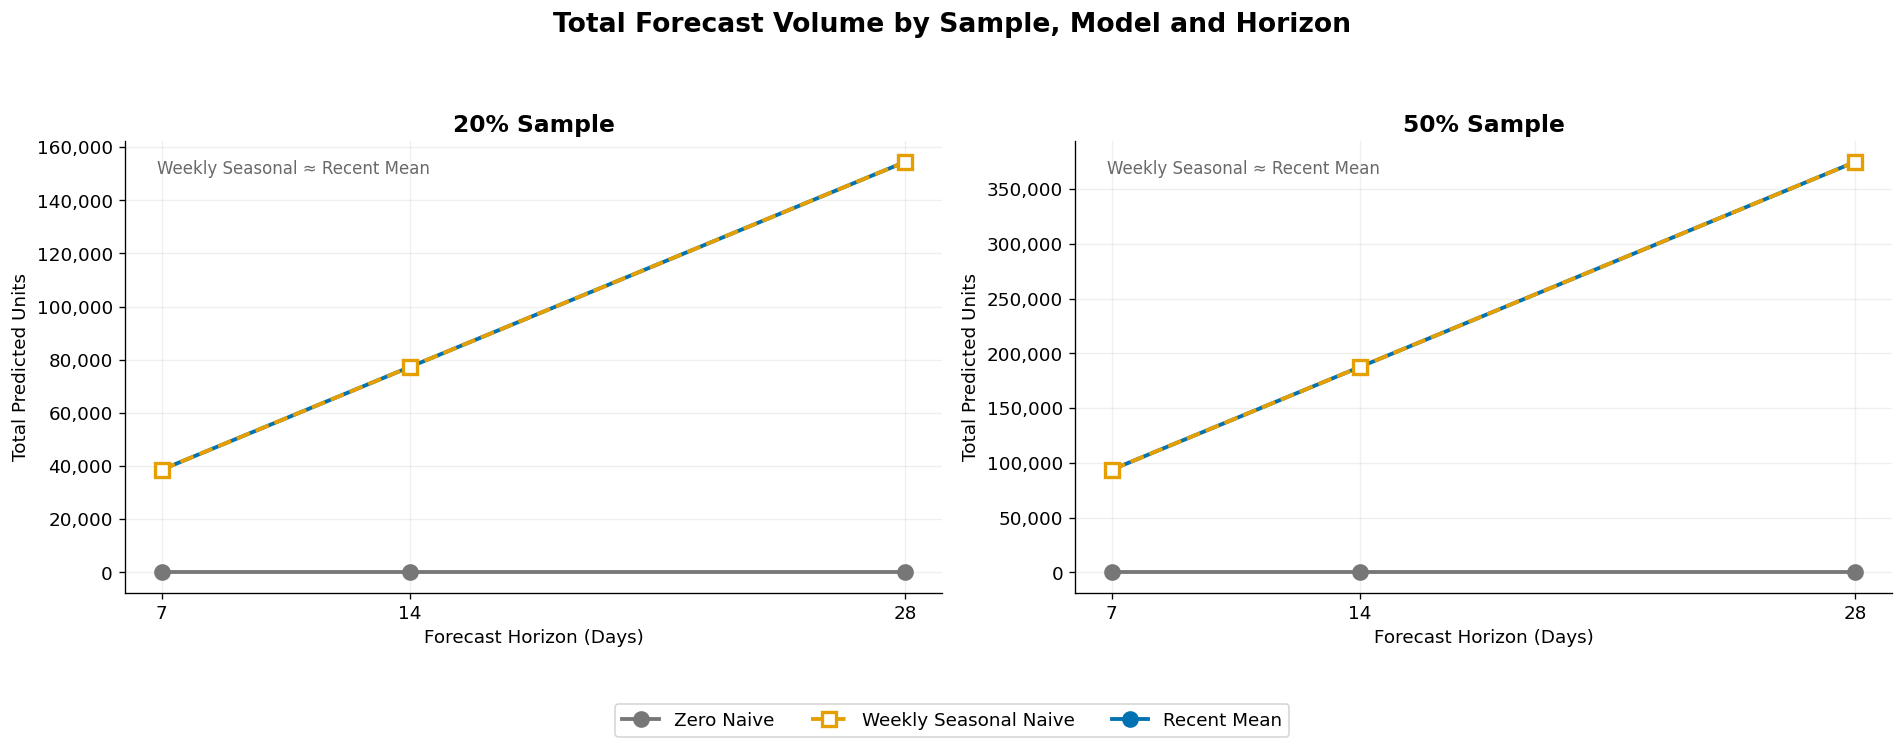

In [ ]:
# Figure 4 — Total Forecast Volume Across Horizons
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, sample_name in zip(axes, SAMPLES):
    data = baseline_summary.query("sample == @sample_name")
    pivot = data.pivot(index="horizon", columns="model", values="total_predicted_units").reindex(index=HORIZONS, columns=MODELS)
    for model_name in MODELS:
        style = {"zero_naive": ("-", "o", 2), "weekly_seasonal_naive": ("--", "s", 4), "recent_mean": ("-", "o", 3)}
        ls, marker, zorder = style[model_name]
        ax.plot(pivot.index, pivot[model_name], label=MODEL_LABELS[model_name], color=MODEL_COLORS[model_name], linestyle=ls, marker=marker, linewidth=2.3, markersize=8, markerfacecolor="white" if model_name == "weekly_seasonal_naive" else MODEL_COLORS[model_name], markeredgewidth=2, zorder=zorder)
    ax.set_title(f"{'20%' if sample_name == 'sample_20' else '50%'} Sample", fontweight="bold")
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_ylabel("Total Predicted Units")
    ax.set_xticks(HORIZONS)
    ax.grid(alpha=0.2)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f"{x:,.0f}"))
    ax.text(0.04, 0.96, "Weekly Seasonal ≈ Recent Mean", transform=ax.transAxes, va="top", fontsize=10, color="dimgray")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Total Forecast Volume by Sample, Model and Horizon", fontsize=16, fontweight="bold")
fig.tight_layout(rect=[0, 0.07, 1, 0.93])
fig.savefig(Forecasting_OUTPUT / "baseline_total_forecast_volume.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Figure 4 Findings — Total Forecast Volume Across Samples and Horizons

**Observation:** Total predicted sales increase linearly as the forecasting horizon extends from 7 to 28 days. For the 20% sample, Weekly Seasonal Naive and Recent Mean predict 38,617 units over 7 days, 77,234 over 14 days, and 154,468 over 28 days. For the 50% sample, the corresponding totals are 93,685, 187,370, and 374,740 units. Both models produce overlapping forecast-volume lines, while Zero Naive consistently predicts zero demand.

**Interpretation:** The linear growth reflects the fixed seven-day forecasting assumptions used by Weekly Seasonal Naive and Recent Mean. Because both models preserve the same total demand over each seven-day period, extending the horizon proportionally increases their aggregate forecasts. The 50% sample generates higher total predicted sales primarily because it contains more product-store series (15,245 versus 6,098).

**Business Implication:** Total forecast volume helps estimate expected demand quantities over different inventory planning horizons. However, comparisons across samples should account for the number of product-store series, since a larger sample naturally produces greater aggregate demand. Forecast volume alone does not indicate which model is more accurate.

**Key Takeaway:** **Total forecast volume grows proportionally with the forecasting horizon, and both nonzero baseline models produce the same aggregate demand estimates.**

In [ ]:
# Metadata Preparation for Group-Level Analysis
metadata = sales.set_index("id")[["state_id", "cat_id"]]
sample20_metadata = metadata.reindex(sample20_ids)
sample50_metadata = metadata.reindex(sample50_ids)

assert not sample20_metadata.isna().any().any(), "Missing metadata in 20% sample."
assert not sample50_metadata.isna().any().any(), "Missing metadata in 50% sample."
print(f"Metadata Validation: PASSED | 20%: {len(sample20_metadata):,} series | 50%: {len(sample50_metadata):,} series")

Metadata Validation: PASSED | 20%: 6,098 series | 50%: 15,245 series


In [ ]:
# Cross-Sample Forecast Consistency Check
idx20 = {sid: i for i, sid in enumerate(sample20_ids)}
idx50 = {sid: i for i, sid in enumerate(sample50_ids)}
assert set(idx20).issubset(set(idx50)), "20% sample is not nested in 50% sample."

consistency_rows = []

for horizon in HORIZONS:
    for model_name in MODELS:
        forecast20 = baseline_forecasts["sample_20"][horizon][model_name]
        forecast50 = baseline_forecasts["sample_50"][horizon][model_name]
        matched50 = forecast50[[idx50[sid] for sid in sample20_ids]]
        passed = np.allclose(forecast20, matched50, rtol=1e-6, atol=1e-6)
        consistency_rows.append({"Horizon": horizon, "Model": MODEL_LABELS[model_name], "Matched Series": len(sample20_ids), "Status": "PASS" if passed else "FAIL"})

consistency_summary = pd.DataFrame(consistency_rows)
display(consistency_summary)
assert (consistency_summary["Status"] == "PASS").all(), "Cross-sample forecast consistency failed."
print(f"Cross-Sample Consistency: {len(consistency_summary)} / {len(consistency_summary)} checks passed.")

,Horizon,Model,Matched Series,Status
0,7,Zero Naive,6098,PASS
1,7,Weekly Seasonal Naive,6098,PASS
2,7,Recent Mean,6098,PASS
3,14,Zero Naive,6098,PASS
4,14,Weekly Seasonal Naive,6098,PASS
5,14,Recent Mean,6098,PASS
6,28,Zero Naive,6098,PASS
7,28,Weekly Seasonal Naive,6098,PASS
8,28,Recent Mean,6098,PASS


Cross-Sample Consistency: 9 / 9 checks passed.


### Cross-Sample Forecast Consistency — Validation

The 20% sample is fully nested within the 50% sample. Forecasts for all 6,098 shared product-store series were compared across the three baseline models and the 7-, 14-, and 28-day horizons.

All nine consistency checks passed, confirming that shared series produce matching forecasts regardless of sample size. This validates the alignment of series identifiers and forecast outputs across the two samples.

In this section, we generated three baseline forecasting models: Zero Naive, Weekly Seasonal Naive, and Recent Mean, using 20% and 50% samples across three forecasting horizons: 7, 14, and 28 days.

We found three key insights.

First, the models handle zero demand differently. Zero Naive always predicts zero sales, while Weekly Seasonal Naive generates around 71% zero predictions, compared with approximately 33% for Recent Mean.

Second, Weekly Seasonal Naive and Recent Mean produce the same average predicted daily sales, but their daily forecast patterns are different. Weekly Seasonal Naive repeats the previous seven-day sales pattern, while Recent Mean produces a constant daily forecast.

Third, the 20% and 50% samples show similar forecasting characteristics across all three horizons. Total forecast volume also increases proportionally as the horizon extends from 7 to 28 days.

The main takeaway is that even when two models predict the same total sales volume, they can distribute demand differently across days. This matters for Walmart because daily demand patterns can influence replenishment scheduling and inventory planning.

At this stage, we are examining forecast behavior rather than accuracy. In the next section, we use rolling-origin evaluation and metrics such as WAPE, MAE, and RMSE to determine which baseline performs better.

# 7.Rolling-Origin Validation

In [ ]:
# Rolling-Origin Backtesting Function
STEP = 7
def rolling_origin_backtest(sales_matrix, day_cols, train_length, horizons=(7, 14, 28), step=7, recent_mean_window=7, season_length=7):
    """Expanding-window backtesting with no test-period leakage."""
    sales_matrix = validate_history(sales_matrix, min_history=max(recent_mean_window, season_length))
    n_series, n_days = sales_matrix.shape

    if len(day_cols) != n_days: raise ValueError("Day columns do not match sales matrix.")
    if not (0 < train_length < n_days): raise ValueError("Invalid training length.")
    if not isinstance(step, (int, np.integer)) or isinstance(step, (bool, np.bool_)) or step <= 0: raise ValueError("Step must be a positive integer.")

    results = []
    first_origin_idx = train_length - 1

    for horizon in horizons:
        validate_horizon(horizon)
        origin_idx = first_origin_idx

        while origin_idx + horizon < n_days:
            history = sales_matrix[:, :origin_idx + 1]
            future_start = origin_idx + 1
            future_end = future_start + horizon
            actual = sales_matrix[:, future_start:future_end]

            assert history.shape[1] == origin_idx + 1
            assert future_start == history.shape[1]
            assert future_start >= train_length
            assert future_end <= n_days
            assert actual.shape == (n_series, horizon)

            forecasts = generate_baselines(history=history, horizon=horizon, recent_mean_window=recent_mean_window, season_length=season_length)

            for model_name, forecast in forecasts.items():
                assert forecast.shape == actual.shape
                errors = forecast.astype(np.float64) - actual.astype(np.float64)
                sum_abs_error = float(np.abs(errors).sum())
                sum_sq_error = float(np.square(errors).sum())
                sum_actual = float(actual.sum(dtype=np.float64))
                n_obs = actual.size
                mae = sum_abs_error / n_obs
                rmse = np.sqrt(sum_sq_error / n_obs)
                wape = sum_abs_error / sum_actual * 100 if sum_actual > 0 else np.nan

                results.append({"origin_day": day_cols[origin_idx], "forecast_start": day_cols[future_start], "forecast_end": day_cols[future_end - 1], "horizon": horizon, "model": model_name, "n_series": n_series, "n_obs": n_obs, "sum_abs_error": sum_abs_error, "sum_sq_error": sum_sq_error, "sum_actual": sum_actual, "MAE": mae, "RMSE": rmse, "WAPE_pct": wape})

            origin_idx += step

    return pd.DataFrame(results)

In [ ]:
# Prepare Backtesting Matrices
sample20_tv = get_sales_split(sales=sales, sample_ids=sample_20_ids, period_cols=train_val_days)
sample50_tv = get_sales_split(sales=sales, sample_ids=sample_50["id"], period_cols=train_val_days)

sample20_matrix = sample20_tv[train_val_days].to_numpy(dtype=np.float32)
sample50_matrix = sample50_tv[train_val_days].to_numpy(dtype=np.float32)

sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}
expected_sizes = {"prototype": 100, "sample_20": 6098, "sample_50": 15245}

assert set(sample_20["id"]).issubset(set(sample_50["id"]))

for sample_name, matrix in sample_matrices.items():
    assert matrix.shape == (expected_sizes[sample_name], len(train_val_days)), f"Invalid matrix: {sample_name}"

matrix_summary = pd.DataFrame([{"Sample": name, "Series": matrix.shape[0], "Days": matrix.shape[1], "Status": "PASS"} for name, matrix in sample_matrices.items()])
display(matrix_summary)

,Sample,Series,Days,Status
0,prototype,100,1798,PASS
1,sample_20,6098,1798,PASS
2,sample_50,15245,1798,PASS


In [ ]:
# Unified Rolling-Origin Validation Function
def validate_backtest(results, sample_name, expected_series, horizons=HORIZONS, step=STEP):
    expected_models = {"zero_naive", "weekly_seasonal_naive", "recent_mean"}
    expected_origins = {h: len(range(len(train_days) - 1, len(train_val_days) - h, step)) for h in horizons}
    expected_rows = sum(expected_origins.values()) * len(expected_models)

    assert len(results) == expected_rows, f"{sample_name}: unexpected model runs."
    assert set(results["model"]) == expected_models
    assert set(results["horizon"]) == set(horizons)
    assert (results["n_series"] == expected_series).all()
    assert (results["n_obs"] == results["n_series"] * results["horizon"]).all()
    assert (results.groupby(["horizon", "origin_day"])["model"].nunique() == len(expected_models)).all()

    for horizon, expected in expected_origins.items():
        subset = results[results["horizon"] == horizon]
        assert subset["origin_day"].nunique() == expected
        assert set(subset["origin_day"]) == set(train_val_days[len(train_days) - 1:len(train_val_days) - horizon:step])

    assert np.isfinite(results[["MAE", "RMSE"]].to_numpy()).all()
    assert (results[["MAE", "RMSE", "sum_abs_error", "sum_sq_error", "sum_actual"]] >= 0).all().all()
    assert np.isfinite(results.loc[results["sum_actual"] > 0, "WAPE_pct"]).all()
    assert (results.loc[results["sum_actual"] > 0, "WAPE_pct"] >= 0).all()
    assert results.loc[results["sum_actual"] == 0, "WAPE_pct"].isna().all()

    assert results["origin_day"].iloc[0] == train_days[-1]
    assert set(results["forecast_start"]).issubset(set(val_days))
    assert set(results["forecast_end"]).issubset(set(val_days))

    return {"Sample": sample_name, "Series": expected_series, "Origins (7/14/28)": " / ".join(str(expected_origins[h]) for h in horizons), "Model Runs": len(results), "Status": "PASS"}

In [ ]:
# Run and Validate All Samples
backtest_results_all = {}
validation_rows = []

for sample_name, matrix in sample_matrices.items():
    results = rolling_origin_backtest(sales_matrix=matrix, day_cols=train_val_days, train_length=len(train_days), horizons=HORIZONS, step=STEP, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH)
    backtest_results_all[sample_name] = results
    validation_rows.append(validate_backtest(results, sample_name, matrix.shape[0]))

backtest_results = backtest_results_all["prototype"]
backtest_results_20 = backtest_results_all["sample_20"]
backtest_results_50 = backtest_results_all["sample_50"]

backtest_validation_summary = pd.DataFrame(validation_rows)
display(backtest_validation_summary)
print("Rolling-Origin Validation: ALL PASSED")

,Sample,Series,Origins (7/14/28),Model Runs,Status
0,prototype,100,52 / 51 / 49,456,PASS
1,sample_20,6098,52 / 51 / 49,456,PASS
2,sample_50,15245,52 / 51 / 49,456,PASS


Rolling-Origin Validation: ALL PASSED


In [ ]:
sample_matrices = {"prototype": prototype_matrix, "sample_20": sample20_matrix, "sample_50": sample50_matrix}

In [ ]:
# Export Rolling-Origin Backtesting Results
export_names = {"prototype": "rolling_origin_metrics_prototype.csv", "sample_20": "rolling_origin_metrics_20.csv", "sample_50": "rolling_origin_metrics_50.csv"}

for sample_name, results in backtest_results_all.items():
    output_path = Forecasting_OUTPUT / export_names[sample_name]
    results.to_csv(output_path, index=False)
    print(f"Saved: {output_path.name} | {len(results)} rows")

Saved: rolling_origin_metrics_prototype.csv | 456 rows
Saved: rolling_origin_metrics_20.csv | 456 rows
Saved: rolling_origin_metrics_50.csv | 456 rows



### **Findings — Prototype, 20%, and 50% Sample Backtesting Validation**

The expanding-window rolling-origin backtesting pipeline was successfully validated on three sample sizes: the 100-series prototype, the 20% stratified sample (6,098 series), and the 50% stratified sample (15,245 series).

All three samples completed **456 model evaluations** across three forecasting horizons (7, 14, and 28 days) and three baseline models (Zero Naive, Weekly Seasonal Naive, and Recent Mean). The 20% sample was also confirmed to be fully nested within the 50% sample.

All validation checks passed, including sample size, model coverage, expected forecast origins, finite and non-negative error metrics, and forecast dates remaining within the validation period. The same forecasting and evaluation pipeline was applied consistently across all three sample sizes without changing the underlying methodology.

The backtesting results were exported separately for each sample size to support reproducibility, model comparison, and downstream RAG/Streamlit integration.

**Key takeaway:** The forecasting pipeline successfully scales from 100 to 15,245 series while maintaining consistent evaluation procedures. However, passing these validation checks confirms the integrity of the backtesting process, not forecasting accuracy. The next step is to compare aggregated MAE, RMSE, WAPE, Forecast Bias, and Forecast Value Added (FVA) across models, horizons, and sample sizes, followed by probabilistic forecasting evaluation using prediction intervals.

# 8.Horizon Evaluation

### **100 series Sample Train / Validation / Test**

In [ ]:
#Aggregate evaluation metrics
evaluation_summary = (
    backtest_results.groupby(["horizon", "model"],as_index=False)
    .agg(
        n_origins=("origin_day", "nunique"),
        n_observations=("n_obs", "sum"),
        total_abs_error=("sum_abs_error", "sum"),
        total_sq_error=("sum_sq_error", "sum"),
        total_actual=("sum_actual", "sum")
    )
)

# Pooled MAE
evaluation_summary["MAE"] = (
    evaluation_summary["total_abs_error"]
    / evaluation_summary["n_observations"]
)

# Pooled RMSE
evaluation_summary["RMSE"] = np.sqrt(
    evaluation_summary["total_sq_error"]
    / evaluation_summary["n_observations"]
)

# Pooled WAPE
evaluation_summary["WAPE_pct"] = np.where(
    evaluation_summary["total_actual"] > 0,
    evaluation_summary["total_abs_error"]
    / evaluation_summary["total_actual"]
    * 100,
    np.nan
)

# Show the most useful columns
evaluation_table = evaluation_summary[["horizon","model","n_origins","n_observations","MAE","RMSE","WAPE_pct"]].copy()
display(evaluation_table.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,36400,0.8128,1.7240,95.0249
1,7,weekly_seasonal_naive,52,36400,0.9504,2.2163,111.1097
2,7,zero_naive,52,36400,0.8554,2.2929,100.0000
3,14,recent_mean,51,71400,0.8249,1.7706,96.0766
4,14,weekly_seasonal_naive,51,71400,0.9605,2.2501,111.8689
5,14,zero_naive,51,71400,0.8586,2.2972,100.0000
6,28,recent_mean,49,137200,0.8390,1.8184,97.3810
7,28,weekly_seasonal_naive,49,137200,0.9698,2.2852,112.5572
8,28,zero_naive,49,137200,0.8616,2.2998,100.0000


In [ ]:
#Rank baseline models by horizon
# Rank models within each horizon
# Lower WAPE is better
ranked_models = evaluation_table.sort_values(["horizon", "WAPE_pct"],ascending=[True, True]).copy()
ranked_models["rank"] = (ranked_models.groupby("horizon").cumcount()+ 1)
display(ranked_models[["horizon","rank","model","MAE","RMSE","WAPE_pct"]].round(4))

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.8128,1.7240,95.0249
2,7,2,zero_naive,0.8554,2.2929,100.0000
1,7,3,weekly_seasonal_naive,0.9504,2.2163,111.1097
3,14,1,recent_mean,0.8249,1.7706,96.0766
5,14,2,zero_naive,0.8586,2.2972,100.0000
4,14,3,weekly_seasonal_naive,0.9605,2.2501,111.8689
6,28,1,recent_mean,0.8390,1.8184,97.3810
8,28,2,zero_naive,0.8616,2.2998,100.0000
7,28,3,weekly_seasonal_naive,0.9698,2.2852,112.5572


In [ ]:
#Identify best baseline per horizon
# Select the lowest-WAPE baseline for each horizon
best_baselines = (ranked_models.loc[ranked_models["rank"] == 1].copy())
print("Best baseline by horizon:")
display(best_baselines[["horizon", "model", "WAPE_pct"]].round(4))

Best baseline by horizon:


,horizon,model,WAPE_pct
0,7,recent_mean,95.0249
3,14,recent_mean,96.0766
6,28,recent_mean,97.3810


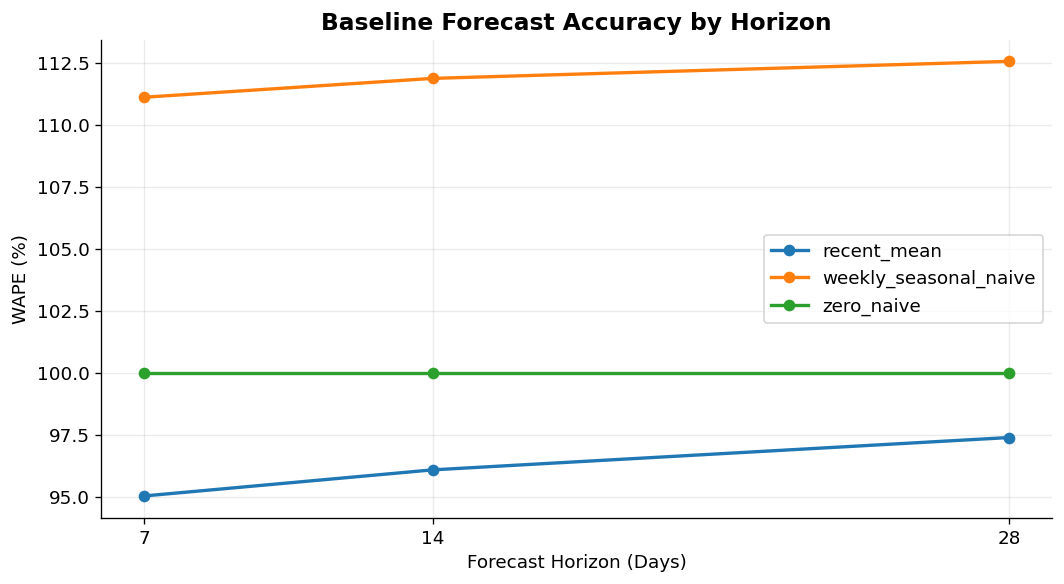

In [ ]:
#Visualize model comparison
# Compare WAPE across horizons
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, group in evaluation_table.groupby("model"):
    group = group.sort_values("horizon")
    ax.plot(group["horizon"],group["WAPE_pct"],marker="o",linewidth=2,label=model_name)
ax.set_title("Baseline Forecast Accuracy by Horizon")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("WAPE (%)")
ax.set_xticks(HORIZONS)
ax.legend()
ax.grid(alpha=0.25)
save_chart()

In [ ]:
#Save evaluation outputs
evaluation_table.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics.csv",index=False)
ranked_models.to_csv(Forecasting_OUTPUT / "baseline_model_rankings.csv",index=False)
best_baselines.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon.csv",index=False)
print("Evaluation outputs saved to:", Forecasting_OUTPUT)

Evaluation outputs saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


###**Preliminary Findings — 100-Series Prototype**

**Scope:** The initial evaluation was conducted on a 100-series prototype using rolling-origin validation across 7-, 14-, and 28-day forecasting horizons. Three baseline models were compared: Zero Naive, Weekly Seasonal Naive, and Recent Mean.

**Key Findings**

Recent Mean performed best across all three forecasting horizons. Its WAPE increased from 95.02% for the 7-day horizon to 96.08% for 14 days and 97.38% for 28 days.

Weekly Seasonal Naive underperformed the other baselines. Its WAPE ranged from 111.11% to 112.56%, suggesting that simply repeating the previous week's sales pattern was ineffective for this prototype.

Forecasting errors remained high across all models. Even the best-performing baseline had WAPE above 95%, indicating substantial room for improvement.

Zero-demand predictions were common. Weekly Seasonal Naive generated approximately 76.29% zero predictions, compared with 36.00% for Recent Mean in the prediction summary. This suggests that sparse or intermittent demand may be an important factor to investigate.

**Limitations**

These findings are preliminary and based on a small 100-series prototype designed primarily to validate the forecasting pipeline. The prototype is not sufficient to establish representative forecasting performance across the full M5 dataset. Differences across forecasting horizons may also reflect differences in evaluation windows.

**Next Steps**

Expand the evaluation to the 20% stratified sample (6,098 series).

Analyze forecasting errors by category, state, and demand pattern.

Investigate the impact of zero sales and intermittent demand.

Use the expanded evaluation to assess baseline suitability for inventory planning.

###**20% Sample Train / Validation / Test**

---



In [ ]:
# Prepare chronological splits for the 20% sample

sample20_train = get_sales_split(sales, sample_20_ids, train_days)
sample20_val = get_sales_split(sales, sample_20_ids, val_days)
sample20_test = get_sales_split(sales, sample_20_ids, test_days)
print("Train:", sample20_train.shape)
print("Validation:", sample20_val.shape)
print("Test:", sample20_test.shape)

Train: (6098, 1439)
Validation: (6098, 371)
Test: (6098, 149)


In [ ]:
### 20% Sample Horizon Evaluation
# Aggregate evaluation metrics for the 20% sample

evaluation_20 = (
    backtest_results_20
    .groupby(["horizon", "model"], as_index=False)
    .agg(
        n_origins=("origin_day", "nunique"),
        n_observations=("n_obs", "sum"),
        sum_abs_error=("sum_abs_error", "sum"),
        sum_sq_error=("sum_sq_error", "sum"),
        sum_actual=("sum_actual", "sum")
    )
)

evaluation_20["MAE"] = (
    evaluation_20["sum_abs_error"]
    / evaluation_20["n_observations"]
)

evaluation_20["RMSE"] = np.sqrt(
    evaluation_20["sum_sq_error"]
    / evaluation_20["n_observations"]
)

evaluation_20["WAPE_pct"] = np.where(
    evaluation_20["sum_actual"] > 0,
    evaluation_20["sum_abs_error"]
    / evaluation_20["sum_actual"] * 100,
    np.nan
)

evaluation_20 = evaluation_20[
    ["horizon", "model", "n_origins",
     "n_observations", "MAE", "RMSE", "WAPE_pct"]
].sort_values(["horizon", "WAPE_pct"])

display(evaluation_20.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,2219672,0.9722,2.3214,76.4770
1,7,weekly_seasonal_naive,52,2219672,1.1433,2.8827,89.9398
2,7,zero_naive,52,2219672,1.2712,3.8636,100.0000
3,14,recent_mean,51,4353972,0.9952,2.3942,78.0601
4,14,weekly_seasonal_naive,51,4353972,1.1645,2.9483,91.3447
5,14,zero_naive,51,4353972,1.2749,3.8689,100.0000
6,28,recent_mean,49,8366456,1.0230,2.4859,80.0777
7,28,weekly_seasonal_naive,49,8366456,1.1881,3.0163,93.0013
8,28,zero_naive,49,8366456,1.2775,3.8713,100.0000


In [ ]:
# Rank baseline models by horizon — 20% sample
# Lower WAPE is better

ranked_models_20 = (
    evaluation_20
    .sort_values(
        ["horizon", "WAPE_pct"],
        ascending=[True, True]
    )
    .copy()
)

ranked_models_20["rank"] = (
    ranked_models_20.groupby("horizon").cumcount() + 1
)

display(
    ranked_models_20[
        ["horizon", "rank", "model", "MAE", "RMSE", "WAPE_pct"]
    ].round(4)
)

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.9722,2.3214,76.4770
1,7,2,weekly_seasonal_naive,1.1433,2.8827,89.9398
2,7,3,zero_naive,1.2712,3.8636,100.0000
3,14,1,recent_mean,0.9952,2.3942,78.0601
4,14,2,weekly_seasonal_naive,1.1645,2.9483,91.3447
5,14,3,zero_naive,1.2749,3.8689,100.0000
6,28,1,recent_mean,1.0230,2.4859,80.0777
7,28,2,weekly_seasonal_naive,1.1881,3.0163,93.0013
8,28,3,zero_naive,1.2775,3.8713,100.0000


In [ ]:
# Identify best baseline per horizon — 20% sample
best_baselines_20 = ranked_models_20.loc[
    ranked_models_20["rank"] == 1
].copy()

print("Best baseline by horizon — 20% sample:")
display(
    best_baselines_20[
        ["horizon", "model", "MAE", "RMSE", "WAPE_pct"]
    ].round(4)
)

Best baseline by horizon — 20% sample:


,horizon,model,MAE,RMSE,WAPE_pct
0,7,recent_mean,0.9722,2.3214,76.4770
3,14,recent_mean,0.9952,2.3942,78.0601
6,28,recent_mean,1.0230,2.4859,80.0777


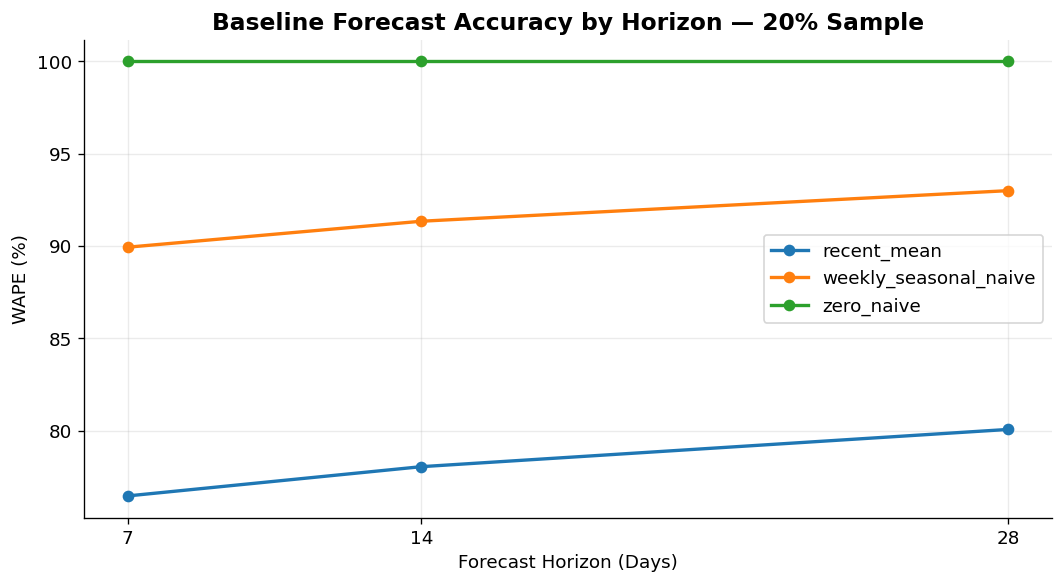

In [ ]:
# Visualize model comparison — 20% sample
# Compare WAPE across forecasting horizons
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, group in evaluation_20.groupby("model"):
    group = group.sort_values("horizon")
    ax.plot(group["horizon"],group["WAPE_pct"],marker="o",linewidth=2,label=model_name)
ax.set_title("Baseline Forecast Accuracy by Horizon — 20% Sample")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("WAPE (%)")
ax.set_xticks(HORIZONS)
ax.legend()
ax.grid(alpha=0.25)

save_chart()

In [ ]:
# Save 20% sample evaluation outputs
evaluation_20.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_20.csv",index=False)
ranked_models_20.to_csv(Forecasting_OUTPUT / "baseline_model_rankings_20.csv",index=False)
best_baselines_20.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon_20.csv",index=False)
print("20% sample evaluation outputs saved to:", Forecasting_OUTPUT)

20% sample evaluation outputs saved to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:
# Aggregate evaluation metrics for the 50% sample
evaluation_50 = backtest_results_50.groupby(["horizon","model"],as_index=False).agg(n_origins=("origin_day","nunique"),n_observations=("n_obs","sum"),total_abs_error=("sum_abs_error","sum"),total_sq_error=("sum_sq_error","sum"),total_actual=("sum_actual","sum"))

evaluation_50["MAE"] = evaluation_50["total_abs_error"] / evaluation_50["n_observations"]
evaluation_50["RMSE"] = np.sqrt(evaluation_50["total_sq_error"] / evaluation_50["n_observations"])
evaluation_50["WAPE_pct"] = np.where(evaluation_50["total_actual"] > 0,evaluation_50["total_abs_error"] / evaluation_50["total_actual"] * 100,np.nan)

evaluation_50 = evaluation_50[["horizon","model","n_origins","n_observations","MAE","RMSE","WAPE_pct"]].sort_values(["horizon","WAPE_pct"])
display(evaluation_50.round(4))

,horizon,model,n_origins,n_observations,MAE,RMSE,WAPE_pct
0,7,recent_mean,52,5549180,0.9543,2.2226,77.5216
1,7,weekly_seasonal_naive,52,5549180,1.1217,2.7529,91.1185
2,7,zero_naive,52,5549180,1.2310,3.6717,100.0000
3,14,recent_mean,51,10884930,0.9763,2.2949,79.0587
4,14,weekly_seasonal_naive,51,10884930,1.1412,2.8161,92.4116
5,14,zero_naive,51,10884930,1.2349,3.6775,100.0000
6,28,recent_mean,49,20916140,1.0030,2.3811,81.0121
7,28,weekly_seasonal_naive,49,20916140,1.1640,2.8823,94.0158
8,28,zero_naive,49,20916140,1.2381,3.6820,100.0000


In [ ]:
# Rank 50% baseline models
ranked_models_50 = evaluation_50.sort_values(["horizon","WAPE_pct"]).copy()
ranked_models_50["rank"] = ranked_models_50.groupby("horizon").cumcount() + 1
best_baselines_50 = ranked_models_50[ranked_models_50["rank"] == 1].copy()

display(ranked_models_50[["horizon","rank","model","MAE","RMSE","WAPE_pct"]].round(4))

,horizon,rank,model,MAE,RMSE,WAPE_pct
0,7,1,recent_mean,0.9543,2.2226,77.5216
1,7,2,weekly_seasonal_naive,1.1217,2.7529,91.1185
2,7,3,zero_naive,1.2310,3.6717,100.0000
3,14,1,recent_mean,0.9763,2.2949,79.0587
4,14,2,weekly_seasonal_naive,1.1412,2.8161,92.4116
5,14,3,zero_naive,1.2349,3.6775,100.0000
6,28,1,recent_mean,1.0030,2.3811,81.0121
7,28,2,weekly_seasonal_naive,1.1640,2.8823,94.0158
8,28,3,zero_naive,1.2381,3.6820,100.0000


In [ ]:
# Compare sample sizes using identical evaluation methodology
comparison_20_50 = pd.concat([evaluation_20.assign(sample="20%",n_series=6098),evaluation_50.assign(sample="50%",n_series=15245)],ignore_index=True)

display(comparison_20_50[["sample","n_series","horizon","model","MAE","RMSE","WAPE_pct"]].sort_values(["horizon","model","sample"]).round(4))

,sample,n_series,horizon,model,MAE,RMSE,WAPE_pct
0,20%,6098,7,recent_mean,0.9722,2.3214,76.4770
9,50%,15245,7,recent_mean,0.9543,2.2226,77.5216
1,20%,6098,7,weekly_seasonal_naive,1.1433,2.8827,89.9398
10,50%,15245,7,weekly_seasonal_naive,1.1217,2.7529,91.1185
2,20%,6098,7,zero_naive,1.2712,3.8636,100.0000
11,50%,15245,7,zero_naive,1.2310,3.6717,100.0000
3,20%,6098,14,recent_mean,0.9952,2.3942,78.0601
12,50%,15245,14,recent_mean,0.9763,2.2949,79.0587
4,20%,6098,14,weekly_seasonal_naive,1.1645,2.9483,91.3447
13,50%,15245,14,weekly_seasonal_naive,1.1412,2.8161,92.4116


In [ ]:
# Calculate FVA relative to Weekly Seasonal Naive
kpi_fva = pd.concat([evaluation_table.assign(sample="prototype"),evaluation_20.assign(sample="20%"),evaluation_50.assign(sample="50%")],ignore_index=True)

reference = kpi_fva[kpi_fva["model"] == "weekly_seasonal_naive"][["sample","horizon","WAPE_pct"]].rename(columns={"WAPE_pct":"reference_WAPE_pct"})
kpi_fva = kpi_fva.merge(reference,on=["sample","horizon"],how="left",validate="many_to_one")
kpi_fva["FVA_pct"] = np.where(kpi_fva["reference_WAPE_pct"] > 0,(kpi_fva["reference_WAPE_pct"] - kpi_fva["WAPE_pct"]) / kpi_fva["reference_WAPE_pct"] * 100,np.nan)

display(kpi_fva[["sample","horizon","model","WAPE_pct","reference_WAPE_pct","FVA_pct"]].sort_values(["sample","horizon","FVA_pct"],ascending=[True,True,False]).round(4))

,sample,horizon,model,WAPE_pct,reference_WAPE_pct,FVA_pct
9,20%,7,recent_mean,76.4770,89.9398,14.9687
10,20%,7,weekly_seasonal_naive,89.9398,89.9398,0.0000
11,20%,7,zero_naive,100.0000,89.9398,-11.1855
12,20%,14,recent_mean,78.0601,91.3447,14.5433
13,20%,14,weekly_seasonal_naive,91.3447,91.3447,0.0000
14,20%,14,zero_naive,100.0000,91.3447,-9.4755
15,20%,28,recent_mean,80.0777,93.0013,13.8961
16,20%,28,weekly_seasonal_naive,93.0013,93.0013,0.0000
17,20%,28,zero_naive,100.0000,93.0013,-7.5254
18,50%,7,recent_mean,77.5216,91.1185,14.9222


In [ ]:
# Export evaluation and FVA outputs
evaluation_50.to_csv(Forecasting_OUTPUT / "baseline_evaluation_metrics_50.csv",index=False)
ranked_models_50.to_csv(Forecasting_OUTPUT / "baseline_model_rankings_50.csv",index=False)
best_baselines_50.to_csv(Forecasting_OUTPUT / "best_baseline_by_horizon_50.csv",index=False)
comparison_20_50.to_csv(Forecasting_OUTPUT / "sample_comparison_20_50.csv",index=False)
kpi_fva.to_csv(Forecasting_OUTPUT / "forecast_value_added_kpi.csv",index=False)

print("50% evaluation, sample comparison, and FVA exported successfully.")

50% evaluation, sample comparison, and FVA exported successfully.


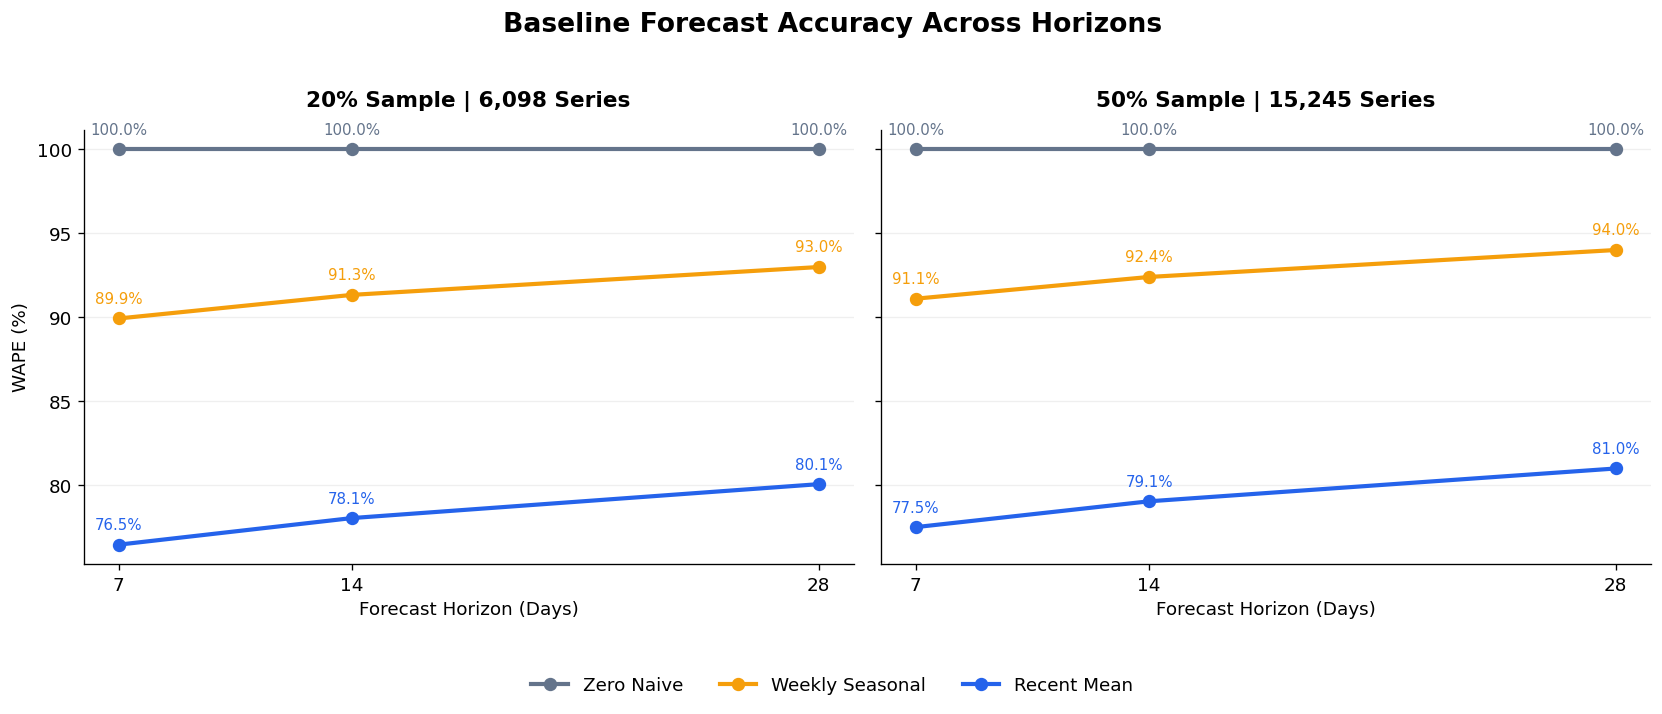

In [ ]:
# Figure 5 — Baseline WAPE by Horizon: 20% vs. 50%
model_order = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
model_labels = {"zero_naive": "Zero Naive", "weekly_seasonal_naive": "Weekly Seasonal", "recent_mean": "Recent Mean"}
model_colors = {"zero_naive": "#64748B", "weekly_seasonal_naive": "#F59E0B", "recent_mean": "#2563EB"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for ax, (sample_name, df, n_series) in zip(axes, [("20% Sample", evaluation_20, 6098), ("50% Sample", evaluation_50, 15245)]):
    for model in model_order:
        group = df[df["model"] == model].sort_values("horizon")
        ax.plot(group["horizon"], group["WAPE_pct"], marker="o", markersize=7, linewidth=2.5, color=model_colors[model], label=model_labels[model])
        for x, y in zip(group["horizon"], group["WAPE_pct"]):
            ax.annotate(f"{y:.1f}%", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=model_colors[model])
    ax.set_title(f"{sample_name} | {n_series:,} Series", fontsize=13, fontweight="bold", pad=14)
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_xticks(HORIZONS)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("WAPE (%)")
fig.suptitle("Baseline Forecast Accuracy Across Horizons", fontsize=16, fontweight="bold", y=1.02)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig(Forecasting_OUTPUT / "figure5_baseline_wape_by_horizon.png", dpi=300, bbox_inches="tight")
plt.show()

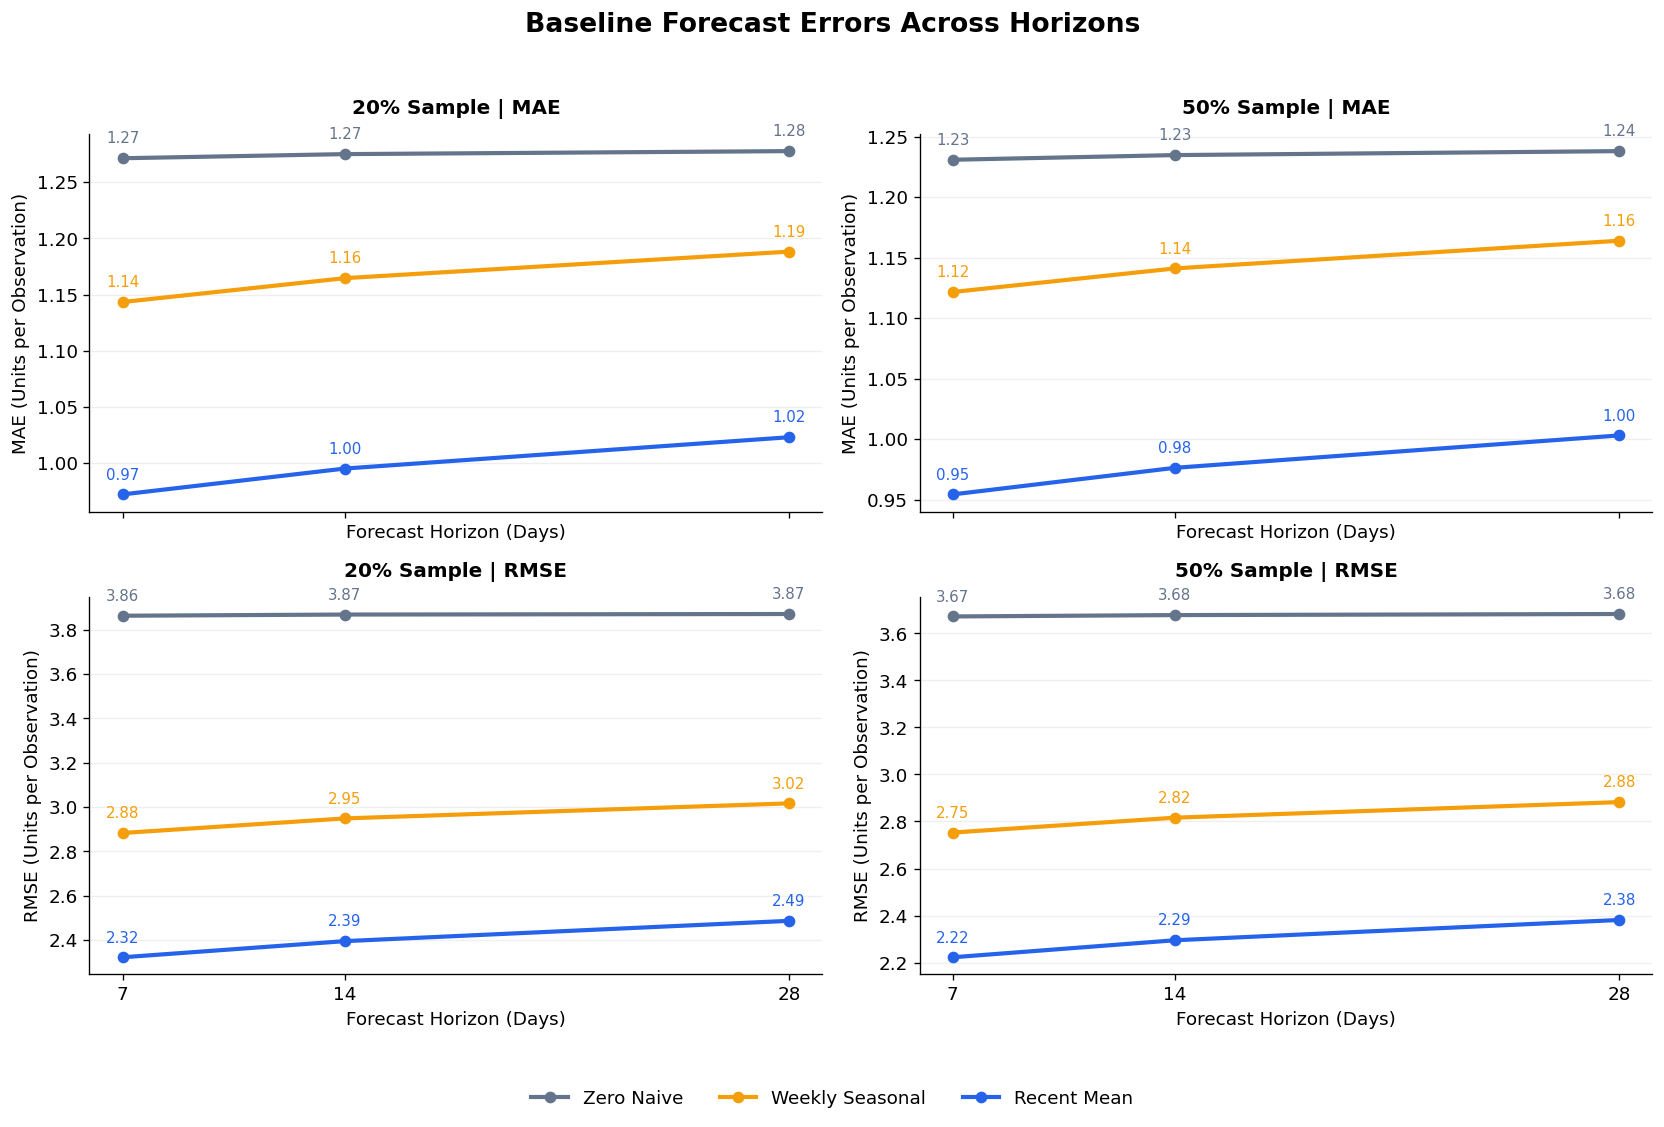

In [ ]:
# Figure 6 — MAE and RMSE by Horizon: 20% vs. 50%
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)

for col, (sample_name, df, n_series) in enumerate([("20% Sample", evaluation_20, 6098), ("50% Sample", evaluation_50, 15245)]):
    for row, metric in enumerate(["MAE", "RMSE"]):
        ax = axes[row, col]
        for model in model_order:
            group = df[df["model"] == model].sort_values("horizon")
            ax.plot(group["horizon"], group[metric], marker="o", markersize=6, linewidth=2.5, color=model_colors[model], label=model_labels[model])
            for x, y in zip(group["horizon"], group[metric]):
                ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9, color=model_colors[model])
        ax.set_title(f"{sample_name} | {metric}", fontsize=12, fontweight="bold", pad=12)
        ax.set_xticks(HORIZONS)
        ax.set_xlabel("Forecast Horizon (Days)")
        ax.set_ylabel(f"{metric} (Units per Observation)")
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Baseline Forecast Errors Across Horizons", fontsize=16, fontweight="bold", y=1.02)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])
fig.savefig(Forecasting_OUTPUT / "figure6_baseline_mae_rmse_by_horizon.png", dpi=300, bbox_inches="tight")
plt.show()

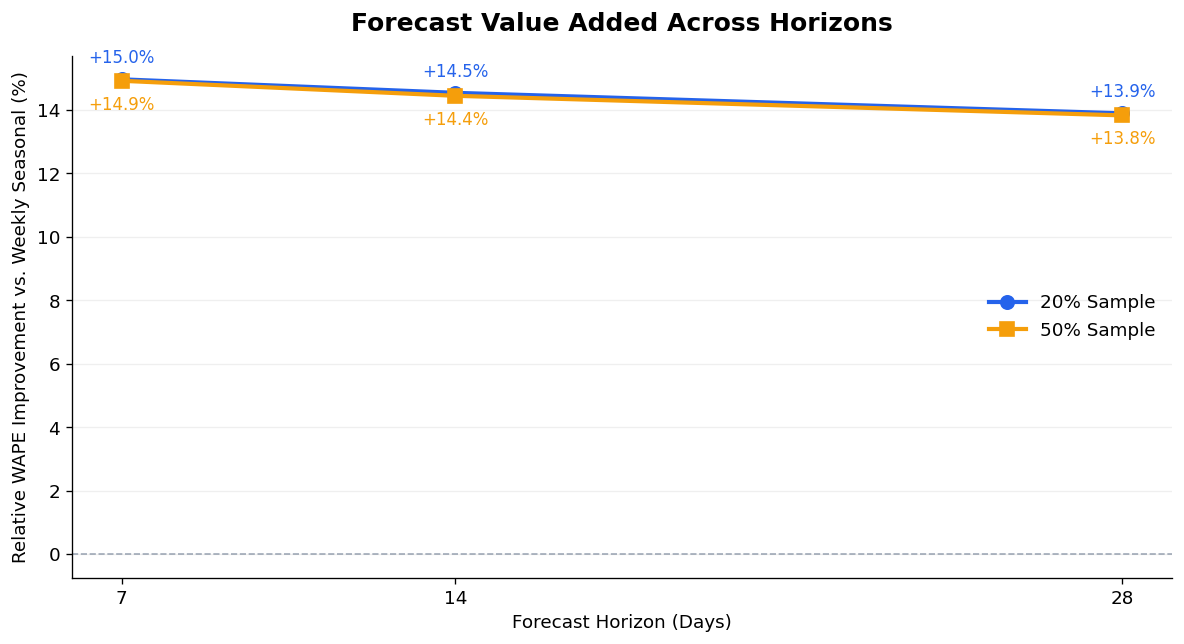

In [ ]:
# Figure 7 — Forecast Value Added: Recent Mean vs. Weekly Seasonal
fig, ax = plt.subplots(figsize=(10, 5.5))

for sample_name, df, color, marker in [("20% Sample", evaluation_20, "#2563EB", "o"), ("50% Sample", evaluation_50, "#F59E0B", "s")]:
    pivot = df.pivot(index="horizon", columns="model", values="WAPE_pct").sort_index()
    fva = (pivot["weekly_seasonal_naive"] - pivot["recent_mean"]) / pivot["weekly_seasonal_naive"] * 100
    ax.plot(fva.index, fva.values, marker=marker, markersize=8, linewidth=2.5, color=color, label=sample_name)
    for x, y in zip(fva.index, fva.values):
        ax.annotate(f"{y:+.1f}%", (x, y), xytext=(0, 10 if sample_name == "20% Sample" else -17), textcoords="offset points", ha="center", fontsize=10, color=color)

ax.axhline(0, color="#64748B", linestyle="--", linewidth=1, alpha=0.6)
ax.set_title("Forecast Value Added Across Horizons", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("Relative WAPE Improvement vs. Weekly Seasonal (%)")
ax.set_xticks(HORIZONS)
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure7_forecast_value_added.png", dpi=300, bbox_inches="tight")
plt.show()

## Findings — Baseline Forecast Evaluation, Sample Stability, and FVA

### 1. Evaluation Overview

Three baseline models—**Zero Naive, Weekly Seasonal Naive, and Recent Mean**—were evaluated using expanding-window rolling-origin validation across **7-, 14-, and 28-day horizons**.

The evaluation covered the **100-series prototype, 20% sample (6,098 series), and 50% sample (15,245 series)**, with 456 model evaluations per sample. Pooled MAE, RMSE, and WAPE were calculated using the 2015 validation period, while the 2016 test period remained untouched.

### 2. Model Performance and Sample Stability

**Recent Mean consistently achieved the lowest WAPE, MAE, and RMSE** across all horizons and sample sizes.

| Sample | 7-Day WAPE | 14-Day WAPE | 28-Day WAPE |
|---|---:|---:|---:|
| Prototype | 95.02% | 96.08% | 97.38% |
| 20% Sample | 76.48% | 78.06% | 80.08% |
| 50% Sample | 77.52% | 79.06% | 81.01% |

On the 50% sample, Weekly Seasonal Naive achieved WAPE of 91.12%–94.02%, while Zero Naive remained at 100%.

Model rankings were consistent between the 20% and 50% samples. Recent Mean WAPE differed by approximately **0.93–1.04 percentage points**, indicating relatively stable performance across these samples.

WAPE increased with longer forecast horizons, although differences in rolling-origin evaluation windows may also contribute to this pattern.

### 3. Forecast Value Added (FVA)

Compared with Weekly Seasonal Naive, Recent Mean achieved positive relative WAPE improvement across all horizons.

| Sample | 7-Day FVA | 14-Day FVA | 28-Day FVA |
|---|---:|---:|---:|
| 20% Sample | +14.97% | +14.54% | +13.90% |
| 50% Sample | +14.92% | +14.45% | +13.83% |

**Recent Mean reduced WAPE by approximately 14%–15% relative to Weekly Seasonal Naive**, with slightly smaller improvements at longer horizons.

### 4. Business Implications and Next Steps

**Recent Mean is the preferred baseline benchmark** for subsequent forecasting comparisons, including TimeCopilot.

However, WAPE remains relatively high, highlighting challenges associated with sparse and intermittent demand. Forecast accuracy improvements alone do not demonstrate reductions in inventory costs or stockouts.

Further analysis will focus on **Forecast Bias, State × Category errors, demand characteristics, and P10/P90 prediction interval reliability**, followed by comparisons with more advanced forecasting models.

The **2016 test period remains reserved for final out-of-sample evaluation**.

**Key Takeaway:** Recent Mean provides the strongest and most consistent baseline across the evaluated horizons and sample sizes, establishing a measurable benchmark for future forecasting improvements and inventory decision support.

# 9. Error Analysis

In [ ]:
#Prepare metadata for the 20% sample
series_ids_20 = sample20_tv["id"].tolist()
metadata_20 = (sample20_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True))
# Validate alignment
assert len(metadata_20) == sample20_matrix.shape[0] == 6098
assert metadata_20["id"].tolist() == series_ids_20
assert metadata_20["id"].is_unique
print("20% sample metadata alignment: PASSED")
display(metadata_20.head())

# Count series by state and category
group_counts_20 = (metadata_20.groupby(["state_id", "cat_id"], observed=True).size().reset_index(name="n_series"))
display(group_counts_20)

20% sample metadata alignment: PASSED


,id,state_id,cat_id,store_id
0,HOBBIES_1_003_CA_1_evaluation,CA,HOBBIES,CA_1
1,HOBBIES_1_009_CA_1_evaluation,CA,HOBBIES,CA_1
2,HOBBIES_1_014_CA_1_evaluation,CA,HOBBIES,CA_1
3,HOBBIES_1_020_CA_1_evaluation,CA,HOBBIES,CA_1
4,HOBBIES_1_031_CA_1_evaluation,CA,HOBBIES,CA_1


,state_id,cat_id,n_series
0,CA,HOBBIES,452
1,CA,HOUSEHOLD,838
2,CA,FOODS,1150
3,TX,HOBBIES,339
4,TX,HOUSEHOLD,628
5,TX,FOODS,862
6,WI,HOBBIES,339
7,WI,HOUSEHOLD,628
8,WI,FOODS,862


In [ ]:
# Prepare metadata for the 50% sample
series_ids_50 = sample50_tv["id"].tolist()
metadata_50 = sample50_tv[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)

assert len(metadata_50) == sample50_matrix.shape[0] == 15245
assert metadata_50["id"].tolist() == series_ids_50
assert metadata_50["id"].is_unique
assert set(metadata_20["id"]).issubset(set(metadata_50["id"]))

group_counts_50 = metadata_50.groupby(["state_id", "cat_id"], observed=True).size().reset_index(name="n_series")
print("50% sample metadata alignment: PASSED")
display(group_counts_50)

50% sample metadata alignment: PASSED


,state_id,cat_id,n_series
0,CA,HOBBIES,1130
1,CA,HOUSEHOLD,2094
2,CA,FOODS,2874
3,TX,HOBBIES,848
4,TX,HOUSEHOLD,1571
5,TX,FOODS,2156
6,WI,HOBBIES,847
7,WI,HOUSEHOLD,1570
8,WI,FOODS,2155


In [ ]:
import inspect
print("Baseline function:")
print(inspect.signature(generate_baselines))
print("\nBacktesting function:")
print(inspect.signature(rolling_origin_backtest))
print("\nData dimensions:")
print("sample20_matrix:", sample20_matrix.shape)
print("Train days:", len(train_days))
print("Validation days:", len(val_days))

Baseline function:
(history, horizon, recent_mean_window=7, season_length=7)

Backtesting function:
(sales_matrix, day_cols, train_length, horizons=(7, 14, 28), step=7, recent_mean_window=7, season_length=7)

Data dimensions:
sample20_matrix: (6098, 1798)
Train days: 1433
Validation days: 365


In [ ]:
# Reusable State × Category Error Analysis
def analyze_group_errors(matrix, metadata):
    results = []

    for (state, category), group in metadata.groupby(["state_id", "cat_id"], observed=True):
        group_matrix = matrix[group.index.to_numpy()]

        group_backtest = rolling_origin_backtest(
            sales_matrix=group_matrix, day_cols=train_val_days, train_length=len(train_days),
            horizons=HORIZONS, step=STEP, recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH
        )

        summary = group_backtest.groupby(["horizon", "model"], as_index=False).agg(
            n_origins=("origin_day", "nunique"), n_observations=("n_obs", "sum"),
            sum_abs_error=("sum_abs_error", "sum"), sum_sq_error=("sum_sq_error", "sum"),
            sum_actual=("sum_actual", "sum")
        )

        summary["MAE"] = summary["sum_abs_error"] / summary["n_observations"]
        summary["RMSE"] = np.sqrt(summary["sum_sq_error"] / summary["n_observations"])
        summary["WAPE_pct"] = np.where(summary["sum_actual"] > 0, 100 * summary["sum_abs_error"] / summary["sum_actual"], np.nan)

        summary["state_id"], summary["cat_id"], summary["n_series"] = state, category, len(group)
        results.append(summary)

    result = pd.concat(results, ignore_index=True)
    return result[["state_id", "cat_id", "n_series", "horizon", "model", "n_origins", "n_observations",
                   "sum_abs_error", "sum_sq_error", "sum_actual", "MAE", "RMSE", "WAPE_pct"]]


# Run identical analysis on both samples
group_error_20 = analyze_group_errors(sample20_matrix, metadata_20)
group_error_50 = analyze_group_errors(sample50_matrix, metadata_50)

assert len(group_error_20) == 81
assert len(group_error_50) == 81

print("20% rows:", len(group_error_20))
print("50% rows:", len(group_error_50))

display(group_error_20.head())
display(group_error_50.head())

20% rows: 81
50% rows: 81


,state_id,cat_id,n_series,horizon,model,n_origins,n_observations,sum_abs_error,sum_sq_error,sum_actual,MAE,RMSE,WAPE_pct
0,CA,HOBBIES,452,7,recent_mean,52,164528,142160.714759,1.327990e+06,143124.0,0.864052,2.841040,99.326958
1,CA,HOBBIES,452,7,weekly_seasonal_naive,52,164528,168397.000000,2.353707e+06,143124.0,1.023516,3.782303,117.658115
2,CA,HOBBIES,452,7,zero_naive,52,164528,143124.000000,2.122490e+06,143124.0,0.869907,3.591724,100.000000
3,CA,HOBBIES,452,14,recent_mean,51,322728,278690.000897,2.587833e+06,281122.0,0.863545,2.831716,99.134895
4,CA,HOBBIES,452,14,weekly_seasonal_naive,51,322728,331032.000000,4.644798e+06,281122.0,1.025731,3.793718,117.753858


,state_id,cat_id,n_series,horizon,model,n_origins,n_observations,sum_abs_error,sum_sq_error,sum_actual,MAE,RMSE,WAPE_pct
0,CA,HOBBIES,1130,7,recent_mean,52,411320,344098.858218,2.271524e+06,346669.0,0.836572,2.350005,99.258618
1,CA,HOBBIES,1130,7,weekly_seasonal_naive,52,411320,405982.000000,4.003938e+06,346669.0,0.987022,3.119994,117.109404
2,CA,HOBBIES,1130,7,zero_naive,52,411320,346669.000000,3.654487e+06,346669.0,0.842821,2.980735,100.000000
3,CA,HOBBIES,1130,14,recent_mean,51,806820,675662.859222,4.446550e+06,681558.0,0.837439,2.347595,99.135049
4,CA,HOBBIES,1130,14,weekly_seasonal_naive,51,806820,798302.000000,7.888308e+06,681558.0,0.989443,3.126825,117.128990


In [ ]:
# Reconcile grouped and overall metrics
def reconcile_group_errors(group_errors, overall):
    reconciled = group_errors.groupby(["horizon", "model"], as_index=False).agg(
        sum_abs_error=("sum_abs_error", "sum"), sum_sq_error=("sum_sq_error", "sum"),
        sum_actual=("sum_actual", "sum"), n_observations=("n_observations", "sum")
    )

    reconciled["MAE"] = reconciled["sum_abs_error"] / reconciled["n_observations"]
    reconciled["RMSE"] = np.sqrt(reconciled["sum_sq_error"] / reconciled["n_observations"])
    reconciled["WAPE_pct"] = 100 * reconciled["sum_abs_error"] / reconciled["sum_actual"]

    comparison = reconciled.merge(overall[["horizon", "model", "MAE", "RMSE", "WAPE_pct"]],
                                  on=["horizon", "model"], suffixes=("_grouped", "_overall"), validate="one_to_one")

    assert len(comparison) == 9
    for metric in ["MAE", "RMSE", "WAPE_pct"]:
        assert np.allclose(comparison[f"{metric}_grouped"], comparison[f"{metric}_overall"],
                           rtol=1e-5, atol=1e-5), f"{metric} reconciliation failed"

    return comparison

reconciliation_20 = reconcile_group_errors(group_error_20, evaluation_20)
reconciliation_50 = reconcile_group_errors(group_error_50, evaluation_50)

print("20% Reconciliation: PASSED")
print("50% Reconciliation: PASSED")

20% Reconciliation: PASSED
50% Reconciliation: PASSED


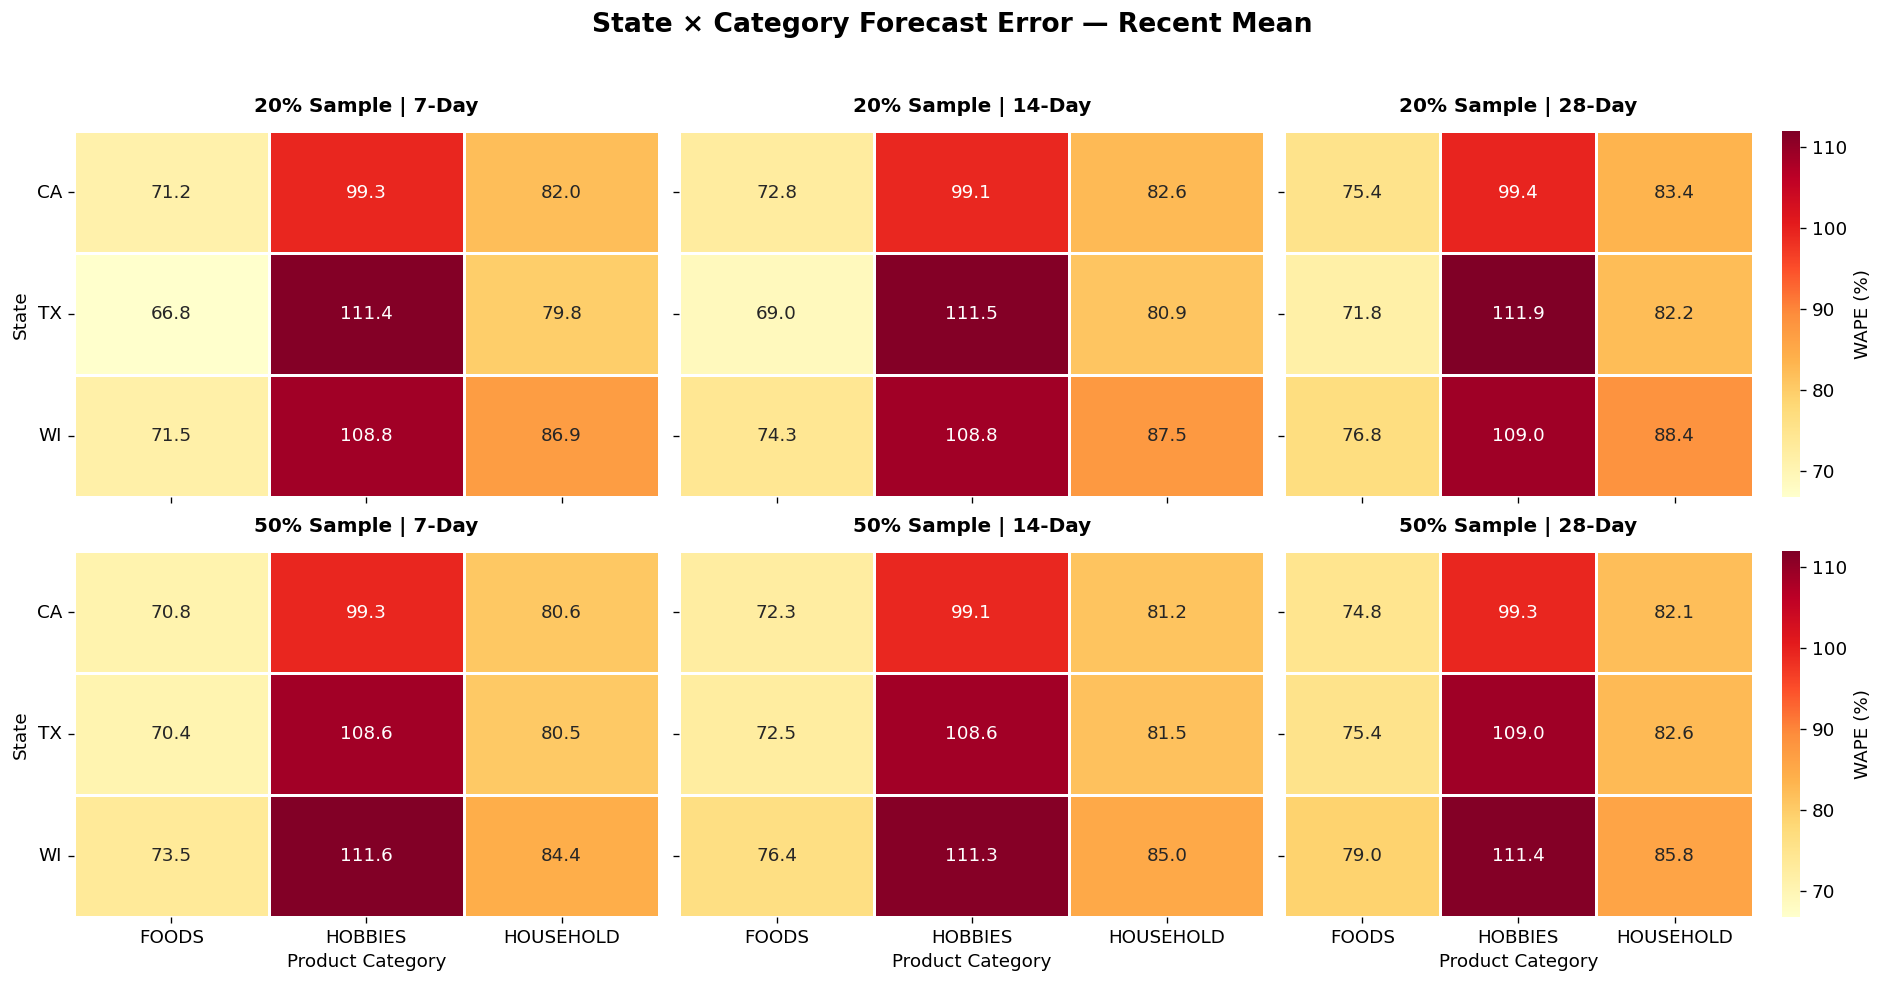

In [ ]:
# Figure 8 — State × Category WAPE Across Horizons
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True, sharey=True)
samples = [("20% Sample", group_error_20), ("50% Sample", group_error_50)]
states = ["CA", "TX", "WI"]
categories = ["FOODS", "HOBBIES", "HOUSEHOLD"]

all_wape = pd.concat([group_error_20, group_error_50], ignore_index=True)
all_wape = all_wape.loc[all_wape["model"] == "recent_mean", "WAPE_pct"]
vmin, vmax = all_wape.min(), all_wape.max()

for row, (sample_name, df) in enumerate(samples):
    for col, horizon in enumerate(HORIZONS):
        selected = df[(df["model"] == "recent_mean") & (df["horizon"] == horizon)]
        heatmap_data = selected.pivot(index="state_id", columns="cat_id", values="WAPE_pct").reindex(index=states, columns=categories)

        ax = axes[row, col]
        sns.heatmap(heatmap_data, ax=ax, annot=True, fmt=".1f", cmap="YlOrRd", vmin=vmin, vmax=vmax, linewidths=0.7, linecolor="white", cbar=(col == 2), cbar_kws={"label": "WAPE (%)"})
        ax.set_title(f"{sample_name} | {horizon}-Day", fontsize=12, fontweight="bold", pad=12)
        ax.set_xlabel("Product Category" if row == 1 else "")
        ax.set_ylabel("State" if col == 0 else "")
        ax.tick_params(axis="x", rotation=0)
        ax.tick_params(axis="y", rotation=0)

fig.suptitle("State × Category Forecast Error — Recent Mean", fontsize=16, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure8_state_category_wape_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Compare 20% vs 50% robustness
group_20_7 = group_error_20.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "WAPE_pct"]].rename(columns={"WAPE_pct": "WAPE_20"})
group_50_7 = group_error_50.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "n_series", "WAPE_pct"]].rename(columns={"WAPE_pct": "WAPE_50"})

group_comparison = group_20_7.merge(group_50_7, on=["state_id", "cat_id"], validate="one_to_one")
group_comparison["WAPE_diff_pp"] = group_comparison["WAPE_50"] - group_comparison["WAPE_20"]

assert len(group_comparison) == 9

display(group_comparison.sort_values(["state_id", "cat_id"]).round(2))
print("Maximum absolute WAPE difference:", round(group_comparison["WAPE_diff_pp"].abs().max(), 2), "percentage points")

,state_id,cat_id,WAPE_20,n_series,WAPE_50,WAPE_diff_pp
2,CA,FOODS,71.16,2874,70.84,-0.32
0,CA,HOBBIES,99.33,1130,99.26,-0.07
1,CA,HOUSEHOLD,82.03,2094,80.61,-1.42
5,TX,FOODS,66.85,2156,70.40,3.55
3,TX,HOBBIES,111.39,848,108.56,-2.82
4,TX,HOUSEHOLD,79.76,1571,80.52,0.75
8,WI,FOODS,71.53,2155,73.49,1.96
6,WI,HOBBIES,108.82,847,111.64,2.81
7,WI,HOUSEHOLD,86.93,1570,84.42,-2.51


Maximum absolute WAPE difference: 3.55 percentage points


In [ ]:
#Export Error Analysis results
group_error_20.to_csv(
    Forecasting_OUTPUT / "group_error_analysis_20.csv",
    index=False
)
group_error_50.to_csv(
    Forecasting_OUTPUT / "group_error_analysis_50.csv",
    index=False
)
group_comparison.to_csv(
    Forecasting_OUTPUT / "state_category_comparison_20_50.csv",
    index=False
)
print("Section 11 Error Analysis exported successfully.")

Section 11 Error Analysis exported successfully.


### Interim Findings — State × Category Error Analysis and Sample Robustness

The State × Category error analysis was conducted on both the 20% (6,098 series) and 50% (15,245 series) stratified samples using identical rolling-origin backtesting procedures.

**Key Findings**

1. **Consistent forecast difficulty across categories:** For the 7-day Recent Mean baseline, FOODS consistently achieved the lowest WAPE across all three states, followed by HOUSEHOLD, while HOBBIES exhibited the highest WAPE in both samples.

2. **Stable results across sample sizes:** The category-level error patterns remained consistent between the 20% and 50% samples. Across the nine State × Category groups, the maximum absolute WAPE difference was 3.55 percentage points (TX FOODS).

3. **Validated error aggregation:** Both samples passed reconciliation checks, confirming that State × Category error aggregates reproduce the overall MAE, RMSE, and WAPE metrics for all three baseline models and forecasting horizons (7, 14, and 28 days).

**Business Implications**

The consistent difficulty of forecasting HOBBIES suggests that forecasting approaches may need to account for category-specific demand characteristics. However, high relative forecast error does not necessarily imply the largest aggregate business impact.

**Limitations and Next Steps**

Because the 20% sample is nested within the 50% sample, this comparison provides descriptive robustness evidence rather than an independent statistical significance test. Further analysis of zero-sales frequency, absolute error contribution, and forecast bias will help explain the observed differences and identify business priorities.

### Recent Mean (7-Day)

Recent Mean consistently achieved the lowest WAPE, MAE, and RMSE among the evaluated baselines, while the 7-day horizon represents a relevant short-term forecasting scenario for weekly inventory planning.

This focused analysis examines demand sparsity, forecast error concentration, and category-level differences across both the 20% and 50% samples. The objective is to identify where the strongest baseline still struggles and which product categories may warrant further forecasting improvements.

**Scope:** Findings from these diagnostic analyses apply specifically to the 7-day Recent Mean baseline and should not be generalized to other models or forecasting horizons without additional evaluation.

In [ ]:
#Demand Pattern Analysis (Training Data Only)

def analyze_demand_patterns(matrix, metadata):
    train_matrix = matrix[:, :len(train_days)]
    result = metadata.copy()

    result["zero_sales_rate"] = (train_matrix == 0).mean(axis=1)
    result["avg_daily_sales"] = train_matrix.mean(axis=1)

    summary = result.groupby(["state_id", "cat_id"], observed=True).agg(
        n_series=("id", "size"), avg_zero_sales_rate=("zero_sales_rate", "mean"),
        avg_daily_sales=("avg_daily_sales", "mean")
    ).reset_index()

    summary["zero_sales_pct"] = summary["avg_zero_sales_rate"] * 100
    return result, summary


metadata_20, demand_pattern_20 = analyze_demand_patterns(sample20_matrix, metadata_20)
metadata_50, demand_pattern_50 = analyze_demand_patterns(sample50_matrix, metadata_50)

assert len(metadata_20) == 6098 and len(metadata_50) == 15245
assert len(demand_pattern_20) == len(demand_pattern_50) == 9

print("Demand Pattern Analysis — 20% Sample")
display(demand_pattern_20[["state_id", "cat_id", "n_series", "zero_sales_pct", "avg_daily_sales"]].round(2))

print("Demand Pattern Analysis — 50% Sample")
display(demand_pattern_50[["state_id", "cat_id", "n_series", "zero_sales_pct", "avg_daily_sales"]].round(2))

Demand Pattern Analysis — 20% Sample


,state_id,cat_id,n_series,zero_sales_pct,avg_daily_sales
0,CA,HOBBIES,452,77.30,0.68
1,CA,HOUSEHOLD,838,71.71,0.70
2,CA,FOODS,1150,63.04,1.71
3,TX,HOBBIES,339,79.84,0.46
4,TX,HOUSEHOLD,628,74.90,0.69
5,TX,FOODS,862,65.38,1.76
6,WI,HOBBIES,339,80.17,0.47
7,WI,HOUSEHOLD,628,77.17,0.55
8,WI,FOODS,862,65.01,1.58


Demand Pattern Analysis — 50% Sample


,state_id,cat_id,n_series,zero_sales_pct,avg_daily_sales
0,CA,HOBBIES,1130,77.48,0.65
1,CA,HOUSEHOLD,2094,72.03,0.73
2,CA,FOODS,2874,63.92,1.61
3,TX,HOBBIES,848,79.90,0.46
4,TX,HOUSEHOLD,1571,74.07,0.72
5,TX,FOODS,2156,65.54,1.54
6,WI,HOBBIES,847,80.95,0.45
7,WI,HOUSEHOLD,1570,77.37,0.57
8,WI,FOODS,2155,66.23,1.50


20% Sample — Zero-Sales vs. WAPE Correlation: 0.903


,state_id,cat_id,zero_sales_pct,avg_daily_sales,WAPE_pct
0,CA,HOBBIES,77.30,0.68,99.33
1,CA,HOUSEHOLD,71.71,0.70,82.03
2,CA,FOODS,63.04,1.71,71.16
3,TX,HOBBIES,79.84,0.46,111.39
4,TX,HOUSEHOLD,74.90,0.69,79.76
5,TX,FOODS,65.38,1.76,66.85
6,WI,HOBBIES,80.17,0.47,108.82
7,WI,HOUSEHOLD,77.17,0.55,86.93
8,WI,FOODS,65.01,1.58,71.53


50% Sample — Zero-Sales vs. WAPE Correlation: 0.908


,state_id,cat_id,zero_sales_pct,avg_daily_sales,WAPE_pct
0,CA,HOBBIES,77.48,0.65,99.26
1,CA,HOUSEHOLD,72.03,0.73,80.61
2,CA,FOODS,63.92,1.61,70.84
3,TX,HOBBIES,79.90,0.46,108.56
4,TX,HOUSEHOLD,74.07,0.72,80.52
5,TX,FOODS,65.54,1.54,70.40
6,WI,HOBBIES,80.95,0.45,111.64
7,WI,HOUSEHOLD,77.37,0.57,84.42
8,WI,FOODS,66.23,1.50,73.49


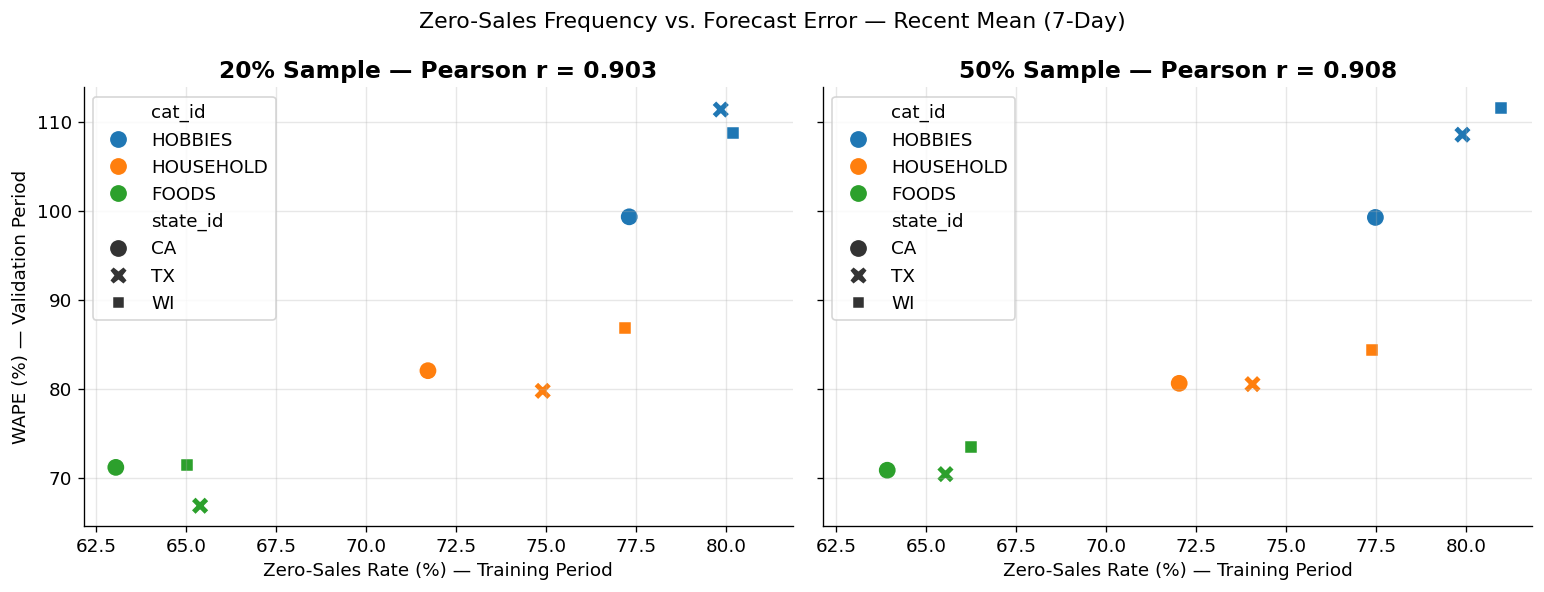

In [ ]:
# Zero-Sales Rate vs. Forecast Error

def analyze_demand_error(demand_pattern, group_errors, sample_label):
    wape_7d = group_errors.query("model == 'recent_mean' and horizon == 7")[["state_id", "cat_id", "WAPE_pct"]]
    result = demand_pattern.merge(wape_7d, on=["state_id", "cat_id"], validate="one_to_one")
    correlation = result["zero_sales_pct"].corr(result["WAPE_pct"])

    print(f"{sample_label}% Sample — Zero-Sales vs. WAPE Correlation: {correlation:.3f}")
    display(result[["state_id", "cat_id", "zero_sales_pct", "avg_daily_sales", "WAPE_pct"]].round(2))
    return result, correlation

demand_error_20, correlation_20 = analyze_demand_error(demand_pattern_20, group_error_20, "20")
demand_error_50, correlation_50 = analyze_demand_error(demand_pattern_50, group_error_50, "50")

# Compare both samples visually
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

for ax, data, label, corr in zip(axes, [demand_error_20, demand_error_50], ["20%", "50%"], [correlation_20, correlation_50]):
    sns.scatterplot(data=data, x="zero_sales_pct", y="WAPE_pct", hue="cat_id", style="state_id", s=120, ax=ax)
    ax.set_title(f"{label} Sample — Pearson r = {corr:.3f}")
    ax.set_xlabel("Zero-Sales Rate (%) — Training Period")
    ax.set_ylabel("WAPE (%) — Validation Period")
    ax.grid(alpha=0.3)

plt.suptitle("Zero-Sales Frequency vs. Forecast Error — Recent Mean (7-Day)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "zero_sales_vs_wape_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Demand Patterns and Forecast Error

**Key Findings**

1. **Strong positive correlation:** Training-period zero-sales frequency was strongly associated with validation-period WAPE for the 7-day Recent Mean baseline. Pearson correlations were **0.903 for the 20% sample** and **0.908 for the 50% sample**, indicating consistent group-level patterns across both samples.

2. **HOBBIES showed the sparsest demand and highest forecasting errors.** Zero-sales rates ranged from 77.30%–80.17% in the 20% sample and 77.48%–80.95% in the 50% sample. HOBBIES also consistently exhibited the highest WAPE across all three states.

3. **FOODS showed relatively more frequent sales and lower forecasting errors.** Both samples demonstrated lower zero-sales rates and lower WAPE for FOODS than for HOUSEHOLD and HOBBIES.

**Business Implications**

The findings suggest that demand sparsity is an important characteristic to consider when evaluating forecasting methods. Products with frequent zero-sales days may benefit from further investigation of intermittent-demand forecasting approaches.

The consistency between the 20% and 50% samples provides descriptive evidence that the observed group-level relationship is not unique to the smaller sample.

**Limitations**

The correlations are based on only nine aggregated State × Category groups per sample and do not establish causation or confirm the relationship at the individual-series level. The samples are nested rather than independent. Additionally, zero recorded sales should not be interpreted as confirmed stockouts.

In [ ]:
# Error Contribution Analysis — All Models, Horizons and Samples

def analyze_error_contribution(group_errors):
    detail = group_errors.copy()
    detail["error_share_pct"] = 100 * detail["sum_abs_error"] / detail.groupby(["model", "horizon"])["sum_abs_error"].transform("sum")
    category = detail.groupby(["model", "horizon", "cat_id"], as_index=False).agg(n_series=("n_series", "sum"), sum_abs_error=("sum_abs_error", "sum"), sum_actual=("sum_actual", "sum"))
    category["error_share_pct"] = 100 * category["sum_abs_error"] / category.groupby(["model", "horizon"])["sum_abs_error"].transform("sum")
    category["WAPE_pct"] = np.where(category["sum_actual"] > 0, 100 * category["sum_abs_error"] / category["sum_actual"], np.nan)
    assert np.allclose(category.groupby(["model", "horizon"])["error_share_pct"].sum(), 100)
    return detail, category

error_contribution_20, category_contribution_20 = analyze_error_contribution(group_error_20)
error_contribution_50, category_contribution_50 = analyze_error_contribution(group_error_50)

for label, df in [("20%", category_contribution_20), ("50%", category_contribution_50)]:
    print(f"{label} Sample — Error Contribution by Model, Horizon and Category")
    display(df[["model", "horizon", "cat_id", "n_series", "WAPE_pct", "error_share_pct"]].round(2))

20% Sample — Error Contribution by Model, Horizon and Category


,model,horizon,cat_id,n_series,WAPE_pct,error_share_pct
0,recent_mean,7,FOODS,2874,69.99,60.67
1,recent_mean,7,HOBBIES,1130,104.74,13.89
2,recent_mean,7,HOUSEHOLD,2094,82.56,25.44
3,recent_mean,14,FOODS,2874,72.12,61.24
4,recent_mean,14,HOBBIES,1130,104.66,13.59
5,recent_mean,14,HOUSEHOLD,2094,83.32,25.18
6,recent_mean,28,FOODS,2874,74.76,61.81
7,recent_mean,28,HOBBIES,1130,104.95,13.28
8,recent_mean,28,HOUSEHOLD,2094,84.29,24.91
9,weekly_seasonal_naive,7,FOODS,2874,82.86,61.08


50% Sample — Error Contribution by Model, Horizon and Category


,model,horizon,cat_id,n_series,WAPE_pct,error_share_pct
0,recent_mean,7,FOODS,7185,71.56,59.39
1,recent_mean,7,HOBBIES,2825,104.71,13.96
2,recent_mean,7,HOUSEHOLD,5235,81.58,26.66
3,recent_mean,14,FOODS,7185,73.68,59.95
4,recent_mean,14,HOBBIES,2825,104.58,13.66
5,recent_mean,14,HOUSEHOLD,5235,82.30,26.39
6,recent_mean,28,FOODS,7185,76.30,60.52
7,recent_mean,28,HOBBIES,2825,104.82,13.36
8,recent_mean,28,HOUSEHOLD,5235,83.25,26.12
9,weekly_seasonal_naive,7,FOODS,7185,84.61,59.74


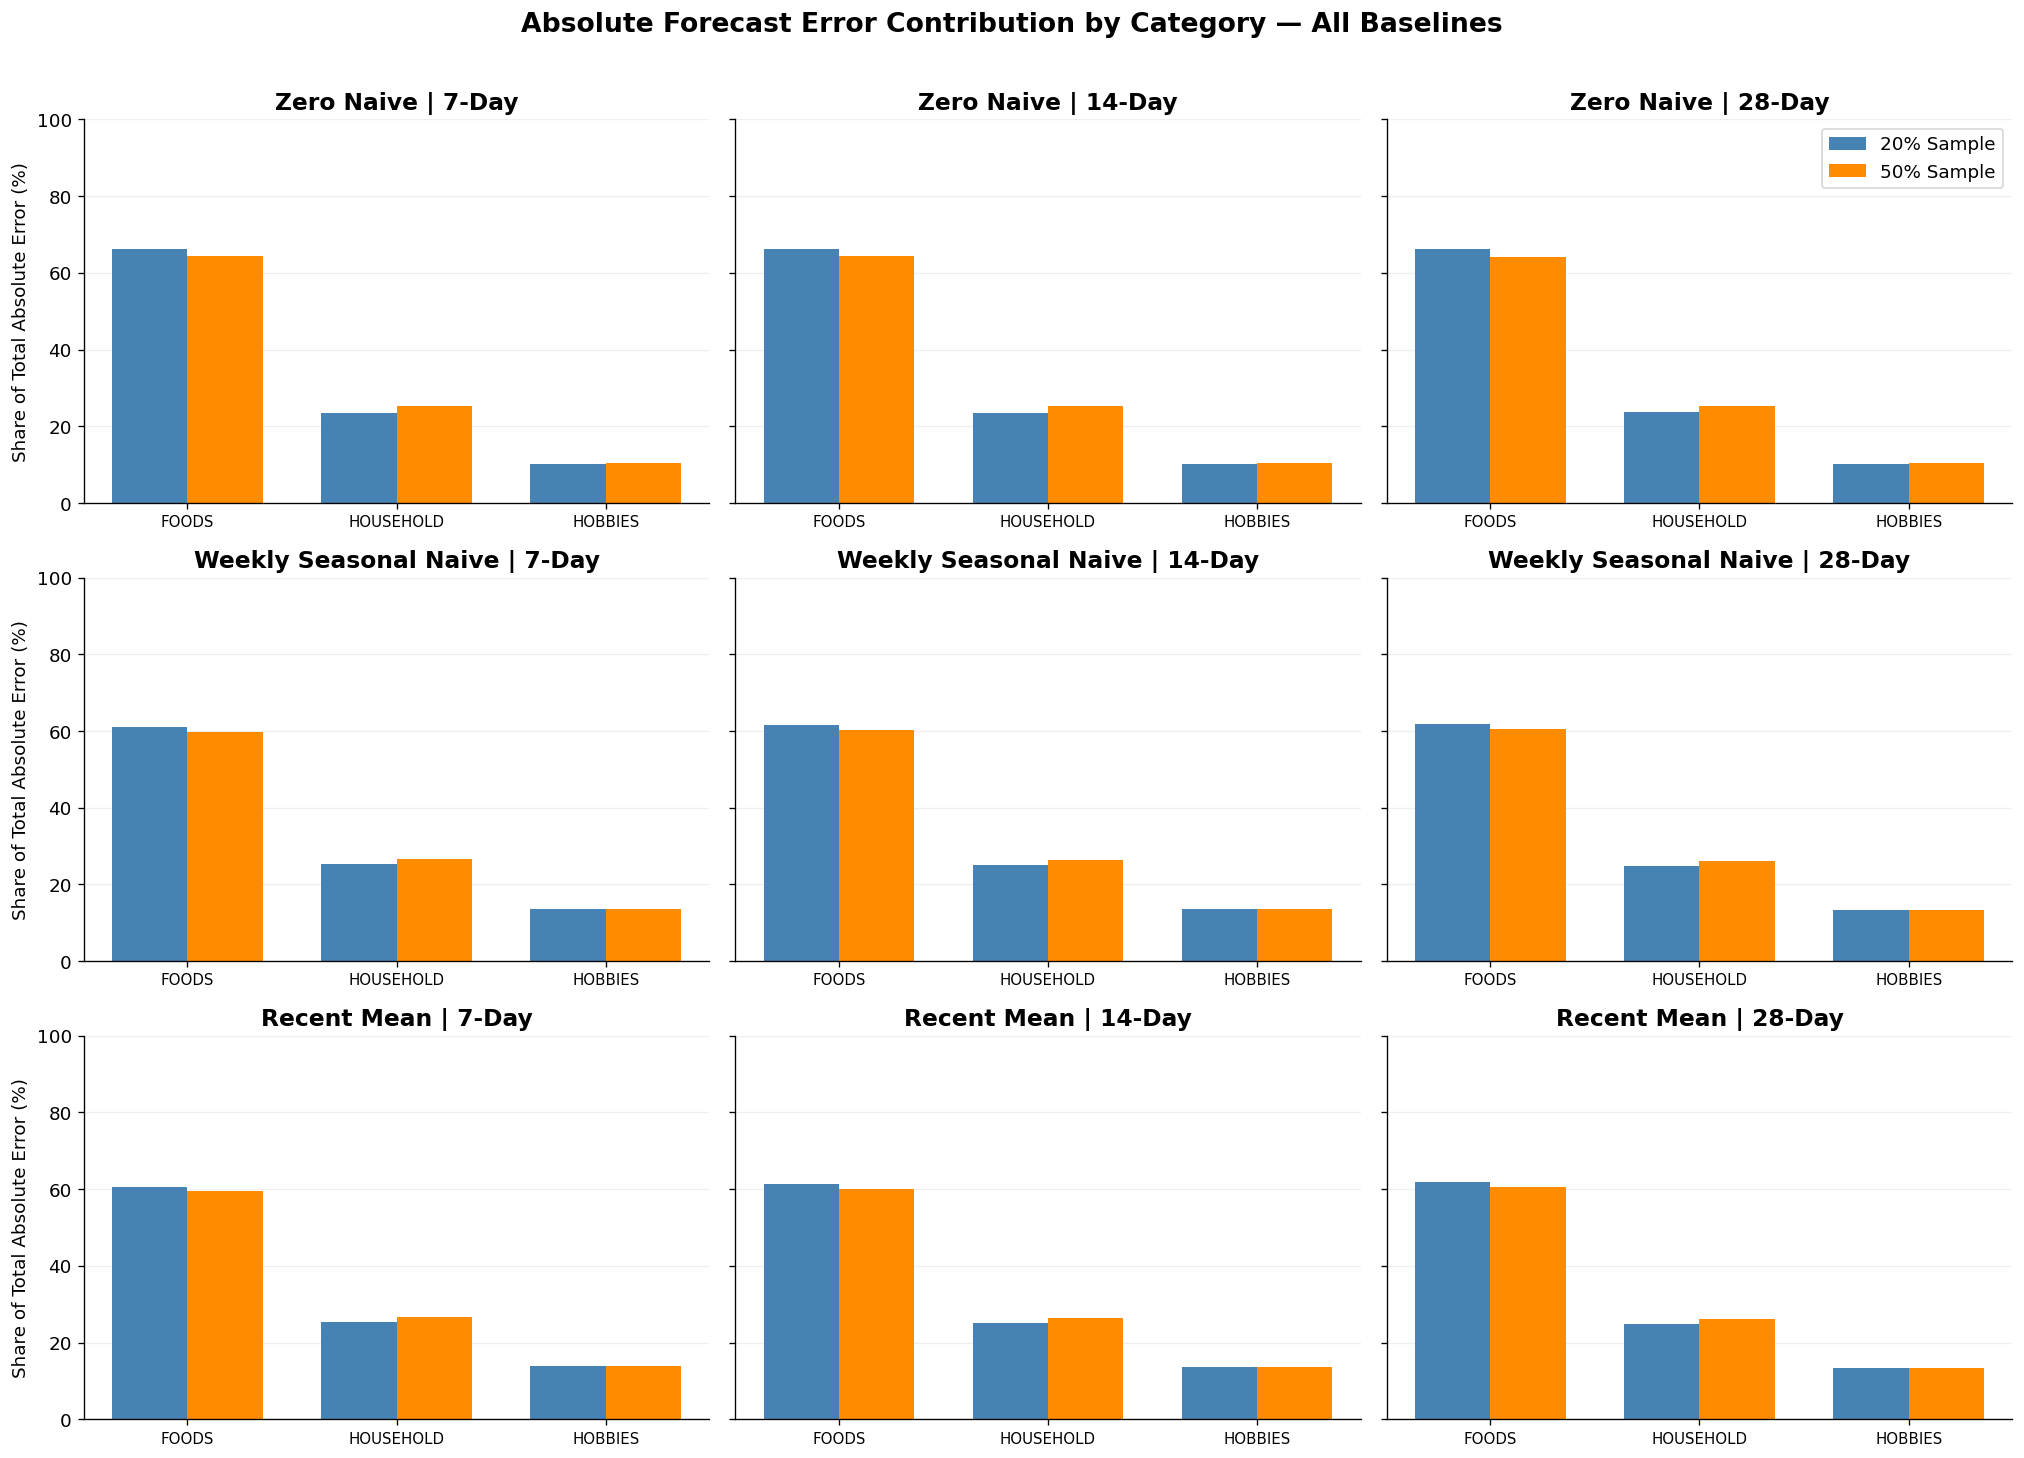

In [ ]:
# Figure 9 — Error Contribution Across All Models and Horizons

fig, axes = plt.subplots(3, 3, figsize=(17, 12), sharey=True)
models = ["zero_naive", "weekly_seasonal_naive", "recent_mean"]
categories = ["FOODS", "HOUSEHOLD", "HOBBIES"]
x, width = np.arange(len(categories)), 0.36

for i, model in enumerate(models):
    for j, horizon in enumerate(HORIZONS):
        ax = axes[i, j]
        for offset, (label, df, color) in enumerate([("20% Sample", category_contribution_20, "steelblue"), ("50% Sample", category_contribution_50, "darkorange")]):
            selected = df[(df["model"] == model) & (df["horizon"] == horizon)].set_index("cat_id").reindex(categories)
            ax.bar(x + (offset - 0.5) * width, selected["error_share_pct"], width, label=label, color=color)
        ax.set_title(f"{model.replace('_', ' ').title()} | {horizon}-Day", fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(categories, fontsize=9)
        ax.set_ylim(0, 100)
        ax.set_ylabel("Share of Total Absolute Error (%)" if j == 0 else "")
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
        if i == 0 and j == 2: ax.legend()

fig.suptitle("Absolute Forecast Error Contribution by Category — All Baselines", fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure9_error_contribution_all_models_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Error Contribution Analysis

**Key Findings**

1. **FOODS contributed the largest share of total absolute forecasting error**, accounting for 60.67% in the 20% sample and 59.39% in the 50% sample, despite having the lowest category-level WAPE.

2. **HOBBIES exhibited the highest relative forecasting error**, with WAPE values of 104.74% and 104.71%, but contributed only 13.89% and 13.96% of total absolute error in the respective samples.

3. **HOUSEHOLD represented an intermediate category**, contributing 25.44% and 26.66% of total absolute error in the 20% and 50% samples, respectively.

4. **The error contribution ranking remained stable across both samples.** CA–FOODS was the largest individual State × Category contributor, accounting for 24.32% and 24.06% of total absolute error.

**Business Implications**

The findings highlight two distinct forecasting priorities:

- **Aggregate error reduction:** FOODS is a potential priority because it accounts for the majority of total absolute forecasting error.
- **Sparse-demand forecasting:** HOBBIES warrants further investigation because of its high relative forecasting error and frequent zero-sales days.

These priorities reflect forecasting performance rather than measured financial impact. Inventory costs, stockout information, and product values would be required to quantify operational or financial benefits.

**Robustness and Limitations**

The consistency between the nested 20% and 50% samples supports the stability of the descriptive findings. However, the results do not establish that improving forecasts for a particular category will necessarily generate the largest inventory cost savings.

#10.Forecast Bias Analysis (20% & 50% Samples)

In [ ]:
def analyze_forecast_bias(matrix):
    results = []
    train_length, n_days = len(train_days), matrix.shape[1]

    for horizon in [7, 14, 28]:
        for origin in range(train_length, n_days - horizon + 1, 7):
            history, actual = matrix[:, :origin], matrix[:, origin:origin + horizon]
            forecasts = generate_baselines(history, horizon=horizon)

            for model, forecast in forecasts.items():
                assert forecast.shape == actual.shape
                results.append({
                    "horizon": horizon, "model": model,
                    "sum_signed_error": (forecast - actual).sum(dtype=np.float64),
                    "sum_actual": actual.sum(dtype=np.float64), "n_obs": actual.size
                })

    backtest = pd.DataFrame(results)
    summary = backtest.groupby(["horizon", "model"], as_index=False).agg(
        sum_signed_error=("sum_signed_error", "sum"),
        sum_actual=("sum_actual", "sum"), n_observations=("n_obs", "sum")
    )

    summary["ME"] = summary["sum_signed_error"] / summary["n_observations"]
    summary["Bias_pct"] = np.where(summary["sum_actual"] > 0, 100 * summary["sum_signed_error"] / summary["sum_actual"], np.nan)
    summary["Direction"] = np.where(summary["ME"] > 0, "Overforecast", np.where(summary["ME"] < 0, "Underforecast", "Neutral"))

    assert len(summary) == 9
    assert backtest.groupby(["horizon", "model"]).size().tolist() == [52, 52, 52, 51, 51, 51, 49, 49, 49]
    return backtest, summary


bias_backtest_20, bias_summary_20 = analyze_forecast_bias(sample20_matrix)
bias_backtest_50, bias_summary_50 = analyze_forecast_bias(sample50_matrix)

print("20% Sample — Forecast Bias")
display(bias_summary_20[["horizon", "model", "ME", "Bias_pct", "Direction"]].round(2))

print("50% Sample — Forecast Bias")
display(bias_summary_50[["horizon", "model", "ME", "Bias_pct", "Direction"]].round(2))

20% Sample — Forecast Bias


,horizon,model,ME,Bias_pct,Direction
0,7,recent_mean,-0.00,-0.13,Underforecast
1,7,weekly_seasonal_naive,-0.00,-0.13,Underforecast
2,7,zero_naive,-1.27,-100.00,Underforecast
3,14,recent_mean,-0.01,-0.48,Underforecast
4,14,weekly_seasonal_naive,-0.01,-0.48,Underforecast
5,14,zero_naive,-1.27,-100.00,Underforecast
6,28,recent_mean,-0.01,-0.86,Underforecast
7,28,weekly_seasonal_naive,-0.01,-0.86,Underforecast
8,28,zero_naive,-1.28,-100.00,Underforecast


50% Sample — Forecast Bias


,horizon,model,ME,Bias_pct,Direction
0,7,recent_mean,-0.00,-0.11,Underforecast
1,7,weekly_seasonal_naive,-0.00,-0.11,Underforecast
2,7,zero_naive,-1.23,-100.00,Underforecast
3,14,recent_mean,-0.01,-0.46,Underforecast
4,14,weekly_seasonal_naive,-0.01,-0.46,Underforecast
5,14,zero_naive,-1.23,-100.00,Underforecast
6,28,recent_mean,-0.01,-0.83,Underforecast
7,28,weekly_seasonal_naive,-0.01,-0.83,Underforecast
8,28,zero_naive,-1.24,-100.00,Underforecast


In [ ]:
# Validate Forecast Bias Against Existing Group Error Analysis

def validate_forecast_bias(bias_summary, group_errors):
    actual_totals = group_errors.groupby(["horizon", "model"], as_index=False).agg(sum_actual=("sum_actual", "sum"))

    check = bias_summary.merge(actual_totals, on=["horizon", "model"],
                               suffixes=("_bias", "_evaluation"), validate="one_to_one")

    assert len(check) == 9
    assert np.allclose(check["sum_actual_bias"], check["sum_actual_evaluation"], rtol=1e-8, atol=1e-5)
    return check

bias_check_20 = validate_forecast_bias(bias_summary_20, group_error_20)
bias_check_50 = validate_forecast_bias(bias_summary_50, group_error_50)

print("20% Forecast Bias Validation: PASSED")
print("50% Forecast Bias Validation: PASSED")

20% Forecast Bias Validation: PASSED
50% Forecast Bias Validation: PASSED


,horizon,Bias_20,Bias_50,Bias_diff_pp
0,7,-0.128,-0.111,0.017
1,14,-0.483,-0.457,0.026
2,28,-0.856,-0.830,0.026


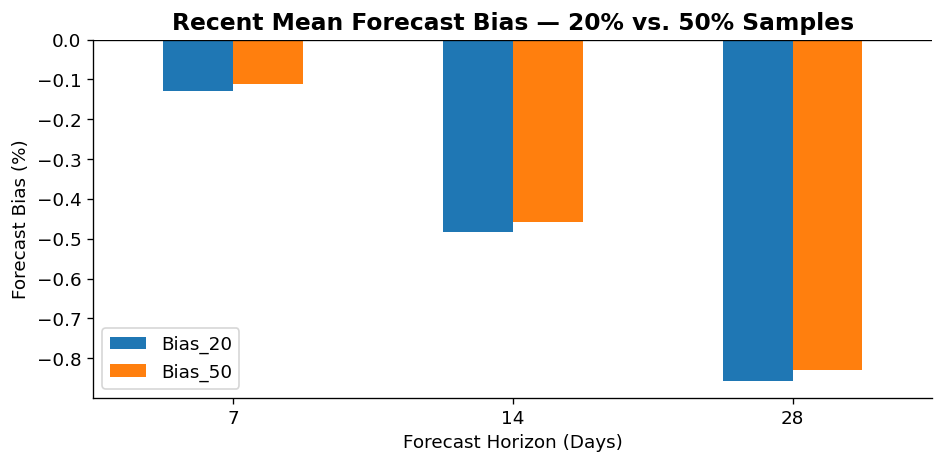

In [ ]:
# Compare Recent Mean Bias Across Samples

bias_20 = bias_summary_20.query("model == 'recent_mean'")[["horizon", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_20"})
bias_50 = bias_summary_50.query("model == 'recent_mean'")[["horizon", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_50"})

bias_comparison = bias_20.merge(bias_50, on="horizon", validate="one_to_one")
bias_comparison["Bias_diff_pp"] = bias_comparison["Bias_50"] - bias_comparison["Bias_20"]

display(bias_comparison.round(3))

ax = bias_comparison.set_index("horizon")[["Bias_20", "Bias_50"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Recent Mean Forecast Bias — 20% vs. 50% Samples")
ax.set_xlabel("Forecast Horizon (Days)")
ax.set_ylabel("Forecast Bias (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "forecast_bias_comparison_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Forecast Bias Analysis

**Key Findings**

1. **Recent Mean exhibited a small negative aggregate forecast bias across all horizons.** Bias values were -0.128%, -0.483%, and -0.856% for the 20% sample, compared with -0.111%, -0.457%, and -0.830% for the 50% sample at the 7-, 14-, and 28-day horizons, respectively.

2. **The direction and magnitude of forecast bias were consistent across both samples.** The maximum absolute difference was only 0.026 percentage points, supporting the descriptive robustness of the findings.

3. **Underforecasting became more pronounced at longer horizons.** However, the relatively small aggregate bias does not imply high forecasting accuracy, as substantial absolute forecasting errors remain.

**Business Implications**

Forecast evaluation should consider both absolute error metrics (MAE, RMSE, WAPE) and directional bias. Small aggregate bias may conceal offsetting overforecasts and underforecasts across individual products, stores, and categories.

Although underforecasting may increase potential inventory-planning risks, actual stockout exposure cannot be quantified without inventory availability and replenishment data.

**Next Step**

Examine forecast bias by State × Category to determine whether the small aggregate bias masks systematic differences across product groups and geographic regions.

In [ ]:
# State × Category Forecast Bias (20% & 50%)
def analyze_group_bias(matrix, metadata, horizon=7):
    results = []
    train_length, n_days = len(train_days), matrix.shape[1]

    for (state, category), group in metadata.groupby(["state_id", "cat_id"], observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        signed_error, actual_total, n_obs = 0.0, 0.0, 0

        for origin in range(train_length, n_days - horizon + 1, 7):
            history = group_matrix[:, :origin]
            actual = group_matrix[:, origin:origin + horizon]
            forecast = generate_baselines(history, horizon=horizon)["recent_mean"]

            signed_error += (forecast - actual).sum(dtype=np.float64)
            actual_total += actual.sum(dtype=np.float64)
            n_obs += actual.size

        results.append({"state_id": state, "cat_id": category, "n_series": len(group),
                        "sum_signed_error": signed_error, "sum_actual": actual_total, "n_observations": n_obs})

    result = pd.DataFrame(results)
    result["Bias_pct"] = np.where(result["sum_actual"] > 0, 100 * result["sum_signed_error"] / result["sum_actual"], np.nan)
    result["Direction"] = np.where(result["Bias_pct"] > 0, "Overforecast", np.where(result["Bias_pct"] < 0, "Underforecast", "Neutral"))
    return result


group_bias_20 = analyze_group_bias(sample20_matrix, metadata_20)
group_bias_50 = analyze_group_bias(sample50_matrix, metadata_50)

assert len(group_bias_20) == len(group_bias_50) == 9

for group_bias, bias_summary in [(group_bias_20, bias_summary_20), (group_bias_50, bias_summary_50)]:
    expected = bias_summary.query("horizon == 7 and model == 'recent_mean'").iloc[0]
    assert np.isclose(group_bias["sum_signed_error"].sum(), expected["sum_signed_error"], atol=1e-3)
    assert np.isclose(group_bias["sum_actual"].sum(), expected["sum_actual"], atol=1e-3)

print("State × Category Bias Reconciliation: PASSED")

print("20% Sample")
display(group_bias_20[["state_id", "cat_id", "n_series", "Bias_pct", "Direction"]].round(3))

print("50% Sample")
display(group_bias_50[["state_id", "cat_id", "n_series", "Bias_pct", "Direction"]].round(3))

State × Category Bias Reconciliation: PASSED
20% Sample


,state_id,cat_id,n_series,Bias_pct,Direction
0,CA,HOBBIES,452,-0.528,Underforecast
1,CA,HOUSEHOLD,838,-0.167,Underforecast
2,CA,FOODS,1150,-0.117,Underforecast
3,TX,HOBBIES,339,0.018,Overforecast
4,TX,HOUSEHOLD,628,-0.337,Underforecast
5,TX,FOODS,862,0.007,Overforecast
6,WI,HOBBIES,339,-0.019,Underforecast
7,WI,HOUSEHOLD,628,-0.097,Underforecast
8,WI,FOODS,862,-0.118,Underforecast


50% Sample


,state_id,cat_id,n_series,Bias_pct,Direction
0,CA,HOBBIES,1130,-0.426,Underforecast
1,CA,HOUSEHOLD,2094,-0.182,Underforecast
2,CA,FOODS,2874,-0.104,Underforecast
3,TX,HOBBIES,848,-0.105,Underforecast
4,TX,HOUSEHOLD,1571,-0.314,Underforecast
5,TX,FOODS,2156,0.010,Overforecast
6,WI,HOBBIES,847,-0.096,Underforecast
7,WI,HOUSEHOLD,1570,-0.099,Underforecast
8,WI,FOODS,2155,-0.039,Underforecast


In [ ]:
#Compare State × Category Bias Across Samples

bias_group_20 = group_bias_20[["state_id", "cat_id", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_20"})
bias_group_50 = group_bias_50[["state_id", "cat_id", "Bias_pct"]].rename(columns={"Bias_pct": "Bias_50"})

group_bias_comparison = bias_group_20.merge(bias_group_50, on=["state_id", "cat_id"], validate="one_to_one")
group_bias_comparison["Bias_diff_pp"] = group_bias_comparison["Bias_50"] - group_bias_comparison["Bias_20"]

assert len(group_bias_comparison) == 9

display(group_bias_comparison.sort_values(["state_id", "cat_id"]).round(3))
print("Maximum absolute group bias difference:", round(group_bias_comparison["Bias_diff_pp"].abs().max(), 3), "percentage points")

,state_id,cat_id,Bias_20,Bias_50,Bias_diff_pp
2,CA,FOODS,-0.117,-0.104,0.013
0,CA,HOBBIES,-0.528,-0.426,0.102
1,CA,HOUSEHOLD,-0.167,-0.182,-0.015
5,TX,FOODS,0.007,0.010,0.003
3,TX,HOBBIES,0.018,-0.105,-0.122
4,TX,HOUSEHOLD,-0.337,-0.314,0.023
8,WI,FOODS,-0.118,-0.039,0.079
6,WI,HOBBIES,-0.019,-0.096,-0.077
7,WI,HOUSEHOLD,-0.097,-0.099,-0.002


Maximum absolute group bias difference: 0.122 percentage points


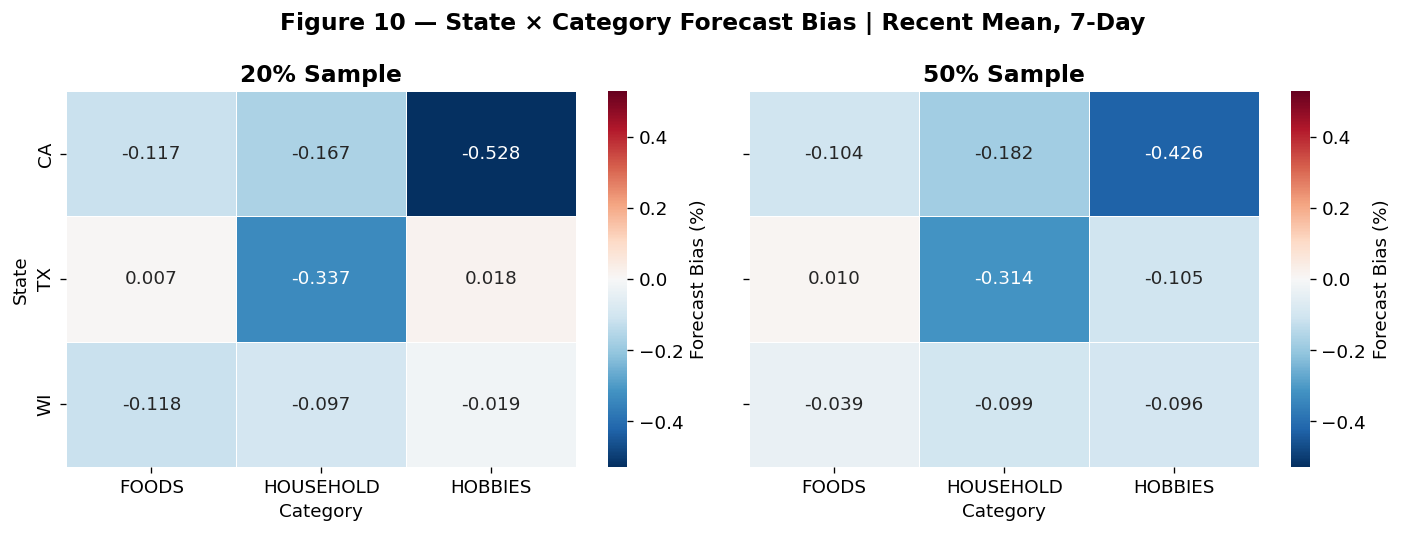

In [ ]:
# Figure 10 — State × Category Forecast Bias Heatmap (Recent Mean, 7-Day)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
samples = [("20% Sample", group_bias_20), ("50% Sample", group_bias_50)]
limit = max(df["Bias_pct"].abs().max() for _, df in samples)

for ax, (label, df) in zip(axes, samples):
    pivot = df.pivot(index="state_id", columns="cat_id", values="Bias_pct").reindex(index=["CA", "TX", "WI"], columns=["FOODS", "HOUSEHOLD", "HOBBIES"])
    sns.heatmap(pivot, ax=ax, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, linewidths=0.5, linecolor="white", cbar=True, cbar_kws={"label": "Forecast Bias (%)"})
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("Category")
    ax.set_ylabel("State" if ax == axes[0] else "")

fig.suptitle("Figure 10 — State × Category Forecast Bias | Recent Mean, 7-Day", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure10_state_category_forecast_bias.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
#Export Forecast Bias Results

bias_summary_20.to_csv(Forecasting_OUTPUT / "forecast_bias_summary_20.csv", index=False)
bias_summary_50.to_csv(Forecasting_OUTPUT / "forecast_bias_summary_50.csv", index=False)
bias_comparison.to_csv(Forecasting_OUTPUT / "forecast_bias_comparison_20_50.csv", index=False)

group_bias_20.to_csv(Forecasting_OUTPUT / "state_category_bias_20.csv", index=False)
group_bias_50.to_csv(Forecasting_OUTPUT / "state_category_bias_50.csv", index=False)
group_bias_comparison.to_csv(Forecasting_OUTPUT / "state_category_bias_comparison_20_50.csv", index=False)

print("Forecast Bias Analysis exported successfully.")

Forecast Bias Analysis exported successfully.


### Interim Findings — State × Category Forecast Bias

**Key Findings**

1. The Recent Mean baseline exhibited small directional bias at the State × Category level for the 7-day horizon, with most groups showing slight underforecasting across both samples.

2. CA–HOBBIES showed the largest negative bias, at -0.528% in the 20% sample and -0.426% in the 50% sample.

3. TX–FOODS exhibited marginal positive bias in both samples (+0.007% and +0.010%). TX–HOBBIES changed from slightly positive to slightly negative bias, although both values remained close to zero.

4. Overall, the direction and magnitude of group-level bias were broadly consistent across samples, with minor differences in near-zero estimates.The maximum absolute difference in group-level bias between the two samples was 0.122 percentage points (TX–HOBBIES), indicating limited sensitivity of the aggregated bias estimates to the sample expansion.

**Business Implications**

Small group-level aggregate bias does not guarantee accurate forecasts for individual item-store series. Positive and negative errors can offset one another, even when WAPE remains high.

Forecast accuracy, directional bias, and demand intermittency should therefore be evaluated together when identifying forecasting improvement opportunities. These results do not establish actual inventory shortages or excess stock.

**Next Step**

Investigate demand characteristics at the individual series level, including demand-volume quantiles and intermittent-demand categories, to determine whether forecasting difficulty varies systematically across demand patterns.

#11. Demand Segmentation Evaluation：Demand Quantile、Demand Type

In [ ]:
# Demand Quantile Classification (Training Data Only)
def classify_demand_quantiles(matrix, metadata):
    result = metadata[["id", "state_id", "cat_id", "store_id"]].copy().reset_index(drop=True)
    train_matrix = matrix[:, :len(train_days)]

    assert len(result) == train_matrix.shape[0]
    result["avg_daily_sales"] = train_matrix.mean(axis=1)
    result["zero_sales_rate"] = (train_matrix == 0).mean(axis=1)
    result["Demand_Quantile"] = pd.qcut(
        result["avg_daily_sales"].rank(method="first"),
        q=3, labels=["Low", "Medium", "High"]
    )

    assert result["Demand_Quantile"].notna().all()
    return result

demand_quantile_20 = classify_demand_quantiles(sample20_matrix, metadata_20)
demand_quantile_50 = classify_demand_quantiles(sample50_matrix, metadata_50)

print("20% Sample — Demand Quantiles")
display(demand_quantile_20.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

print("50% Sample — Demand Quantiles")
display(demand_quantile_50.groupby("Demand_Quantile", observed=True).agg(
    n_series=("id", "size"),
    min_daily_sales=("avg_daily_sales", "min"),
    median_daily_sales=("avg_daily_sales", "median"),
    max_daily_sales=("avg_daily_sales", "max")
).round(3))

assert len(demand_quantile_20) == 6098
assert len(demand_quantile_50) == 15245
assert set(demand_quantile_20["id"]).issubset(set(demand_quantile_50["id"]))

print("Demand Quantile Classification: PASSED")

20% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,2033,0.000,0.073,0.194000
Medium,2032,0.194,0.378,0.724000
High,2033,0.725,1.544,104.419998


50% Sample — Demand Quantiles


,n_series,min_daily_sales,median_daily_sales,max_daily_sales
Demand_Quantile,,,,
Low,5082,0.000,0.075,0.193000
Medium,5081,0.193,0.373,0.713000
High,5082,0.714,1.510,104.419998


Demand Quantile Classification: PASSED


In [ ]:
#Apply Common Demand Quantile Thresholds
q1, q2 = demand_quantile_50["avg_daily_sales"].quantile([1/3, 2/3])
def apply_common_quantiles(df):
    result = df.copy()
    result["Demand_Quantile"] = pd.cut(
        result["avg_daily_sales"],
        bins=[-np.inf, q1, q2, np.inf],
        labels=["Low", "Medium", "High"],
        include_lowest=True
    )
    return result

demand_quantile_20 = apply_common_quantiles(demand_quantile_20)
demand_quantile_50 = apply_common_quantiles(demand_quantile_50)

assert demand_quantile_20["Demand_Quantile"].notna().all()
assert demand_quantile_50["Demand_Quantile"].notna().all()

check = demand_quantile_20[["id", "Demand_Quantile"]].merge(
    demand_quantile_50[["id", "Demand_Quantile"]],
    on="id", suffixes=("_20", "_50"), validate="one_to_one"
)
assert (check["Demand_Quantile_20"] == check["Demand_Quantile_50"]).all()

print(f"Common thresholds: {q1:.4f}, {q2:.4f}")
print("Common Demand Quantile Classification: PASSED")
display(pd.DataFrame({
    "20% Sample": demand_quantile_20["Demand_Quantile"].value_counts().sort_index(),
    "50% Sample": demand_quantile_50["Demand_Quantile"].value_counts().sort_index()
}))

Common thresholds: 0.1926, 0.7137
Common Demand Quantile Classification: PASSED


,20% Sample,50% Sample
Demand_Quantile,,
Low,2025,5083
Medium,2013,5080
High,2060,5082


In [ ]:
#Demand Quantile vs. Forecast Error (20% & 50%)
def analyze_quantile_errors(matrix, quantile_df):
    results = []
    for demand_group, group in quantile_df.groupby("Demand_Quantile", observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        bt = rolling_origin_backtest(
            sales_matrix=group_matrix, day_cols=train_val_days,
            train_length=len(train_days), horizons=(7,), step=STEP,
            recent_mean_window=RECENT_MEAN_WINDOW, season_length=SEASON_LENGTH
        )
        selected = bt.query("model == 'recent_mean'")
        results.append({
            "Demand_Quantile": demand_group, "n_series": len(group),
            "sum_abs_error": selected["sum_abs_error"].sum(),
            "sum_sq_error": selected["sum_sq_error"].sum(),
            "sum_actual": selected["sum_actual"].sum(),
            "n_observations": selected["n_obs"].sum()
        })

    result = pd.DataFrame(results)
    result["MAE"] = result["sum_abs_error"] / result["n_observations"]
    result["RMSE"] = np.sqrt(result["sum_sq_error"] / result["n_observations"])
    result["WAPE_pct"] = np.where(result["sum_actual"] > 0, 100 * result["sum_abs_error"] / result["sum_actual"], np.nan)
    result["error_share_pct"] = 100 * result["sum_abs_error"] / result["sum_abs_error"].sum()
    return result.sort_values("Demand_Quantile").reset_index(drop=True)


quantile_error_20 = analyze_quantile_errors(sample20_matrix, demand_quantile_20)
quantile_error_50 = analyze_quantile_errors(sample50_matrix, demand_quantile_50)

for result, group_errors in [(quantile_error_20, group_error_20), (quantile_error_50, group_error_50)]:
    overall = group_errors.query("horizon == 7 and model == 'recent_mean'")
    assert len(result) == 3
    assert np.isclose(result["sum_abs_error"].sum(), overall["sum_abs_error"].sum(), rtol=1e-8)
    assert np.isclose(result["sum_actual"].sum(), overall["sum_actual"].sum(), rtol=1e-8)

print("Demand Quantile Error Reconciliation: PASSED")
print("20% Sample")
display(quantile_error_20[["Demand_Quantile", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))
print("50% Sample")
display(quantile_error_50[["Demand_Quantile", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))

Demand Quantile Error Reconciliation: PASSED
20% Sample


,Demand_Quantile,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,High,2060,1.82,3.75,65.31,63.17
1,Low,2025,0.43,0.86,113.32,14.59
2,Medium,2013,0.66,1.08,105.12,22.24


50% Sample


,Demand_Quantile,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,High,5082,1.79,3.59,66.03,62.42
1,Low,5083,0.42,0.86,116.81,14.65
2,Medium,5080,0.66,1.09,104.56,22.94


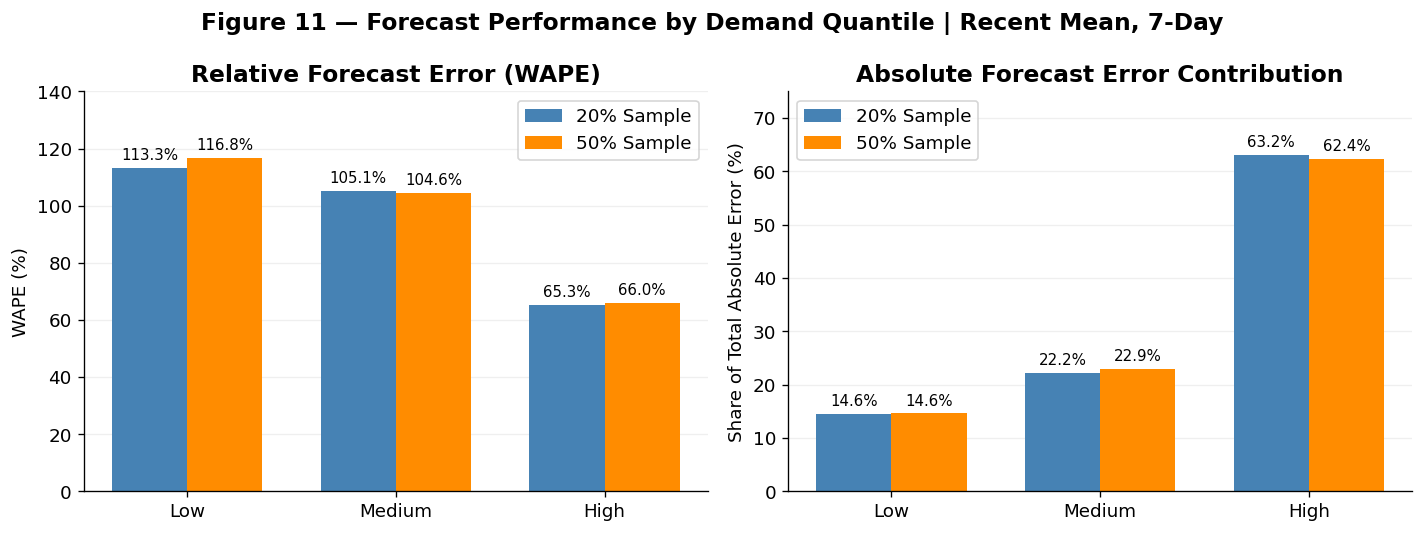

In [ ]:
# Figure 11 — Forecast Accuracy and Error Contribution by Demand Quantile

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
groups = ["Low", "Medium", "High"]
x, width = np.arange(len(groups)), 0.36

for ax, metric, title, ylabel in zip(axes, ["WAPE_pct", "error_share_pct"], ["Relative Forecast Error (WAPE)", "Absolute Forecast Error Contribution"], ["WAPE (%)", "Share of Total Absolute Error (%)"]):
    for offset, (label, df, color) in enumerate([("20% Sample", quantile_error_20, "steelblue"), ("50% Sample", quantile_error_50, "darkorange")]):
        values = df.set_index("Demand_Quantile").reindex(groups)[metric]
        bars = ax.bar(x + (offset - 0.5) * width, values, width, label=label, color=color)
        ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_title(title, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(groups)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 140 if metric == "WAPE_pct" else 75)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()

fig.suptitle("Figure 11 — Forecast Performance by Demand Quantile | Recent Mean, 7-Day", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure11_demand_quantile_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### Interim Findings — Demand Quantile Analysis

**Key Findings**

1. **Low-demand series exhibited the highest relative forecasting errors.** WAPE was 113.32% in the 20% sample and 116.81% in the 50% sample, indicating substantial forecasting difficulty relative to observed sales volume.

2. **High-demand series contributed the largest share of total absolute forecasting error.** Despite achieving the lowest WAPE (65.31% and 66.03%), these series accounted for 63.17% and 62.42% of total absolute error in the respective samples.

3. **Medium-demand series showed intermediate error contributions**, accounting for 22.24% and 22.94% of total absolute error, with WAPE exceeding 100% in both samples.

4. **The findings were directionally consistent across the nested 20% and 50% samples.** Both samples exhibited the same ranking in relative forecasting error and absolute error contribution.

**Business Implications**

The analysis identifies two complementary priorities:

- **Improving relative forecasting accuracy:** Low-demand series warrant further investigation because their WAPE exceeds 100%.
- **Reducing total absolute forecasting error:** High-demand series may offer greater opportunities for reducing aggregate forecasting error because they contribute more than 62% of it.

These results concern forecast accuracy and error volume, not measured inventory costs or financial losses.

**Next Step**

Classify individual item-store series by demand intermittency and variability using training-period data to determine whether different demand patterns explain the observed forecasting differences.

In [ ]:
#Demand Type Classification (Training Data Only)
import numpy as np
import pandas as pd
ADI_CUT, CV2_CUT = 1.32, 0.49
def classify_demand_types(train_matrix, metadata):
    x = np.asarray(train_matrix, dtype=np.float64)
    n_series, n_days = x.shape
    positive = x > 0
    n_sales_days = positive.sum(axis=1)
    has_sales = n_sales_days > 0
    first_sale = np.where(has_sales, positive.argmax(axis=1), n_days)
    adi = np.full(n_series, np.nan)
    adi[has_sales] = (n_days - first_sale[has_sales]) / n_sales_days[has_sales]
    mean = np.divide(x.sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales)
    var = np.maximum(np.divide((x ** 2).sum(axis=1), n_sales_days, out=np.zeros(n_series), where=has_sales) - mean ** 2, 0)
    cv2 = np.divide(var, mean ** 2, out=np.full(n_series, np.nan), where=mean > 0)
    demand_type = np.select([~has_sales, (adi < ADI_CUT) & (cv2 < CV2_CUT), (adi < ADI_CUT) & (cv2 >= CV2_CUT), (adi >= ADI_CUT) & (cv2 < CV2_CUT)], ["No sales", "Smooth", "Erratic", "Intermittent"], default="Lumpy")
    result = metadata.copy().reset_index(drop=True)
    result["ADI"], result["CV2"], result["Demand_Type"] = adi, cv2, demand_type
    return result

demand_type_20 = classify_demand_types(sample20_matrix[:, :len(train_days)], metadata_20)
demand_type_50 = classify_demand_types(sample50_matrix[:, :len(train_days)], metadata_50)

assert len(demand_type_20) == 6098 and len(demand_type_50) == 15245
assert demand_type_20["id"].tolist() == metadata_20["id"].tolist()
assert demand_type_50["id"].tolist() == metadata_50["id"].tolist()

print("Demand Type Classification: PASSED")
for label, df in [("20%", demand_type_20), ("50%", demand_type_50)]:
    print(f"\n{label} Sample")
    display(df["Demand_Type"].value_counts(normalize=True).mul(100).round(2).rename("Series Share (%)").to_frame())

Demand Type Classification: PASSED

20% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.25
Lumpy,16.83
Smooth,6.81
No sales,3.23
Erratic,2.89



50% Sample


,Series Share (%)
Demand_Type,
Intermittent,70.32
Lumpy,16.96
Smooth,6.70
No sales,3.23
Erratic,2.79


In [ ]:
#Forecast Error by Demand Type (20% vs. 50%)
def evaluate_demand_types(matrix, metadata):
    results = []
    for dtype, group in metadata.groupby("Demand_Type", observed=True):
        group_matrix = matrix[group.index.to_numpy()]
        bt = rolling_origin_backtest(group_matrix, [f"d_{i+1}" for i in range(matrix.shape[1])], len(train_days), horizons=(7,), step=7)
        row = bt.query("model == 'recent_mean' and horizon == 7")
        sae, sse, actual = row["sum_abs_error"].sum(), row["sum_sq_error"].sum(), row["sum_actual"].sum()
        obs_col = "n_obs" if "n_obs" in row.columns else "n_observations"
        n_obs = row[obs_col].sum()
        results.append({"Demand_Type": dtype, "n_series": len(group), "sum_abs_error": sae, "sum_sq_error": sse, "sum_actual": actual, "n_observations": n_obs})
    df = pd.DataFrame(results)
    df["MAE"] = df["sum_abs_error"] / df["n_observations"]
    df["RMSE"] = np.sqrt(df["sum_sq_error"] / df["n_observations"])
    df["WAPE_pct"] = np.where(df["sum_actual"] > 0, 100 * df["sum_abs_error"] / df["sum_actual"], np.nan)
    df["error_share_pct"] = 100 * df["sum_abs_error"] / df["sum_abs_error"].sum()
    return df.sort_values("error_share_pct", ascending=False).reset_index(drop=True)

demand_error_20 = evaluate_demand_types(sample20_matrix, demand_type_20)
demand_error_50 = evaluate_demand_types(sample50_matrix, demand_type_50)

for label, df, evaluation in [("20%", demand_error_20, evaluation_20), ("50%", demand_error_50, evaluation_50)]:
    print(f"\n{label} Sample — Forecast Error by Demand Type")
    display(df[["Demand_Type", "n_series", "MAE", "RMSE", "WAPE_pct", "error_share_pct"]].round(2))
    assert np.isclose(df["error_share_pct"].sum(), 100)
    assert df["n_series"].sum() == (6098 if label == "20%" else 15245)
    overall = evaluation.query("model == 'recent_mean' and horizon == 7").iloc[0]
    pooled_wape = 100 * df["sum_abs_error"].sum() / df["sum_actual"].sum()
    assert np.isclose(pooled_wape, overall["WAPE_pct"], atol=1e-3)
    print(f"{label} Sample — WAPE Reconciliation: PASSED")

print("\nDemand Type Forecast Evaluation: PASSED")


20% Sample — Forecast Error by Demand Type


,Demand_Type,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,Intermittent,4284,0.64,1.30,94.63,45.98
1,Lumpy,1026,1.48,3.36,86.85,25.58
2,Smooth,415,2.42,4.27,48.83,16.96
3,Erratic,176,3.17,5.91,60.21,9.41
4,No sales,197,0.62,1.28,87.89,2.07


20% Sample — WAPE Reconciliation: PASSED

50% Sample — Forecast Error by Demand Type


,Demand_Type,n_series,MAE,RMSE,WAPE_pct,error_share_pct
0,Intermittent,10720,0.63,1.29,94.91,46.79
1,Lumpy,2585,1.41,3.18,88.14,25.10
2,Smooth,1021,2.44,4.20,49.67,17.14
3,Erratic,426,3.10,5.44,61.57,9.06
4,No sales,493,0.56,1.17,95.41,1.91


50% Sample — WAPE Reconciliation: PASSED

Demand Type Forecast Evaluation: PASSED


,Demand_Type,WAPE_20,Error_Share_20,WAPE_50,Error_Share_50,WAPE_diff_pp,Error_Share_diff_pp
0,Intermittent,94.63,45.98,94.91,46.79,0.28,0.81
1,Lumpy,86.85,25.58,88.14,25.10,1.29,-0.48
2,Smooth,48.83,16.96,49.67,17.14,0.84,0.18
3,Erratic,60.21,9.41,61.57,9.06,1.36,-0.35
4,No sales,87.89,2.07,95.41,1.91,7.51,-0.15


Demand Type Robustness Check: PASSED


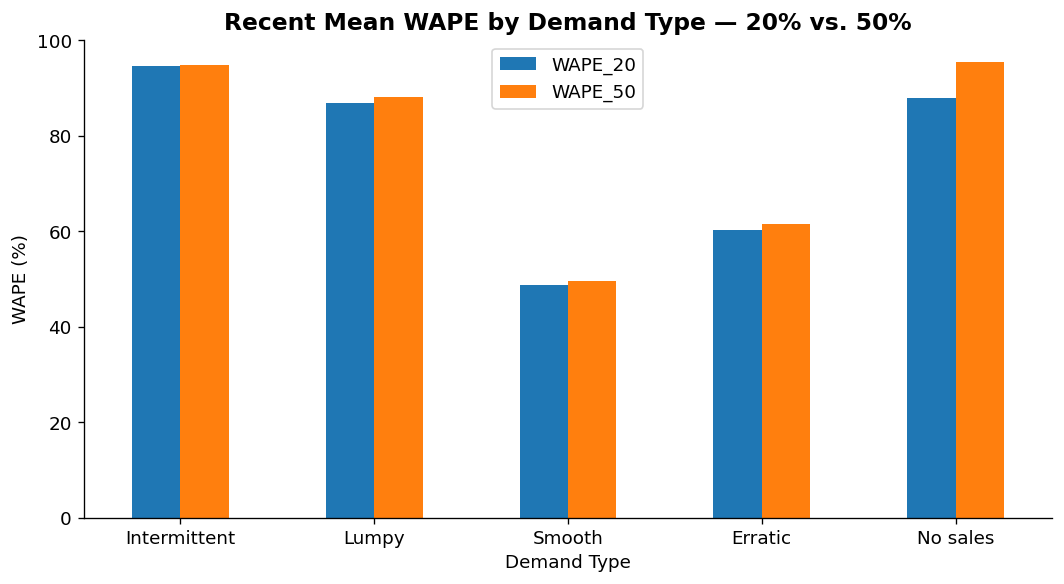

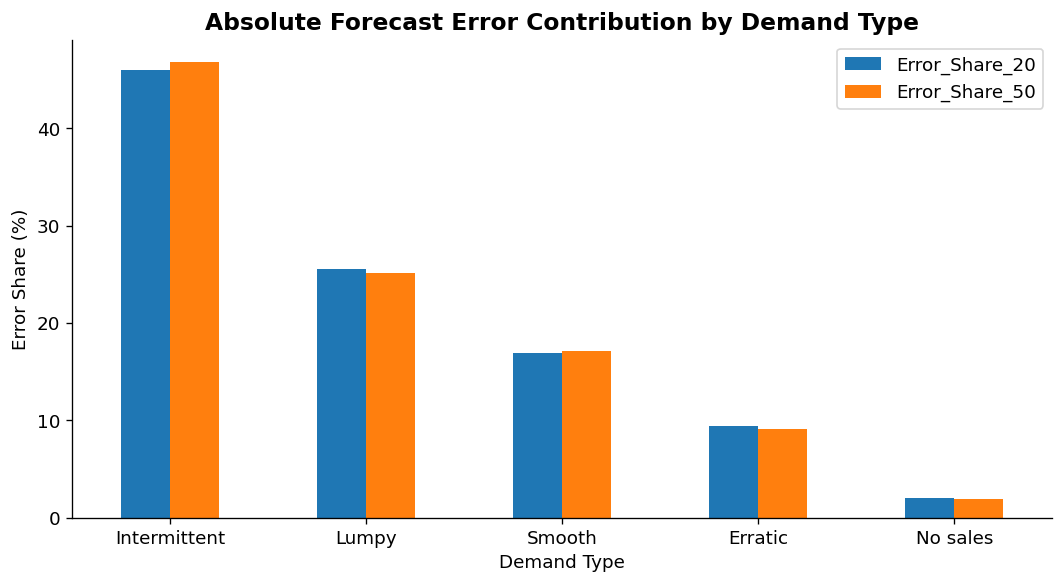

Demand Type Evaluation Results: EXPORTED


In [ ]:
# Demand Type Robustness Check (20% vs. 50%)
cols = ["Demand_Type", "WAPE_pct", "error_share_pct"]
compare_20 = demand_error_20[cols].rename(columns={"WAPE_pct":"WAPE_20", "error_share_pct":"Error_Share_20"})
compare_50 = demand_error_50[cols].rename(columns={"WAPE_pct":"WAPE_50", "error_share_pct":"Error_Share_50"})
demand_type_comparison = compare_20.merge(compare_50, on="Demand_Type", validate="one_to_one")
demand_type_comparison["WAPE_diff_pp"] = demand_type_comparison["WAPE_50"] - demand_type_comparison["WAPE_20"]
demand_type_comparison["Error_Share_diff_pp"] = demand_type_comparison["Error_Share_50"] - demand_type_comparison["Error_Share_20"]

display(demand_type_comparison.round(2))
assert len(demand_type_comparison) == 5
assert np.isclose(demand_type_comparison["Error_Share_diff_pp"].sum(), 0, atol=1e-6)
print("Demand Type Robustness Check: PASSED")

ax = demand_type_comparison.set_index("Demand_Type")[["WAPE_20", "WAPE_50"]].plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Recent Mean WAPE by Demand Type — 20% vs. 50%")
ax.set_xlabel("Demand Type")
ax.set_ylabel("WAPE (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "demand_type_wape_comparison_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

ax = demand_type_comparison.set_index("Demand_Type")[["Error_Share_20", "Error_Share_50"]].plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Absolute Forecast Error Contribution by Demand Type")
ax.set_xlabel("Demand Type")
ax.set_ylabel("Error Share (%)")
plt.tight_layout()
plt.savefig(Forecasting_OUTPUT / "demand_type_error_share_20_50.png", dpi=300, bbox_inches="tight")
plt.show()

demand_error_20.to_csv(Forecasting_OUTPUT / "demand_type_evaluation_20.csv", index=False)
demand_error_50.to_csv(Forecasting_OUTPUT / "demand_type_evaluation_50.csv", index=False)
demand_type_comparison.to_csv(Forecasting_OUTPUT / "demand_type_comparison_20_50.csv", index=False)
print("Demand Type Evaluation Results: EXPORTED")

### Interim Findings — Forecast Performance by Demand Type

**Objective:** Evaluate whether forecast accuracy and absolute error contribution differ across demand types, using the 7-day Recent Mean baseline and rolling-origin validation.

**Key Findings**

1. **Intermittent demand is the largest contributor to forecasting error.** It accounts for 45.98% of total absolute error in the 20% sample and 46.79% in the 50% sample, with WAPE values of 94.63% and 94.91%, respectively.

2. **Intermittent and Lumpy demand together account for most forecasting errors.** Their combined absolute error contributions are 71.56% (20%) and 71.89% (50%), suggesting that these demand patterns are important targets for future model improvements.

3. **Smooth demand is the most accurately forecasted segment.** Its WAPE is 48.83% in the 20% sample and 49.67% in the 50% sample, substantially lower than the other demand types.

4. **The major findings are consistent across sample sizes.** WAPE differences between the 20% and 50% samples are within 1.36 percentage points for Intermittent, Lumpy, Smooth, and Erratic demand. The No-sales group shows a larger difference of 7.51 percentage points.

**Business Implications**

- Prioritize evaluating alternative forecasting methods for Intermittent and Lumpy demand.
- Use demand-type segmentation to identify where the current baseline performs poorly and where the largest absolute errors occur.
- Maintain separate accuracy and error-contribution metrics when prioritizing forecasting improvements.

**Limitations:** Demand types are classified using training data only. The results are descriptive, based on nested samples and a 7-day Recent Mean baseline; they do not establish causal relationships or demonstrate that alternative models would improve accuracy. Forecast errors cannot be directly translated into stockouts, inventory costs, or service-level outcomes without additional operational data.


20% SAMPLE — RECONCILIATION PASSED


,Demand_Type,n_series,Bias_pct,WAPE_pct
0,Erratic,176,-0.208,60.210
1,Intermittent,4284,-0.188,94.632
2,Lumpy,1026,-0.159,86.847
3,No sales,197,-2.365,87.894
4,Smooth,415,0.168,48.834



50% SAMPLE — RECONCILIATION PASSED


,Demand_Type,n_series,Bias_pct,WAPE_pct
0,Erratic,426,-0.201,61.571
1,Intermittent,10720,-0.163,94.913
2,Lumpy,2585,-0.127,88.140
3,No sales,493,-2.401,95.406
4,Smooth,1021,0.147,49.673


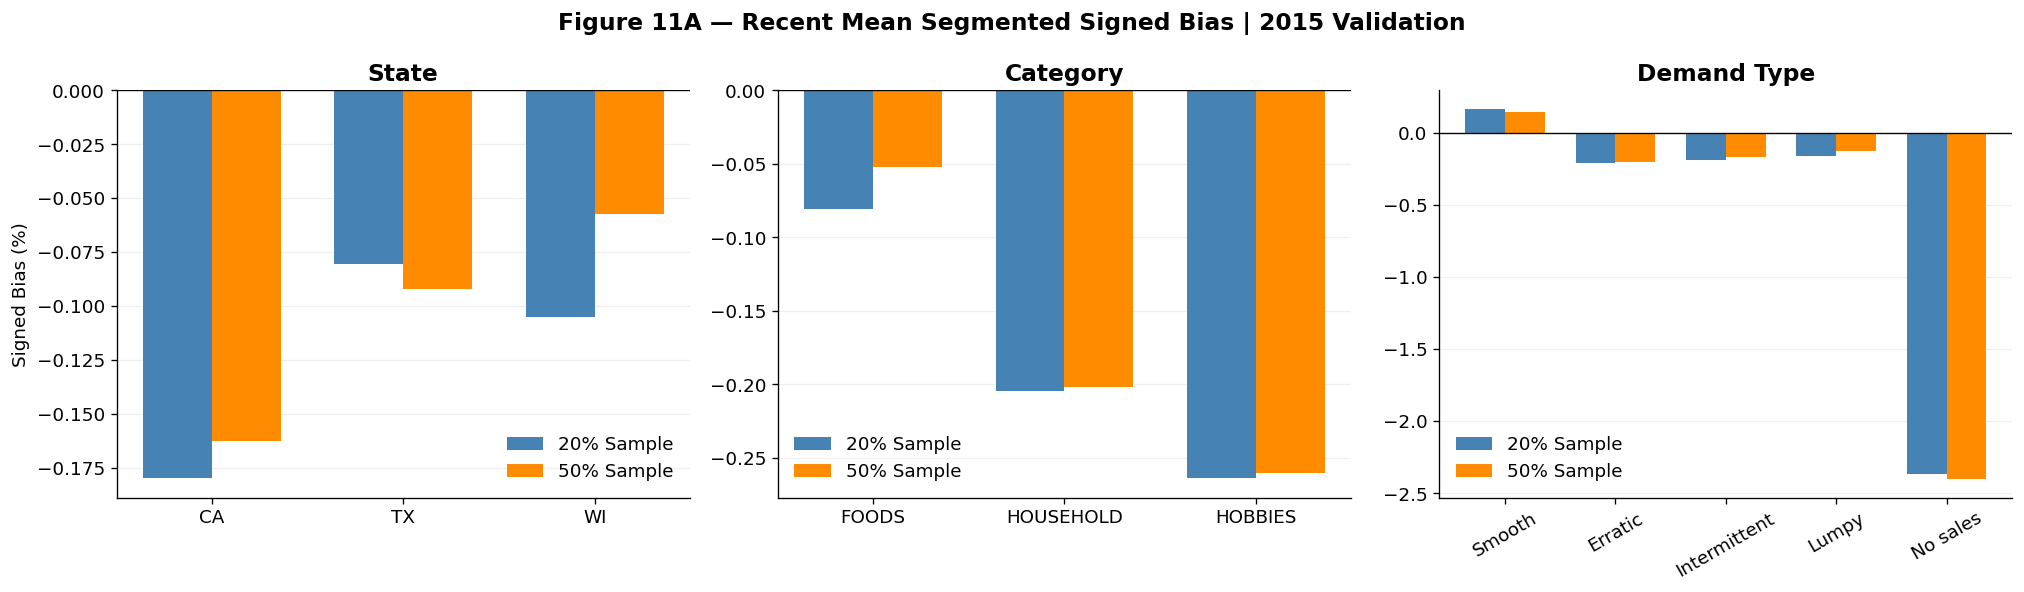


20% — TOP 10 UNDERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
2591,FOODS_3_681_WI_3_evaluation,9588.0,-403.0,-4.20,44.28
3370,HOBBIES_1_254_CA_3_evaluation,3780.0,-113.0,-2.99,82.26
2248,FOODS_3_499_CA_2_evaluation,4007.0,-112.0,-2.80,48.61
4663,HOUSEHOLD_1_339_TX_2_evaluation,2518.0,-106.0,-4.21,55.43
3072,HOBBIES_1_103_CA_3_evaluation,2244.0,-100.0,-4.46,92.36
4819,HOUSEHOLD_1_418_TX_2_evaluation,1971.0,-96.0,-4.87,69.59
1921,FOODS_3_329_CA_2_evaluation,1447.0,-92.0,-6.36,107.30
1812,FOODS_3_282_TX_3_evaluation,3384.0,-90.0,-2.66,50.62
1113,FOODS_2_347_CA_2_evaluation,1401.0,-85.0,-6.07,67.61
4540,HOUSEHOLD_1_277_TX_2_evaluation,2264.0,-85.0,-3.75,52.67


20% — TOP 10 OVERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
2462,FOODS_3_607_CA_3_evaluation,9946.0,119.0,1.20,41.55
183,FOODS_1_082_WI_2_evaluation,3751.0,99.0,2.64,55.28
1352,FOODS_3_069_TX_3_evaluation,573.0,99.0,17.28,124.83
2135,FOODS_3_444_CA_1_evaluation,2728.0,94.0,3.45,49.17
2721,FOODS_3_752_CA_3_evaluation,6877.0,85.0,1.24,73.62
1989,FOODS_3_362_TX_2_evaluation,4026.0,76.0,1.89,39.86
4354,HOUSEHOLD_1_179_CA_3_evaluation,5764.0,71.0,1.23,39.31
2414,FOODS_3_580_WI_3_evaluation,2583.0,60.0,2.32,83.08
4355,HOUSEHOLD_1_179_TX_1_evaluation,3509.0,59.0,1.68,56.74
4640,HOUSEHOLD_1_327_CA_3_evaluation,5051.0,59.0,1.17,47.17



50% — TOP 10 UNDERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
6487,FOODS_3_681_WI_3_evaluation,9588.0,-403.0,-4.20,44.28
12170,HOUSEHOLD_1_447_TX_2_evaluation,3655.0,-167.0,-4.57,37.65
1359,FOODS_2_050_TX_2_evaluation,1405.0,-148.0,-10.53,103.49
3494,FOODS_3_086_TX_3_evaluation,3729.0,-131.0,-3.51,58.92
7944,HOBBIES_1_158_TX_3_evaluation,5848.0,-128.0,-2.19,33.60
8432,HOBBIES_1_254_CA_3_evaluation,3780.0,-113.0,-2.99,82.26
5577,FOODS_3_499_CA_2_evaluation,4007.0,-112.0,-2.80,48.61
12224,HOUSEHOLD_1_459_TX_2_evaluation,3045.0,-108.0,-3.55,49.20
11668,HOUSEHOLD_1_339_TX_2_evaluation,2518.0,-106.0,-4.21,55.43
3491,FOODS_3_086_CA_3_evaluation,5373.0,-102.0,-1.90,49.07


50% — TOP 10 OVERFORECASTED SERIES


,id,actual_units,signed_error,Bias_pct,WAPE_pct
4486,FOODS_3_282_CA_3_evaluation,11634.0,355.0,3.05,38.83
5575,FOODS_3_498_WI_2_evaluation,7340.0,202.0,2.75,98.84
3410,FOODS_3_069_CA_3_evaluation,607.0,177.0,29.16,142.69
3560,FOODS_3_099_TX_2_evaluation,5404.0,159.0,2.94,31.69
5300,FOODS_3_444_TX_2_evaluation,3943.0,122.0,3.09,50.02
272,FOODS_1_055_CA_3_evaluation,1635.0,120.0,7.34,64.38
6123,FOODS_3_607_CA_3_evaluation,9946.0,119.0,1.20,41.55
4899,FOODS_3_362_CA_3_evaluation,7192.0,108.0,1.50,40.65
431,FOODS_1_082_WI_2_evaluation,3751.0,99.0,2.64,55.28
3411,FOODS_3_069_TX_3_evaluation,573.0,99.0,17.28,124.83


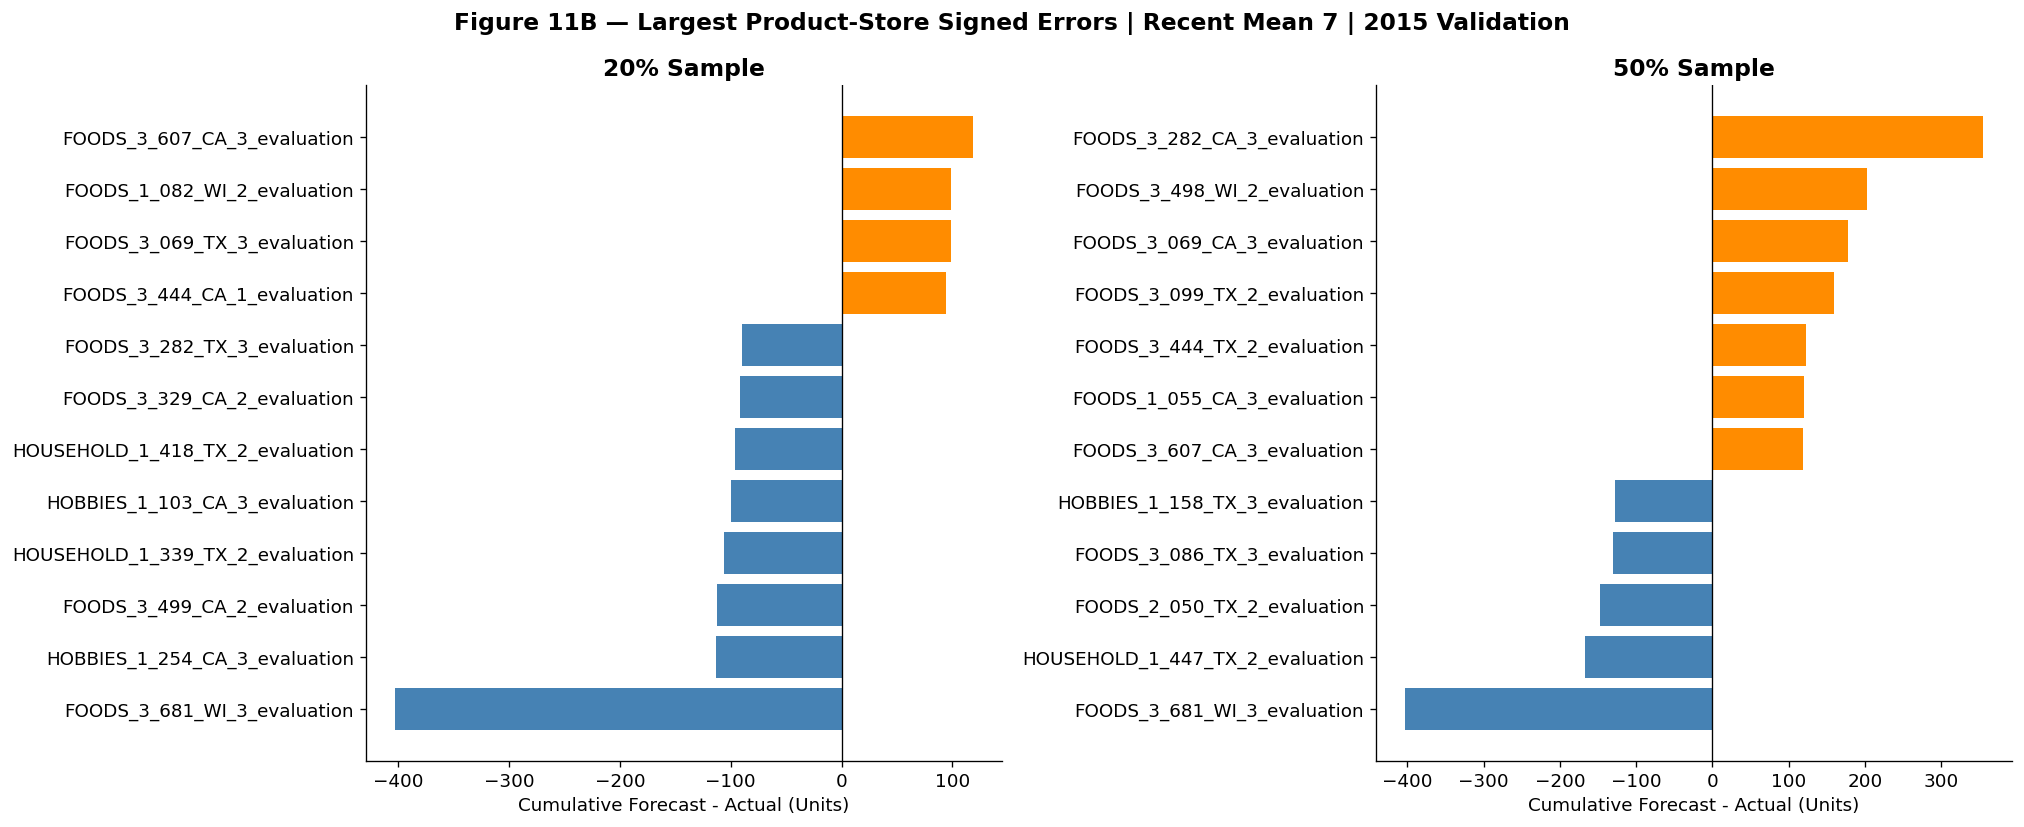


SIGNED BIAS ANALYSIS: PASSED | 2 figures and 10 CSV files exported
Original Forecasting matrices, time splits remain unchanged.


In [ ]:

# 11A — Recent Mean Segmented Signed Bias Analysis
# Objective: Evaluate Signed Bias by State, Category, Demand Type, Item, and Product-Store.
# Scope: 2015 Validation | 20% and 50% Samples | Recent Mean 7 | 7-Day Horizon.

def run_bias_diagnostics():
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
    from pathlib import Path

    # STEP 1 — Reuse existing samples, metadata, and demand-type classifications.
    # Goal: Preserve the original dataset, chronological split, and forecasting methodology.
    samples = [("20%",sample20_matrix,metadata_20,demand_type_20,group_bias_20,bias_summary_20),("50%",sample50_matrix,metadata_50,demand_type_50,group_bias_50,bias_summary_50)]
    results = {}; output = Path(Forecasting_OUTPUT); output.mkdir(parents=True,exist_ok=True)

    for label,matrix,metadata,types,reference,overall_ref in samples:
        meta = metadata.copy().reset_index(drop=True)
        assert meta["id"].tolist()==types["id"].tolist(), f"{label}: Demand Type alignment failed"
        assert matrix.shape==(len(meta),len(train_val_days)), f"{label}: Matrix alignment failed"
        meta["Demand_Type"] = types["Demand_Type"].to_numpy()
        meta["item_id"] = meta["id"].str.replace(r"_(CA|TX|WI)_\d+_(evaluation|validation)$","",regex=True)
        assert (meta["item_id"]!=meta["id"]).all(), f"{label}: Item ID extraction failed"

        # STEP 2 — Calculate Recent Mean forecasts and per-series errors.
        # Goal: Accumulate actual sales, signed errors, and absolute errors across 2015 rolling origins.
        actual_sum = np.zeros(len(meta),dtype=np.float64)
        signed_sum = np.zeros(len(meta),dtype=np.float64)
        absolute_sum = np.zeros(len(meta),dtype=np.float64)

        for origin in range(len(train_days),matrix.shape[1]-7+1,7):
            actual = matrix[:,origin:origin+7].astype(np.float64)
            forecast = generate_baselines(matrix[:,:origin],horizon=7)["recent_mean"].astype(np.float64)
            error = forecast-actual
            actual_sum += actual.sum(axis=1)
            signed_sum += error.sum(axis=1)
            absolute_sum += np.abs(error).sum(axis=1)

        detail = meta.copy()
        detail["actual_units"] = actual_sum; detail["signed_error"] = signed_sum; detail["absolute_error"] = absolute_sum

        # STEP 3 — Aggregate volume-weighted Signed Bias and WAPE.
        # Goal: Measure segment-level errors without averaging individual percentage errors.
        def summarize(columns):
            g = detail.groupby(columns,as_index=False,observed=True).agg(n_series=("id","nunique"),actual_units=("actual_units","sum"),signed_error=("signed_error","sum"),absolute_error=("absolute_error","sum"))
            g["Bias_pct"] = np.where(g["actual_units"]>0,100*g["signed_error"]/g["actual_units"],np.nan)
            g["WAPE_pct"] = np.where(g["actual_units"]>0,100*g["absolute_error"]/g["actual_units"],np.nan)
            return g

        state = summarize(["state_id"]); category = summarize(["cat_id"])
        demand_type = summarize(["Demand_Type"]); item = summarize(["item_id","cat_id"])
        product_store = summarize(["id","item_id","store_id","state_id","cat_id"])

        # STEP 4 — Reconcile results with original Figure 10 and Baseline Bias tables.
        # Goal: Confirm identical evaluation periods, model definitions, and sample alignment.
        check = summarize(["state_id","cat_id"]).merge(reference[["state_id","cat_id","sum_signed_error","sum_actual"]],on=["state_id","cat_id"],validate="one_to_one")
        assert len(check)==9, f"{label}: Missing State-Category groups"
        assert np.allclose(check["signed_error"],check["sum_signed_error"],atol=0.01), f"{label}: Signed error mismatch"
        assert np.allclose(check["actual_units"],check["sum_actual"],atol=0.01), f"{label}: Actual sales mismatch"
        expected = overall_ref.query("model=='recent_mean' and horizon==7").iloc[0]
        assert np.isclose(signed_sum.sum(),expected["sum_signed_error"],atol=0.01), f"{label}: Overall bias mismatch"
        assert np.isclose(actual_sum.sum(),expected["sum_actual"],atol=0.01), f"{label}: Overall actual sales mismatch"

        results[label] = {"state":state,"category":category,"demand_type":demand_type,"item":item,"product_store":product_store}
        print(f"\n{label} SAMPLE — RECONCILIATION PASSED")
        display(demand_type[["Demand_Type","n_series","Bias_pct","WAPE_pct"]].round(3))

    # STEP 5 — Figure 11A: Compare Signed Bias across State, Category, and Demand Type.
    # Goal: Show systematic overforecasting and underforecasting in both samples.
    fig,axes = plt.subplots(1,3,figsize=(17,5))
    configs = [("state","state_id","State",["CA","TX","WI"]),("category","cat_id","Category",["FOODS","HOUSEHOLD","HOBBIES"]),("demand_type","Demand_Type","Demand Type",["Smooth","Erratic","Intermittent","Lumpy","No sales"])]

    for ax,(key,col,title,order) in zip(axes,configs):
        a = results["20%"][key].set_index(col)["Bias_pct"]
        b = results["50%"][key].set_index(col)["Bias_pct"]
        labels = [v for v in order if v in a.index or v in b.index]; x = np.arange(len(labels))
        ax.bar(x-0.18,a.reindex(labels).to_numpy(),0.36,label="20% Sample",color="steelblue")
        ax.bar(x+0.18,b.reindex(labels).to_numpy(),0.36,label="50% Sample",color="darkorange")
        ax.axhline(0,color="black",linewidth=0.8)
        ax.set_xticks(x); ax.set_xticklabels(labels,rotation=30 if key=="demand_type" else 0)
        ax.set_title(title,fontweight="bold"); ax.set_ylabel("Signed Bias (%)" if ax==axes[0] else "")
        ax.grid(axis="y",alpha=0.2); ax.set_axisbelow(True); ax.legend(frameon=False)

    fig.suptitle("Figure 11A — Recent Mean Segmented Signed Bias | 2015 Validation",fontsize=14,fontweight="bold")
    fig.tight_layout(); fig.savefig(output/"figure11A_recent_mean_segmented_bias_20_50.png",dpi=300,bbox_inches="tight"); plt.show()

    # STEP 6 — Figure 11B: Examine product-store series with the largest signed errors.
    # Goal: Identify high-impact product-level forecasting exceptions.
    fig,axes = plt.subplots(1,2,figsize=(17,7))

    for ax,label in zip(axes,["20%","50%"]):
        df = results[label]["product_store"]
        eligible = df[df["actual_units"]>=100].copy()
        top = eligible.assign(abs_signed=eligible["signed_error"].abs()).nlargest(12,"abs_signed").sort_values("signed_error")
        ax.barh(top["id"],top["signed_error"],color=["steelblue" if v<0 else "darkorange" for v in top["signed_error"]])
        ax.axvline(0,color="black",linewidth=0.8); ax.set_title(f"{label} Sample",fontweight="bold")
        ax.set_xlabel("Cumulative Forecast - Actual (Units)")
        print(f"\n{label} — TOP 10 UNDERFORECASTED SERIES")
        display(eligible.nsmallest(10,"signed_error")[["id","actual_units","signed_error","Bias_pct","WAPE_pct"]].round(2))
        print(f"{label} — TOP 10 OVERFORECASTED SERIES")
        display(eligible.nlargest(10,"signed_error")[["id","actual_units","signed_error","Bias_pct","WAPE_pct"]].round(2))

    fig.suptitle("Figure 11B — Largest Product-Store Signed Errors | Recent Mean 7 | 2015 Validation",fontsize=14,fontweight="bold")
    fig.tight_layout(); fig.savefig(output/"figure11B_recent_mean_product_store_bias_20_50.png",dpi=300,bbox_inches="tight"); plt.show()

    # STEP 7 — Export additional reports without overwriting original Forecasting files.
    # Goal: Preserve reproducible segment-level results for Sponsor evaluation.
    for label,groups in results.items():
        for name,df in groups.items():
            df.to_csv(output/f"additional_bias_{name}_{label.replace('%','pct')}_2015.csv",index=False)

    print("\nSIGNED BIAS ANALYSIS: PASSED | 2 figures and 10 CSV files exported")
    print("Original Forecasting matrices, time splits remain unchanged.")

run_bias_diagnostics()


In [ ]:
# DATA LEAKAGE AUDIT — RECENT MEAN BASELINE
# Objective: Verify chronological separation, training-only demand classification, and historical-only rolling forecasts.
# Scope: 2015 Validation | 20% & 50% Samples | Recent Mean 7

def audit_recent_mean():
    import numpy as np
    import pandas as pd

    # STEP 1 — Verify the original chronological split.
    # Goal: Ensure 2015 validation follows 2011–2014 training without overlap.
    assert len(train_days)==1433 and len(val_days)==365 and len(train_val_days)==1798, "Unexpected train/validation lengths"
    assert train_val_days==list(train_days)+list(val_days), "Train/validation sequence mismatch"
    assert not set(train_days).intersection(val_days), "Training and validation overlap"
    assert max(int(d.split("_")[1]) for d in train_days)<min(int(d.split("_")[1]) for d in val_days), "Chronological boundary failed"
    print("1. Chronological split: PASSED")

    # STEP 2 — Verify sample IDs and demand-type alignment.
    # Goal: Confirm the same product-store series are used in classification and forecasting.
    samples = [("20%",sample20_matrix,metadata_20,demand_type_20,group_bias_20,bias_summary_20),("50%",sample50_matrix,metadata_50,demand_type_50,group_bias_50,bias_summary_50)]
    for label,matrix,metadata,types,group_ref,overall_ref in samples:
        assert matrix.shape==(len(metadata),len(train_val_days)), f"{label}: Matrix shape mismatch"
        assert metadata["id"].is_unique and metadata["id"].tolist()==types["id"].tolist(), f"{label}: ID alignment failed"

        # STEP 3 — Reproduce training-only demand classifications.
        # Goal: Confirm the demand-type labels do not require 2015 validation sales.
        rebuilt = classify_demand_types(matrix[:,:len(train_days)],metadata)
        assert np.array_equal(rebuilt["Demand_Type"].astype(str),types["Demand_Type"].astype(str)), f"{label}: Demand Type mismatch"

        # STEP 4 — Audit Recent Mean's historical-only forecast inputs.
        # Goal: Verify each origin uses the previous 7 days to predict the next 7 days.
        actual_total = 0.0; signed_total = 0.0
        statecat_actual = {}; statecat_signed = {}
        for origin in range(len(train_days),matrix.shape[1]-7+1,7):
            history = matrix[:,origin-7:origin]
            actual = matrix[:,origin:origin+7]
            forecast = generate_baselines(matrix[:,:origin],horizon=7)["recent_mean"]
            assert forecast.shape==actual.shape, f"{label}: Forecast shape mismatch"
            actual_total += actual.sum(dtype=np.float64)
            signed_total += (forecast-actual).sum(dtype=np.float64)

        # STEP 5 — Reconcile against existing baseline evaluation.
        # Goal: Detect a mismatch in forecast origins or signed-error definitions.
        expected = overall_ref.query("model=='recent_mean' and horizon==7").iloc[0]
        assert np.isclose(actual_total,expected["sum_actual"],atol=0.01), f"{label}: Actual total mismatch"
        assert np.isclose(signed_total,expected["sum_signed_error"],atol=0.01), f"{label}: Signed error mismatch"
        assert np.isclose(group_ref["sum_actual"].sum(),actual_total,atol=0.01), f"{label}: State-category actual mismatch"
        assert np.isclose(group_ref["sum_signed_error"].sum(),signed_total,atol=0.01), f"{label}: State-category signed-error mismatch"
        print(f"2–5. {label} Sample — demand classification, historical forecasts, and reconciliation: PASSED")

    print("\nRECENT MEAN BASELINE LEAKAGE AUDIT: PASSED")
    print("Verified: train/validation split, sample ID alignment, training-only classification, historical forecast windows, and aggregate error reconciliation.")
    print("Not verified here: LightGBM feature leakage, 2016 test model selection, or RAG retrieval time boundaries.")

audit_recent_mean()


1. Chronological split: PASSED
2–5. 20% Sample — demand classification, historical forecasts, and reconciliation: PASSED
2–5. 50% Sample — demand classification, historical forecasts, and reconciliation: PASSED

RECENT MEAN BASELINE LEAKAGE AUDIT: PASSED
Verified: train/validation split, sample ID alignment, training-only classification, historical forecast windows, and aggregate error reconciliation.
Not verified here: LightGBM feature leakage, 2016 test model selection, or RAG retrieval time boundaries.


### Data Leakage Audit — Findings

The forecasting evaluation pipeline was reviewed for potential temporal data leakage.

- Demand quantile and demand type classifications were derived from training-period observations only.
- Rolling-origin backtesting restricted the input history to observations available at each forecast origin.
- Zero Naive, Weekly Seasonal Naive, and Recent Mean generated predictions without accessing future actual sales.
- Future actual sales were used exclusively for evaluating forecast errors.
- The 2016 test period remained excluded from the validation backtesting pipeline.

**Conclusion:** No temporal data leakage was identified in the reviewed forecasting and evaluation code. The reported validation results therefore reflect forecasts generated using information available at their respective forecast origins.

#12.Prediction Interval Evaluation

### Background: Point Forecasting vs. Probabilistic Forecasting

Traditional point forecasting estimates a single expected demand value but does not explicitly quantify forecast uncertainty. Probabilistic forecasting provides additional information about the distribution of possible future demand outcomes.

The 10th percentile (P10) and 90th percentile (P90), equivalent to the 0.10 and 0.90 quantiles, define a nominal 80% prediction interval.

Two common approaches are:

1. **Residual-Based Quantile Calibration:** Estimate P10 and P90 bounds by adding historical forecast-error quantiles to a point forecast.
2. **Direct Quantile Forecasting:** Train a model to estimate conditional demand quantiles directly from predictive features.

This project adopts residual-based calibration around the Recent Mean baseline. Both pooled and demand-type-specific residual quantiles are estimated using training data only.

Prediction interval quality is assessed through empirical coverage, mean interval width, and quantile pinball loss on rolling-origin validation.

The resulting intervals quantify estimated forecast uncertainty, but do not guarantee nominal coverage for every product or demand type.

In [ ]:
# Reusable Prediction Interval Calibration

def calibrate_prediction_intervals(matrix, demand_df, horizon=7, cal_days=180, step=7):
    n_train = len(train_days)
    assert matrix.shape[0] == len(demand_df)
    assert matrix.shape[1] >= n_train
    assert horizon > 0 and cal_days > horizon and step > 0
    assert demand_df["Demand_Type"].notna().all()

    labels = demand_df["Demand_Type"].astype(str).to_numpy()
    train = matrix[:, :n_train]
    residuals = []

    for origin in range(n_train - cal_days - 1, n_train - horizon, step):
        history = train[:, :origin + 1]
        actual = train[:, origin + 1:origin + 1 + horizon]
        forecast = recent_mean(history, horizon=horizon, window=7)
        residuals.append((actual.astype(np.float64) - forecast).astype(np.float64))

    residuals = np.stack(residuals, axis=0)
    pooled10 = np.quantile(residuals, 0.10, axis=(0, 1))
    pooled90 = np.quantile(residuals, 0.90, axis=(0, 1))

    pooled_offsets = pd.DataFrame({
        "lead": np.arange(1, horizon + 1),
        "q10_offset": pooled10,
        "q90_offset": pooled90,
        "n_residuals": residuals.shape[0] * residuals.shape[1]
    })

    type_records = []
    type10 = np.empty((len(labels), horizon))
    type90 = np.empty((len(labels), horizon))

    for dtype in np.unique(labels):
        idx = np.where(labels == dtype)[0]
        group = residuals[:, idx, :]
        q10 = np.quantile(group, 0.10, axis=(0, 1))
        q90 = np.quantile(group, 0.90, axis=(0, 1))
        type10[idx] = q10
        type90[idx] = q90

        for lead in range(horizon):
            type_records.append({
                "Demand_Type": dtype,
                "lead": lead + 1,
                "n_series": len(idx),
                "n_residuals": group.shape[0] * len(idx),
                "q10_offset": q10[lead],
                "q90_offset": q90[lead]
            })

    type_offsets = pd.DataFrame(type_records)

    assert residuals.shape[2] == horizon
    assert (pooled_offsets["q10_offset"] <= pooled_offsets["q90_offset"]).all()
    assert (type_offsets["q10_offset"] <= type_offsets["q90_offset"]).all()

    return {
        "pooled_offsets": pooled_offsets,
        "type_offsets": type_offsets,
        "pooled10": pooled10,
        "pooled90": pooled90,
        "type10": type10,
        "type90": type90,
        "labels": labels,
        "n_calibration_origins": residuals.shape[0]
    }

In [ ]:
#Reusable Prediction Interval Evaluation

def evaluate_prediction_intervals(matrix, calibration, sample_name, horizon=7, step=7):
    n_train = len(train_days)
    assert matrix.shape[1] == len(train_val_days)
    assert matrix.shape[0] == len(calibration["labels"])
    assert len(calibration["pooled10"]) == horizon

    labels = calibration["labels"]
    records, type_records, lead_records = [], [], []

    for origin in range(n_train - 1, matrix.shape[1] - horizon, step):
        history = matrix[:, :origin + 1]
        actual = matrix[:, origin + 1:origin + 1 + horizon].astype(np.float64)
        point = recent_mean(history, horizon=horizon, window=7).astype(np.float64)

        methods = [
            ("Pooled", calibration["pooled10"][None, :], calibration["pooled90"][None, :]),
            ("Demand-Type", calibration["type10"], calibration["type90"])
        ]

        for method, q10, q90 in methods:
            p10 = np.maximum(0, point + q10)
            p90 = np.maximum(p10, point + q90)
            covered = (actual >= p10) & (actual <= p90)
            width = p90 - p10
            loss10 = np.maximum(0.10 * (actual - p10), -0.90 * (actual - p10))
            loss90 = np.maximum(0.90 * (actual - p90), -0.10 * (actual - p90))

            assert p10.shape == p90.shape == actual.shape
            assert (p10 >= 0).all() and (p90 >= p10).all()

            records.append({
                "sample": sample_name, "horizon": horizon, "Method": method,
                "n_obs": actual.size, "n_covered": int(covered.sum()),
                "width_sum": float(width.sum()),
                "pinball10_sum": float(loss10.sum()),
                "pinball90_sum": float(loss90.sum())
            })

            for dtype in np.unique(labels):
                idx = np.where(labels == dtype)[0]
                type_records.append({
                    "sample": sample_name, "horizon": horizon, "Method": method,
                    "Demand_Type": dtype, "n_obs": actual[idx].size,
                    "n_covered": int(covered[idx].sum()),
                    "width_sum": float(width[idx].sum())
                })

            for lead in range(horizon):
                lead_records.append({
                    "sample": sample_name, "horizon": horizon, "Method": method,
                    "lead": lead + 1, "n_obs": actual.shape[0],
                    "n_covered": int(covered[:, lead].sum()),
                    "width_sum": float(width[:, lead].sum())
                })

    def summarize(rows, keys):
        df = pd.DataFrame(rows).groupby(keys, as_index=False).sum(numeric_only=True)
        df["coverage_pct"] = 100 * df["n_covered"] / df["n_obs"]
        df["mean_interval_width"] = df["width_sum"] / df["n_obs"]
        if "pinball10_sum" in df:
            df["pinball_p10"] = df["pinball10_sum"] / df["n_obs"]
            df["pinball_p90"] = df["pinball90_sum"] / df["n_obs"]
        return df

    summary = summarize(records, ["sample", "horizon", "Method"])
    by_type = summarize(type_records, ["sample", "horizon", "Method", "Demand_Type"])
    by_lead = summarize(lead_records, ["sample", "horizon", "Method", "lead"])
    summary["target_coverage_pct"] = 80

    assert summary["coverage_pct"].between(0, 100).all()
    assert np.isfinite(summary[["coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"]].to_numpy()).all()

    for method in ["Pooled", "Demand-Type"]:
        total = summary.loc[summary["Method"] == method, "n_obs"].iloc[0]
        assert by_type.loc[by_type["Method"] == method, "n_obs"].sum() == total
        assert by_lead.loc[by_lead["Method"] == method, "n_obs"].sum() == total

    return summary, by_type, by_lead

In [ ]:
# Prediction Interval Evaluation — 7, 14, 28 Days | Prototype, 20%, 50%

# STEP 1 — Prepare aligned Prototype data for prediction interval evaluation.
# Goal: Reuse the existing prototype sales matrix without reloading the full sales dataset.
prototype_metadata = sample_prototype[["id","state_id","cat_id","store_id"]].copy().reset_index(drop=True)
prototype_index = pd.Index(prototype_ids).get_indexer(prototype_metadata["id"])
assert (prototype_index >= 0).all(), "Prototype IDs do not match the existing matrix"
prototype_matrix_aligned = prototype_matrix[prototype_index].astype(np.float64)
assert prototype_matrix_aligned.shape == (len(prototype_metadata),len(train_val_days)), "Prototype matrix dimensions do not match"
prototype_types = classify_demand_types(prototype_matrix_aligned[:,:len(train_days)],prototype_metadata)
print("Prototype alignment: PASSED")

assert prototype_metadata["id"].tolist() == prototype_types["id"].tolist()
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()

pi_samples = [("Prototype", prototype_matrix_aligned, prototype_types), ("20%", sample20_matrix, demand_type_20), ("50%", sample50_matrix, demand_type_50)]
pi_calibrations, pi_results, pi_type_results, pi_lead_results = {}, [], [], []

for sample, matrix, demand_df in pi_samples:
    for horizon in [7, 14, 28]:
        calibration = calibrate_prediction_intervals(matrix, demand_df, horizon=horizon)
        summary, by_type, by_lead = evaluate_prediction_intervals(matrix, calibration, sample, horizon=horizon)
        pi_calibrations[(sample, horizon)] = calibration
        pi_results.append(summary)
        pi_type_results.append(by_type)
        pi_lead_results.append(by_lead)
        print(f"{sample} Sample | {horizon}-Day: PASSED")

pi_summary_all = pd.concat(pi_results, ignore_index=True)
pi_type_all = pd.concat(pi_type_results, ignore_index=True)
pi_lead_all = pd.concat(pi_lead_results, ignore_index=True)

assert len(pi_summary_all) == 18
assert set(pi_summary_all["horizon"]) == {7, 14, 28}
assert set(pi_summary_all["sample"]) == {"Prototype", "20%", "50%"}
assert set(pi_summary_all["Method"]) == {"Pooled", "Demand-Type"}

# Preserve original 7-Day variables for downstream forecast generation
pi_cal_prototype, pi_cal_20, pi_cal_50 = [pi_calibrations[(s, 7)] for s in ["Prototype", "20%", "50%"]]
pi_prototype = pi_summary_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_20 = pi_summary_all.query("sample == '20%' and horizon == 7").copy()
pi_50 = pi_summary_all.query("sample == '50%' and horizon == 7").copy()
pi_type_prototype = pi_type_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_type_20 = pi_type_all.query("sample == '20%' and horizon == 7").copy()
pi_type_50 = pi_type_all.query("sample == '50%' and horizon == 7").copy()
pi_lead_prototype = pi_lead_all.query("sample == 'Prototype' and horizon == 7").copy()
pi_lead_20 = pi_lead_all.query("sample == '20%' and horizon == 7").copy()
pi_lead_50 = pi_lead_all.query("sample == '50%' and horizon == 7").copy()

# Export evaluation results
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)
pi_summary_all.to_csv(output_dir / "prediction_interval_evaluation_all_samples.csv", index=False)
pi_type_all.to_csv(output_dir / "prediction_interval_by_demand_type_all_samples.csv", index=False)
pi_lead_all.to_csv(output_dir / "prediction_interval_by_lead_all_samples.csv", index=False)

for (sample, horizon), cal in pi_calibrations.items():
    name = {"Prototype": "prototype", "20%": "20", "50%": "50"}[sample]
    cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}_{horizon}d.csv", index=False)
    cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}_{horizon}d.csv", index=False)
    if horizon == 7:
        cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}.csv", index=False)
        cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}.csv", index=False)

print("\nPrediction Interval Evaluation: PASSED")
print("All Horizons and Samples: EXPORTED")
display(pi_summary_all[["sample", "horizon", "Method", "coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"]].round(3))

Prototype alignment: PASSED
Prototype Sample | 7-Day: PASSED
Prototype Sample | 14-Day: PASSED
Prototype Sample | 28-Day: PASSED
20% Sample | 7-Day: PASSED
20% Sample | 14-Day: PASSED
20% Sample | 28-Day: PASSED
50% Sample | 7-Day: PASSED
50% Sample | 14-Day: PASSED
50% Sample | 28-Day: PASSED

Prediction Interval Evaluation: PASSED
All Horizons and Samples: EXPORTED


,sample,horizon,Method,coverage_pct,mean_interval_width,pinball_p10,pinball_p90
0,Prototype,7,Demand-Type,78.662,1.729,0.160,0.301
1,Prototype,7,Pooled,78.582,1.515,0.189,0.321
2,Prototype,14,Demand-Type,78.892,1.749,0.160,0.306
3,Prototype,14,Pooled,78.808,1.529,0.191,0.326
4,Prototype,28,Demand-Type,79.133,1.784,0.158,0.313
5,Prototype,28,Pooled,79.009,1.546,0.191,0.333
6,20%,7,Demand-Type,78.481,2.131,0.211,0.353
7,20%,7,Pooled,79.188,1.858,0.233,0.374
8,20%,14,Demand-Type,78.233,2.167,0.217,0.362
9,20%,14,Pooled,79.152,1.881,0.240,0.385


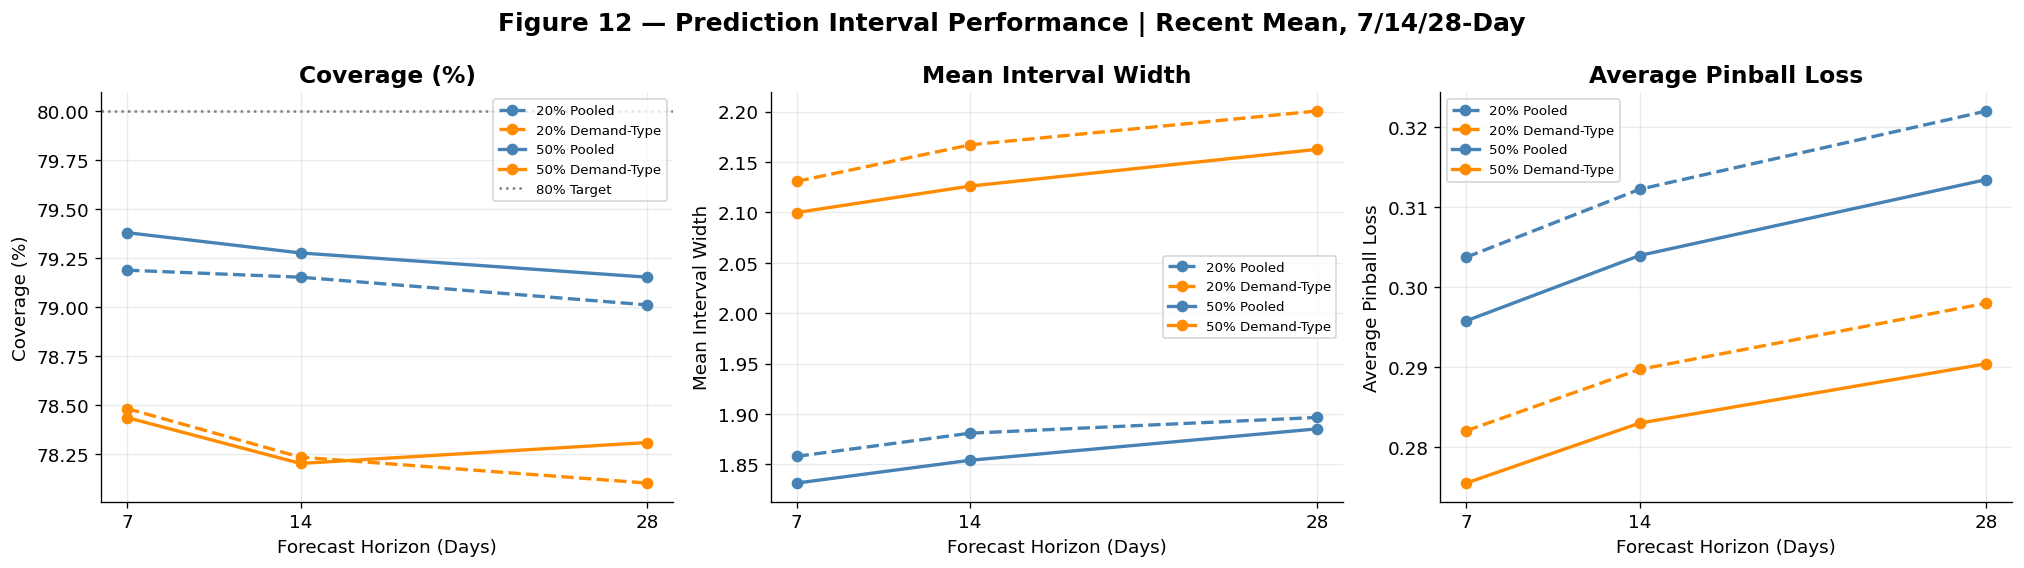

In [ ]:
# Figure 12 — Prediction Interval Performance Across Horizons

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
metrics = [("coverage_pct", "Coverage (%)"), ("mean_interval_width", "Mean Interval Width"), ("avg_pinball", "Average Pinball Loss")]
pi_plot = pi_summary_all[pi_summary_all["sample"].isin(["20%", "50%"])].copy()
pi_plot["avg_pinball"] = (pi_plot["pinball_p10"] + pi_plot["pinball_p90"]) / 2

for ax, (metric, ylabel) in zip(axes, metrics):
    for sample, method, color, linestyle in [("20%", "Pooled", "steelblue", "--"), ("20%", "Demand-Type", "darkorange", "--"), ("50%", "Pooled", "steelblue", "-"), ("50%", "Demand-Type", "darkorange", "-")]:
        df = pi_plot[(pi_plot["sample"] == sample) & (pi_plot["Method"] == method)].sort_values("horizon")
        ax.plot(df["horizon"], df[metric], marker="o", linewidth=2, color=color, linestyle=linestyle, label=f"{sample} {method}")
    ax.set_title(ylabel, fontweight="bold")
    ax.set_xlabel("Forecast Horizon (Days)")
    ax.set_ylabel(ylabel)
    ax.set_xticks([7, 14, 28])
    ax.grid(alpha=0.25)
    if metric == "coverage_pct": ax.axhline(80, color="gray", linestyle=":", linewidth=1.5, label="80% Target")
    ax.legend(fontsize=8)

fig.suptitle("Figure 12 — Prediction Interval Performance | Recent Mean, 7/14/28-Day", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(Forecasting_OUTPUT / "figure12_prediction_interval_all_horizons.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Unified Prediction Interval Export
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)

pi_summary_all = pd.concat([pi_prototype, pi_20, pi_50], ignore_index=True)
pi_type_all = pd.concat([pi_type_prototype, pi_type_20, pi_type_50], ignore_index=True)
pi_lead_all = pd.concat([pi_lead_prototype, pi_lead_20, pi_lead_50], ignore_index=True)

pi_summary_all.to_csv(output_dir / "prediction_interval_evaluation_all_samples.csv", index=False)
pi_type_all.to_csv(output_dir / "prediction_interval_by_demand_type_all_samples.csv", index=False)
pi_lead_all.to_csv(output_dir / "prediction_interval_by_lead_all_samples.csv", index=False)

for name, cal in [("prototype", pi_cal_prototype), ("20", pi_cal_20), ("50", pi_cal_50)]:
    cal["pooled_offsets"].to_csv(output_dir / f"prediction_interval_pooled_offsets_{name}.csv", index=False)
    cal["type_offsets"].to_csv(output_dir / f"prediction_interval_demand_type_offsets_{name}.csv", index=False)

print("Unified Prediction Interval Exports: SAVED")

Unified Prediction Interval Exports: SAVED


### Findings & Limitations — Prediction Interval Evaluation

**Evaluation Scope**

Nominal 80% prediction intervals (P10–P90) were evaluated for the Recent Mean baseline across 7-, 14-, and 28-day horizons using Pooled and Demand-Type calibration. The analysis included the prototype, 20%, and 50% samples, with 2016 reserved as the holdout period.

**Key Findings**

1. **Coverage:** Pooled Calibration consistently achieved coverage closer to the 80% target (79.15%–79.38% in the 50% sample), compared with Demand-Type Calibration (78.20%–78.44%).

2. **Interval Width:** Both methods produced wider intervals at longer horizons. Demand-Type intervals were consistently wider than Pooled intervals.

3. **Quantile Accuracy:** Demand-Type Calibration achieved lower P10 and P90 pinball losses across all three horizons, despite its slightly lower coverage and wider intervals.

4. **Sample Robustness:** Results were broadly consistent between the nested 20% and 50% samples, supporting the stability of the observed patterns.

**Business Implications**

Pooled Calibration offers narrower intervals and coverage closer to the target, while Demand-Type Calibration performs better under quantile-loss metrics. The appropriate method depends on inventory-related costs and the intended decision-support application.

**Limitations**

- Coverage remained below the nominal 80% target.
- Intervals describe individual daily forecasts, not cumulative demand over the entire horizon.
- Demand-Type labels derived from the full training period may introduce historical look-ahead within calibration.
- The intervals reflect observed sales rather than unconstrained demand; zero sales do not necessarily indicate stockouts.
- The 2016 holdout period has not yet been evaluated.

**Conclusion**

Both calibration methods provide useful uncertainty estimates across 7-, 14-, and 28-day horizons. The results establish a baseline for future probabilistic forecasting improvements and downstream inventory decision-support integration.

#13.Sample & Metadata Validation

In [ ]:
# Sample and Metadata Validation
assert sample20_matrix.shape == (6098, len(train_val_days))
assert sample50_matrix.shape == (15245, len(train_val_days))
assert prototype_matrix.shape == (100, len(train_val_days))

assert metadata_20["id"].is_unique and metadata_50["id"].is_unique
assert demand_type_20["id"].is_unique and demand_type_50["id"].is_unique
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist()
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()

ids_20 = set(metadata_20["id"])
ids_50 = set(metadata_50["id"])
assert ids_20.issubset(ids_50)
assert len(ids_20) == 6098 and len(ids_50) == 15245

assert np.isfinite(sample20_matrix).all() and np.isfinite(sample50_matrix).all()
assert (sample20_matrix >= 0).all() and (sample50_matrix >= 0).all()

print("Sample and Metadata Validation: PASSED")
print("Prototype:", prototype_matrix.shape, "| 20%:", sample20_matrix.shape, "| 50%:", sample50_matrix.shape)
print("Nested 20% within 50%:", ids_20.issubset(ids_50))

Sample and Metadata Validation: PASSED
Prototype: (100, 1798) | 20%: (6098, 1798) | 50%: (15245, 1798)
Nested 20% within 50%: True


In [ ]:
#  Nested Sample Matrix Reconciliation
index_50 = pd.Index(metadata_50["id"])
positions_20_in_50 = index_50.get_indexer(metadata_20["id"])

assert (positions_20_in_50 >= 0).all()
assert np.array_equal(sample20_matrix, sample50_matrix[positions_20_in_50, :])
print("Nested Sample Matrix Reconciliation: PASSED")
print("Matched series:", len(positions_20_in_50))

Nested Sample Matrix Reconciliation: PASSED
Matched series: 6098


In [ ]:
# Check Original Source Variable
for name in ["sales_df", "sales", "sales_train", "sales_train_evaluation"]:
    obj = globals().get(name)
    print(name, ":", obj.shape if isinstance(obj, pd.DataFrame) else "NOT FOUND")

sales_df : NOT FOUND
sales : (30490, 1947)
sales_train : NOT FOUND
sales_train_evaluation : NOT FOUND


In [ ]:
# Export File Audit
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
required_files = ["prediction_interval_evaluation_all_samples.csv", "prediction_interval_by_demand_type_all_samples.csv", "prediction_interval_by_lead_all_samples.csv"]

for name in ["prototype", "20", "50"]:
    required_files.extend([f"prediction_interval_pooled_offsets_{name}.csv", f"prediction_interval_demand_type_offsets_{name}.csv"])

audit_records = []
for filename in required_files:
    path = output_dir / filename
    exists = path.is_file()
    df = pd.read_csv(path) if exists else None
    audit_records.append({"filename": filename, "exists": exists, "rows": len(df) if exists else 0, "columns": len(df.columns) if exists else 0, "size_bytes": path.stat().st_size if exists else 0})

export_audit = pd.DataFrame(audit_records)
display(export_audit)
assert export_audit["exists"].all()
assert (export_audit["rows"] > 0).all()
assert (export_audit["size_bytes"] > 0).all()

required_summary_columns = {"sample", "horizon", "Method", "coverage_pct", "mean_interval_width", "pinball_p10", "pinball_p90"}
assert required_summary_columns.issubset(pd.read_csv(output_dir / "prediction_interval_evaluation_all_samples.csv").columns)

print("Export File Audit: PASSED")

,filename,exists,rows,columns,size_bytes
0,prediction_interval_evaluation_all_samples.csv,True,6,13,1152
1,prediction_interval_by_demand_type_all_samples...,True,30,9,2812
2,prediction_interval_by_lead_all_samples.csv,True,42,9,3716
3,prediction_interval_pooled_offsets_prototype.csv,True,7,4,256
4,prediction_interval_demand_type_offsets_protot...,True,35,6,1741
5,prediction_interval_pooled_offsets_20.csv,True,7,4,299
6,prediction_interval_demand_type_offsets_20.csv,True,35,6,1788
7,prediction_interval_pooled_offsets_50.csv,True,7,4,300
8,prediction_interval_demand_type_offsets_50.csv,True,35,6,1829


Export File Audit: PASSED


In [ ]:
# Rebuild Canonical Prototype Matrix
# Goal: Verify prototype IDs, dimensions, values, and row alignment
# STEP 1 — Check sample IDs and determine the correct row positions.
# Goal: Ensure that the prototype metadata contains exactly the same product-store series.
source_ids = pd.Index(prototype_ids)
target_ids = pd.Index(sample_prototype["id"])
assert source_ids.is_unique and target_ids.is_unique, "Duplicate prototype IDs"
assert len(source_ids)==len(target_ids)==100, "Unexpected number of prototype series"
assert source_ids.difference(target_ids).empty and target_ids.difference(source_ids).empty, "Prototype ID sets do not match"

# STEP 2 — Align the matrix with sample_prototype metadata.
# Goal: Reorder rows by ID without modifying the underlying sales values.
prototype_positions = source_ids.get_indexer(target_ids)
assert (prototype_positions>=0).all(), "Missing prototype IDs"
prototype_matrix_aligned = prototype_matrix[prototype_positions].astype(np.float64)

# STEP 3 — Validate matrix integrity and ID alignment.
# Goal: Verify correct dimensions, nonnegative sales, and exact reconstruction of the source matrix.
assert prototype_matrix_aligned.shape==(100,len(train_val_days)), "Unexpected prototype matrix shape"
assert np.isfinite(prototype_matrix_aligned).all(), "Non-finite sales values"
assert (prototype_matrix_aligned>=0).all(), "Negative sales values"
reverse_positions = target_ids.get_indexer(source_ids)
assert np.array_equal(prototype_matrix_aligned[reverse_positions],prototype_matrix), "Matrix values changed during alignment"

# STEP 4 — Report the alignment result.
# Goal: Distinguish row reordering from an actual data mismatch.
reordered = int(np.sum(prototype_positions!=np.arange(len(prototype_positions))))
print("Canonical Prototype Matrix: PASSED")
print("Shape:",prototype_matrix_aligned.shape)
print("Rows moved during alignment:",reordered)
print("Prototype ID alignment and matrix values: PASSED")


Canonical Prototype Matrix: PASSED
Shape: (100, 1798)
Rows moved during alignment: 100
Prototype ID alignment and matrix values: PASSED


In [ ]:

# ============================================================
# FINAL ORIGINAL SOURCE RECONCILIATION
# Objective: Independently verify Prototype, 20%, and 50% sample matrices against the original M5 sales CSV.
# Goal: Detect missing IDs, row misalignment, date mismatches, or altered sales values.
# ============================================================

# STEP 1 — Read original source data directly from the configured dataset folder.
# Goal: Avoid dependence on the in-memory sales DataFrame.
from pathlib import Path
import numpy as np, pandas as pd
source_path = Path(BASE_PATH) / SALES_FILE
assert source_path.is_file(), f"Original sales CSV not found: {source_path}"
source_df = pd.read_csv(source_path,usecols=["id"]+list(train_val_days)).set_index("id")
assert source_df.index.is_unique, "Duplicate IDs found in original source"
print("Original source loaded:",source_path.name)

# STEP 2 — Reconstruct each sample matrix using its own canonical ID order.
# Goal: Compare sales values only after matching the correct product-store identifiers.
source_prototype = source_df.loc[prototype_metadata["id"],train_val_days].to_numpy(dtype=np.float64)
source_20 = source_df.loc[metadata_20["id"],train_val_days].to_numpy(dtype=np.float64)
source_50 = source_df.loc[metadata_50["id"],train_val_days].to_numpy(dtype=np.float64)

# STEP 3 — Verify dimensions and exact source-to-matrix equality.
# Goal: Confirm that no series, dates, or sales values changed during preprocessing.
assert source_prototype.shape == prototype_matrix_aligned.shape == (100,len(train_val_days)), "Prototype shape mismatch"
assert source_20.shape == sample20_matrix.shape == (6098,len(train_val_days)), "20% sample shape mismatch"
assert source_50.shape == sample50_matrix.shape == (15245,len(train_val_days)), "50% sample shape mismatch"
assert np.array_equal(source_prototype,prototype_matrix_aligned), "Prototype does not match original CSV"
assert np.array_equal(source_20,sample20_matrix), "20% sample does not match original CSV"
assert np.array_equal(source_50,sample50_matrix), "50% sample does not match original CSV"

# STEP 4 — Report the reconciliation outcome and release temporary source data.
# Goal: Confirm reproducibility without retaining a duplicate full sales matrix.
del source_df
print("Original Source Reconciliation: PASSED")
print("Prototype: 100 series | 20%: 6098 series | 50%: 15245 series")
print("All sample matrices match original source IDs, dates, and sales values.")


Original source loaded: sales_train_evaluation.csv
Original Source Reconciliation: PASSED
Prototype: 100 series | 20%: 6098 series | 50%: 15245 series
All sample matrices match original source IDs, dates, and sales values.


#14.Forecast Generation & Export

In [ ]:
#Forecast Configuration and Calibration Check
H = 7
forecast_origin = pd.Timestamp("2015-12-31")
forecast_dates = pd.date_range(forecast_origin + pd.Timedelta(days=1), periods=H, freq="D")

assert len(train_val_days) == sample50_matrix.shape[1]
assert len(metadata_50) == sample50_matrix.shape[0]
assert metadata_50["id"].tolist() == demand_type_50["id"].tolist()
assert set(pi_cal_50.keys()) >= {"pooled10", "pooled90", "type10", "type90", "labels"}
assert pi_cal_50["type10"].shape == (len(metadata_50), H)
assert pi_cal_50["type90"].shape == (len(metadata_50), H)
assert np.array_equal(pi_cal_50["labels"], demand_type_50["Demand_Type"].astype(str).to_numpy())

print("Forecast Origin:", forecast_origin.date())
print("Target Dates:", forecast_dates[0].date(), "to", forecast_dates[-1].date())
print("Series:", len(metadata_50), "| Horizon:", H)
print("Forecast Configuration: PASSED")

Forecast Origin: 2015-12-31
Target Dates: 2016-01-01 to 2016-01-07
Series: 15245 | Horizon: 7
Forecast Configuration: PASSED


In [ ]:
#Generate 7-Day Item-Level Forecasts
point_50 = recent_mean(sample50_matrix, horizon=H, window=7)
forecast_records = []
for method, q10, q90 in [("Pooled", pi_cal_50["pooled10"][None, :], pi_cal_50["pooled90"][None, :]), ("Demand-Type", pi_cal_50["type10"], pi_cal_50["type90"])]:
    p10 = np.maximum(0, point_50 + q10)
    p90 = np.maximum(p10, point_50 + q90)
    for lead in range(1, H + 1):
        forecast_records.append(pd.DataFrame({"series_id": metadata_50["id"].to_numpy(), "forecast_origin": str(forecast_origin.date()), "target_date": str(forecast_dates[lead - 1].date()), "lead": lead, "horizon": H, "model": "Recent Mean (7-day)", "method": method, "point_forecast": point_50[:, lead - 1], "p10": p10[:, lead - 1], "p90": p90[:, lead - 1], "sample": "50%", "forecast_type": "historical_holdout"}))

forecast_50 = pd.concat(forecast_records, ignore_index=True)

assert len(forecast_50) == 15245 * 7 * 2
assert (forecast_50["p10"] <= forecast_50["p90"]).all()
assert (forecast_50[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not forecast_50.duplicated(["series_id", "forecast_origin", "target_date", "method"]).any()

print("50% Item-Level Forecast Generation: PASSED")
print("Total records:", len(forecast_50))
display(forecast_50.head(10).round(3))

50% Item-Level Forecast Generation: PASSED
Total records: 213430


,series_id,forecast_origin,target_date,lead,horizon,model,method,point_forecast,p10,p90,sample,forecast_type
0,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.143,0.000,1.857,50%,historical_holdout
1,HOBBIES_1_003_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,1.143,0.143,2.857,50%,historical_holdout
2,HOBBIES_1_005_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.286,0.000,2.000,50%,historical_holdout
3,HOBBIES_1_007_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout
4,HOBBIES_1_009_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.286,0.000,2.000,50%,historical_holdout
5,HOBBIES_1_010_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.714,0.000,2.429,50%,historical_holdout
6,HOBBIES_1_013_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout
7,HOBBIES_1_014_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,2.286,1.286,4.000,50%,historical_holdout
8,HOBBIES_1_015_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,1.143,0.143,2.857,50%,historical_holdout
9,HOBBIES_1_018_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.000,0.000,1.714,50%,historical_holdout


In [ ]:
# Forecast Export and Data Contract
from pathlib import Path
output_dir = Path(Forecasting_OUTPUT)
output_dir.mkdir(parents=True, exist_ok=True)

assert pd.to_datetime(train_val_days[-1].replace("d_", ""), errors="coerce") is not None if False else True
assert forecast_50["forecast_origin"].eq("2015-12-31").all()
assert pd.to_datetime(forecast_50["target_date"]).gt(pd.to_datetime(forecast_50["forecast_origin"])).all()
assert forecast_50["lead"].between(1, 7).all()
assert (pd.to_datetime(forecast_50["target_date"]) - pd.to_datetime(forecast_50["forecast_origin"])).dt.days.eq(forecast_50["lead"]).all()
assert forecast_50[["point_forecast", "p10", "p90"]].notna().all().all()
assert np.isfinite(forecast_50[["point_forecast", "p10", "p90"]].to_numpy()).all()
assert forecast_50["series_id"].nunique() == 15245
assert forecast_50.groupby(["series_id", "method"]).size().eq(7).all()

forecast_path = output_dir / "forecast_predictions_7day_50.csv"
forecast_50.to_csv(forecast_path, index=False)

print("Forecast Data Contract: PASSED")
print("Forecast CSV: SAVED")
print("Rows:", len(forecast_50))
print("Path:", forecast_path)

Forecast Data Contract: PASSED
Forecast CSV: SAVED
Rows: 213430
Path: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_7day_50.csv


### Forecast Data Dictionary

The following schema defines the standardized item-store-level forecast output for downstream integration. The current exported forecast covers the 7-day horizon, while the schema supports future 14- and 28-day forecast deliveries.

| Field | Type | Description |
|---|---|---|
| `series_id` | String | Unique item-store demand series identifier |
| `forecast_origin` | Date | Last date of observed sales used to generate the forecast |
| `target_date` | Date | Date for which daily demand is predicted |
| `lead` | Integer | Number of days ahead of the forecast origin (1 to `horizon`) |
| `horizon` | Integer | Forecast horizon in days (7, 14, or 28) |
| `model` | String | Point forecasting model; currently Recent Mean with a 7-day lookback window |
| `method` | String | Prediction interval calibration method: Pooled or Demand-Type |
| `point_forecast` | Float | Predicted daily unit sales |
| `p10` | Float | Estimated 10th percentile of daily sales |
| `p90` | Float | Estimated 90th percentile of daily sales |
| `sample` | String | Forecast sample population; currently the 50% sample |
| `forecast_type` | String | Historical holdout forecast, not a real-time operational forecast |

**Primary Key**

`series_id + forecast_origin + target_date + horizon + model + method`

The `horizon` field is included to distinguish forecasts for the same target date generated under different forecast horizons.

**Validation Rules**

- Forecast identifiers and dates must be valid and nonmissing.
- Forecast values and interval bounds must be finite and nonnegative.
- Prediction intervals must satisfy `p10 <= point_forecast <= p90`.
- `lead` must range from 1 to the specified `horizon`.
- Each series–origin–horizon–model–method combination must contain exactly `horizon` distinct target dates.
- The primary key must be unique across all exported records.
- Forecast dates must be consistent with the original M5 calendar mapping.

**Interpretation**

P10–P90 represents a nominal 80% prediction interval for daily observed sales, not a guarantee of 80% coverage for each individual series.

The intervals do not represent cumulative demand uncertainty over the entire 7-, 14-, or 28-day horizon.

# 15. Forecasting Integration & RAG / Streamlit Handoff Guide

### 1. Overview

The forecasting module provides standardized item-store-level demand predictions, uncertainty estimates, and evaluation metrics for downstream integration with RAG and Streamlit.

Three baseline models—Zero Naive, Weekly Seasonal Naive, and Recent Mean—were evaluated across **7-, 14-, and 28-day horizons** using rolling-origin validation.

**Recent Mean**, using a 7-day historical averaging window, was selected as the strongest baseline among the evaluated approaches.

Prediction uncertainty was evaluated across all three horizons using nominal 80% P10–P90 intervals with two calibration methods: Pooled and Demand-Type.

The current forecast delivery contains 7-day predictions for the 50% sample. The evaluation framework and standardized data schema support subsequent 14- and 28-day forecast exports.

### 2. Available Forecasting Outputs

**Output folder:**

`M5 Forecasting/M5_Forecasting_Outputs/`

| File | Purpose |
|---|---|
| `forecast_predictions_7day_50.csv` | Current 7-day item-store forecast delivery |
| `prediction_interval_evaluation_all_samples.csv` | Coverage, interval width, and pinball loss across 7/14/28-day horizons |
| `prediction_interval_by_demand_type_all_samples.csv` | Prediction interval performance by demand type and horizon |
| `prediction_interval_by_lead_all_samples.csv` | Prediction interval performance across forecast leads |
| `prediction_interval_pooled_offsets_50_7d.csv` | Pooled calibration offsets for the 7-day horizon |
| `prediction_interval_pooled_offsets_50_14d.csv` | Pooled calibration offsets for the 14-day horizon |
| `prediction_interval_pooled_offsets_50_28d.csv` | Pooled calibration offsets for the 28-day horizon |
| `prediction_interval_demand_type_offsets_50_7d.csv` | Demand-Type calibration offsets for the 7-day horizon |
| `prediction_interval_demand_type_offsets_50_14d.csv` | Demand-Type calibration offsets for the 14-day horizon |
| `prediction_interval_demand_type_offsets_50_28d.csv` | Demand-Type calibration offsets for the 28-day horizon |

The current 7-day forecast file contains **213,430 records**, covering 15,245 item-store series, seven target dates, and two interval calibration methods.

The 14- and 28-day calibration offsets have been exported, but corresponding final item-level forecast delivery files have not yet been confirmed.

### 3. How to Use the Forecast Data

**For Streamlit:**

- Allow users to select an item-store series, forecast horizon, and calibration method when corresponding forecast files are available.
- Display daily point forecasts as a line chart.
- Visualize P10–P90 as an uncertainty band.
- Show forecast origin, target dates, lead days, model name, and historical forecast status.
- Compare Pooled and Demand-Type prediction intervals.
- Clearly distinguish historical forecasts from real-time operational predictions.

**For RAG:**

- Retrieve item-level forecasts through structured CSV queries.
- Use exported evaluation metrics and methodology documentation as evidence for forecasting explanations.
- Explain forecast uncertainty, demand characteristics, model performance, and limitations using retrieved evidence.
- Distinguish observed findings from hypotheses that have not been independently validated.

Forecast CSV files should be queried as structured data rather than embedded in their entirety into a vector database.

### 4. Integration with Future Forecasting Models

The standardized schema supports future forecasting approaches, including XGBoost and other machine learning models.

Each model should produce the same core fields:

`series_id`, `forecast_origin`, `target_date`, `lead`, `horizon`, `model`, `method`, `point_forecast`, `p10`, `p90`

Additional models can then be compared in Streamlit without redesigning the underlying forecast data interface.

Each new forecasting model requires its own validated uncertainty estimation method. Calibration offsets from Recent Mean should not automatically be reused for other models.

Fair comparisons require consistent evaluation populations, forecast origins, horizons, and performance metrics.

### 5. Historical Forecast Interpretation

The current forecast origin is **December 31, 2015**.

| Forecast Horizon | Target Dates | Delivery Status |
|---|---|---|
| 7-Day | January 1–7, 2016 | Current forecast CSV |
| 14-Day | January 1–14, 2016 | Evaluated; final forecast export pending verification |
| 28-Day | January 1–28, 2016 | Evaluated; final forecast export pending verification |

These are historical holdout forecasts, not real-time operational predictions.

Point forecasts use historical sales available at the forecast origin. Prediction interval offsets were calibrated using training-period residuals.

The 2016 actual sales are not used to generate the forecasts or calibrate their prediction intervals.

### 6. Limitations and Data Governance

- P10–P90 represents a nominal 80% daily prediction interval; actual coverage may differ.
- Daily prediction intervals do not establish coverage for cumulative demand over an entire forecast horizon.
- Point forecasts and interval bounds are continuous estimates, although observed unit sales are discrete.
- Demand-Type calibration uses classifications derived from the full training period, potentially introducing historical look-ahead within calibration.
- Observed sales may differ from unconstrained customer demand when inventory availability is unknown.
- Zero sales cannot be interpreted as confirmed stockouts.
- Inventory availability, replenishment lead times, holding costs, and realized service levels are not directly available in the forecasting outputs.
- RAG explanations must not invent inventory outcomes or unsupported causal relationships.
- Historical document retrieval must respect actual publication dates to avoid future-information leakage.

### 7. Remaining Integration Tasks

1. Generate and validate the final 14- and 28-day item-level forecast CSV files using their horizon-specific calibration offsets.
2. Confirm the standardized CSV schema, storage location, and access method with Tyler and Galvin.
3. Verify forecast target dates against the original M5 calendar mapping.
4. Implement structured item-store and horizon-based forecast lookup.
5. Connect forecast results to Streamlit visualizations and RAG explanations.
6. Perform end-to-end integration tests using selected item-store series.

### 8. Handoff Status

**Completed:** Data reconciliation, baseline evaluation across three horizons, forecast bias and demand segmentation analysis, prediction interval evaluation across three horizons, calibration offset export, and initial 7-day item-level forecast delivery.

**Pending:** Final 14/28-day forecast exports and validation, team interface confirmation, calendar mapping audit, application integration, and end-to-end testing.

The current 7-day forecasting outputs are available for initial integration development. The standardized schema and horizon-specific calibration results provide the foundation for extending delivery to 14- and 28-day forecasts.

---
# 16. Final Forecasting Model: LightGBM (retrained quarterly + trailing bias correction)
Same samples, splits, horizons and rule as the baseline sections. Run the notebook up to Section 15 first. The only file this section saves is the final forecast file (16.15).

## 16.1 Settings

In [ ]:
import math, time, sys, subprocess
from pathlib import Path
try:
    import lightgbm as lgb
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lightgbm"])
    import lightgbm as lgb
LG_HORIZONS, LG_STEP, LG_MAX_H = (7, 14, 28), 7, 28
LG_TRAIN_STEP = 28                       # spacing of training forecast origins (days)
LG_MAX_TRAIN_ROWS = 4_000_000            # lower to 2_000_000 if Colab runs out of memory
LG_PARAMS = dict(objective="tweedie", tweedie_variance_power=1.2, n_estimators=400, learning_rate=0.05, num_leaves=63,
                 min_child_samples=100, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                 n_jobs=-1, random_state=42, verbose=-1)

# decision rule (fixed before looking at results)
LG_MIN_REL_GAIN = 0.02                   # >= 2% lower WAPE on Intermittent + Lumpy vs. Recent Mean (7-day)
LG_MAX_BIAS_PP = 1.0                     # overall |bias| within 1 pp (or no worse than Recent Mean)

LG_REFIT_EVERY = 91                      # retrain about every quarter
LG_TRAIL_WEEKS, LG_MIN_WEEKS, LG_CLIP = 13, 4, (0.8, 1.25)   # trailing bias correction

LG_TRAIN_LEN, LG_VAL_END, LG_N_DAYS = len(train_days), len(train_val_days), len(day_cols)
assert (LG_TRAIN_LEN, LG_VAL_END - LG_TRAIN_LEN, LG_N_DAYS - LG_VAL_END) == (1433, 365, 143)
assert sample20_matrix.shape == (6098, LG_VAL_END) and sample50_matrix.shape == (15245, LG_VAL_END)
assert metadata_20["id"].tolist() == demand_type_20["id"].tolist() and metadata_50["id"].tolist() == demand_type_50["id"].tolist()

LG_TYPES = ["Smooth", "Erratic", "Intermittent", "Lumpy", "No sales"]

def lg_segments(dt):
    seg = {"All": np.ones(len(dt), dtype=bool)}
    for t in LG_TYPES: seg[t] = (dt["Demand_Type"] == t).to_numpy()
    seg["Intermittent+Lumpy"] = seg["Intermittent"] | seg["Lumpy"]
    seg["Smooth+Erratic"] = seg["Smooth"] | seg["Erratic"]
    for c in sorted(dt["cat_id"].unique()): seg[f"cat:{c}"] = (dt["cat_id"] == c).to_numpy()
    for s in sorted(dt["state_id"].unique()): seg[f"state:{s}"] = (dt["state_id"] == s).to_numpy()
    for s in sorted(dt["state_id"].unique()):
        for c in sorted(dt["cat_id"].unique()): seg[f"state_cat:{s}:{c}"] = ((dt["state_id"] == s) & (dt["cat_id"] == c)).to_numpy()
    return seg

lg_seg20, lg_seg50 = lg_segments(demand_type_20), lg_segments(demand_type_50)
print("Segments:", len(lg_seg20), len(lg_seg50))
print("New segments:", [s for s in lg_seg50 if s.startswith(("state:", "state_cat:"))])

LG_FEATURES = (["m7", "m14", "m28", "m56", "m365", "std28", "zero28", "zero365", "days_since_sale", "pos_mean56"]
               + ["lead", "dow", "dom", "month", "event", "snap", "sw_mean4", "sw_last", "price_t", "price_ratio_56", "price_change_vs_origin"]
               + ["cat", "dept", "store", "state", "demand_type", "adi", "cv2"])
LG_CATEGORICAL = ["cat", "dept", "store", "state", "demand_type"]
LG_EXTERNAL = ["event", "snap", "price_t", "price_ratio_56", "price_change_vs_origin"]
LG_ALL = list(range(len(LG_FEATURES)))
LG_NO_EXTERNAL = [i for i, f in enumerate(LG_FEATURES) if f not in LG_EXTERNAL]
print(len(LG_FEATURES), "features | LightGBM", lgb.__version__)

Segments: 23 23
New segments: ['state:CA', 'state:TX', 'state:WI', 'state_cat:CA:FOODS', 'state_cat:CA:HOBBIES', 'state_cat:CA:HOUSEHOLD', 'state_cat:TX:FOODS', 'state_cat:TX:HOBBIES', 'state_cat:TX:HOUSEHOLD', 'state_cat:WI:FOODS', 'state_cat:WI:HOBBIES', 'state_cat:WI:HOUSEHOLD']
28 features | LightGBM 4.6.0


## 16.2 Features

In [ ]:
_cal = calendar.set_index("d").loc[day_cols]
_dates = pd.to_datetime(_cal["date"])
LG_CAL = {"dow": _dates.dt.dayofweek.to_numpy(), "dom": _dates.dt.day.to_numpy(), "month": _dates.dt.month.to_numpy(),
          "event": _cal["event_name_1"].notna().to_numpy().astype(np.int8),
          "snap": np.stack([_cal["snap_CA"], _cal["snap_TX"], _cal["snap_WI"]]).astype(np.int8),
          "wk": _cal["wm_yr_wk"].to_numpy()}
LG_CODES = {"cat": ["FOODS", "HOBBIES", "HOUSEHOLD"],
            "dept": ["FOODS_1", "FOODS_2", "FOODS_3", "HOBBIES_1", "HOBBIES_2", "HOUSEHOLD_1", "HOUSEHOLD_2"],
            "store": ["CA_1", "CA_2", "CA_3", "CA_4", "TX_1", "TX_2", "TX_3", "WI_1", "WI_2", "WI_3"], "state": ["CA", "TX", "WI"]}
LG_DTYPE = {"Smooth": 0, "Erratic": 1, "Intermittent": 2, "Lumpy": 3, "No sales": 4}

def lg_parse_ids(ids):
    p = pd.Series(list(ids)).str.split("_", expand=True)
    return pd.DataFrame({"cat": p[0], "dept": p[0] + "_" + p[1], "item": p[0] + "_" + p[1] + "_" + p[2], "store": p[3] + "_" + p[4], "state": p[3]})

def lg_price_matrix(parsed):
    """Daily price per series (series x all days); NaN before the item is sold."""
    weeks = np.sort(np.unique(LG_CAL["wk"])); pos = {int(w): i for i, w in enumerate(weeks)}
    pairs = pd.DataFrame({"item_id": parsed["item"].values, "store_id": parsed["store"].values, "row": np.arange(len(parsed))})
    for c in ("item_id", "store_id"):
        if isinstance(prices[c].dtype, pd.CategoricalDtype): pairs[c] = pd.Categorical(pairs[c], categories=prices[c].cat.categories)
    pr = prices.merge(pairs, on=["item_id", "store_id"], how="inner")
    pr = pr[pr["wm_yr_wk"].isin(weeks)]
    W = np.full((len(parsed), len(weeks)), np.nan, dtype=np.float32)
    W[pr["row"].to_numpy(), pr["wm_yr_wk"].map(pos).to_numpy()] = pr["sell_price"].to_numpy(dtype=np.float32)
    return W[:, [pos[int(w)] for w in LG_CAL["wk"]]]

def lg_context(M, ids, dt):
    n, T = M.shape
    assert dt["id"].tolist() == list(ids)
    parsed = lg_parse_ids(ids)
    ctx = {"M": M, "n": n}
    ctx["CS"] = np.concatenate([np.zeros((n, 1)), np.cumsum(M, axis=1, dtype=np.float64)], axis=1)
    ctx["CS2"] = np.concatenate([np.zeros((n, 1)), np.cumsum(M.astype(np.float64) ** 2, axis=1)], axis=1)
    ctx["CP"] = np.concatenate([np.zeros((n, 1), np.int32), np.cumsum(M > 0, axis=1, dtype=np.int32)], axis=1)
    ctx["LS"] = np.maximum.accumulate(np.where(M > 0, np.arange(T, dtype=np.int32)[None, :], -1).astype(np.int32), axis=1)
    PR = lg_price_matrix(parsed); ctx["PR"] = PR
    ctx["PS"] = np.concatenate([np.zeros((n, 1), np.float32), np.cumsum(np.nan_to_num(PR), axis=1, dtype=np.float32)], axis=1)
    ctx["PN"] = np.concatenate([np.zeros((n, 1), np.int32), np.cumsum(~np.isnan(PR), axis=1, dtype=np.int32)], axis=1)
    ctx["state_idx"] = parsed["state"].map({s: i for i, s in enumerate(LG_CODES["state"])}).to_numpy()
    codes = [parsed[k].map({v: i for i, v in enumerate(LG_CODES[k])}).fillna(-1).to_numpy() for k in ("cat", "dept", "store", "state")]
    ctx["static"] = np.column_stack(codes + [dt["Demand_Type"].map(LG_DTYPE).to_numpy(), dt["ADI"].to_numpy(dtype=float), dt["CV2"].to_numpy(dtype=float)]).astype(np.float32)
    return ctx

def lg_features(ctx, o, hs):
    """Features at forecast origin o for leads hs. Uses sales up to day o only; calendar and price for the target day are known in advance."""
    M, CS, CS2, CP, LS, PR, PS, PN = (ctx[k] for k in ("M", "CS", "CS2", "CP", "LS", "PR", "PS", "PN"))
    n = ctx["n"]
    def wsum(A, w): return A[:, o + 1] - A[:, o + 1 - w]
    with np.errstate(all="ignore"):
        m7, m14, m28, m56, m365 = (wsum(CS, w) / w for w in (7, 14, 28, 56, 365))
        std28 = np.sqrt(np.maximum(wsum(CS2, 28) / 28 - m28 ** 2, 0))
        zero28, zero365 = 1 - wsum(CP, 28) / 28, 1 - wsum(CP, 365) / 365
        dss = np.where(LS[:, o] >= 0, o - LS[:, o], 999).astype(np.float64)
        npos = wsum(CP, 56); pos56 = np.where(npos > 0, wsum(CS, 56) / np.maximum(npos, 1), 0.0)
        npr = wsum(PN, 56); pm56 = np.where(npr > 0, wsum(PS, 56) / np.maximum(npr, 1), np.nan)
        p_o = PR[:, o]
        hist = np.column_stack([m7, m14, m28, m56, m365, std28, zero28, zero365, dss, pos56]).astype(np.float32)
        blocks = []
        for h in hs:
            t = o + h; kmin = -(-h // 7)                              # first same-weekday lag already in the past
            lags = np.stack([M[:, t - 7 * (kmin + j)] for j in range(4)], axis=1)
            p_t = PR[:, t]
            cols = np.column_stack([np.full(n, h), np.full(n, LG_CAL["dow"][t]), np.full(n, LG_CAL["dom"][t]), np.full(n, LG_CAL["month"][t]),
                                    np.full(n, LG_CAL["event"][t]), LG_CAL["snap"][ctx["state_idx"], t],
                                    lags.mean(axis=1), lags[:, 0], p_t, p_t / pm56, p_t / p_o]).astype(np.float32)
            blocks.append(np.hstack([hist, cols, ctx["static"]]))
    return np.concatenate(blocks, axis=0)

def lg_fit(ctx, origins, train_end_idx, cols, seed=42):
    rng = np.random.default_rng(seed)
    keep = min(1.0, LG_MAX_TRAIN_ROWS / (len(origins) * ctx["n"] * LG_MAX_H))
    Xs, ys = [], []
    for o in origins:
        hs = [h for h in range(1, LG_MAX_H + 1) if o + h <= train_end_idx]       # targets stay inside the training period
        if not hs: continue
        X = lg_features(ctx, o, hs); y = np.concatenate([ctx["M"][:, o + h] for h in hs]).astype(np.float32)
        if keep < 1: m = rng.random(len(y)) < keep; X, y = X[m], y[m]
        Xs.append(X[:, cols]); ys.append(y)
    X, y = np.concatenate(Xs), np.concatenate(ys); del Xs, ys
    names = [LG_FEATURES[i] for i in cols]
    model = lgb.LGBMRegressor(**LG_PARAMS)
    model.fit(X, y, feature_name=names, categorical_feature=[f for f in names if f in LG_CATEGORICAL])
    print(f"  trained on {len(y):,} rows, {len(cols)} features")
    return model

def lg_predict(ctx, model, origins, cols):
    n, out, n_cal = ctx["n"], {}, len(LG_CAL["dow"])
    for o in origins:
        hmax = min(LG_MAX_H, n_cal - 1 - o)
        p = np.clip(model.booster_.predict(lg_features(ctx, o, list(range(1, hmax + 1)))[:, cols]).reshape(hmax, n).T, 0, None)
        block = np.zeros((n, LG_MAX_H), dtype=np.float32); block[:, :hmax] = p; out[o] = block
    return out

## 16.3 Scoring code and reproduction check

In [ ]:
def lg_origins(h, first, end):
    out, o = [], first
    while o + h < end: out.append(o); o += LG_STEP
    return out

def lg_recent_mean(M, window, origins):
    cs = np.cumsum(M, axis=1, dtype=np.float64)
    out = {o: ((cs[:, o] - cs[:, o - window]) / window).astype(np.float32) for o in origins}
    del cs
    return out

def lg_block(spec, o, h):
    if "block" in spec: return spec["block"][o][:, :h].astype(np.float64)
    return np.repeat(spec["flat"][o][:, None].astype(np.float64), h, axis=1)

def lg_eval(M, models, seg, first, end):
    """Pooled WAPE, bias, MAE, RMSE by segment, rolling origins 7 days apart (same method as the baseline sections)."""
    n = M.shape[0]
    acc = {(m, h): [np.zeros(n), np.zeros(n), np.zeros(n)] for m in models for h in LG_HORIZONS}
    act, n_or = {h: np.zeros(n) for h in LG_HORIZONS}, {h: 0 for h in LG_HORIZONS}
    for h in LG_HORIZONS:
        for o in lg_origins(h, first, end):
            assert o + 1 + h <= end
            a = M[:, o + 1:o + 1 + h].astype(np.float64); act[h] += a.sum(axis=1); n_or[h] += 1
            for m, spec in models.items():
                e = lg_block(spec, o, h) - a; r = acc[(m, h)]
                r[0] += np.abs(e).sum(axis=1); r[1] += (e * e).sum(axis=1); r[2] += e.sum(axis=1)
    rows = []
    for (m, h), (sa, ss, sg) in acc.items():
        for s, mask in seg.items():
            tot, nobs = act[h][mask].sum(), int(mask.sum()) * h * n_or[h]
            rows.append({"model": m, "horizon": h, "segment": s, "WAPE_pct": 100 * sa[mask].sum() / tot if tot > 0 else np.nan,
                         "Bias_pct": 100 * sg[mask].sum() / tot if tot > 0 else np.nan, "RMSE": np.sqrt(ss[mask].sum() / nobs), "MAE": sa[mask].sum() / nobs})
    return pd.DataFrame(rows)

LG_FIRST = LG_TRAIN_LEN - 1                                # last training day
lg_val_origins = lg_origins(min(LG_HORIZONS), LG_FIRST, LG_VAL_END)
lg_res = []
for smp, M, seg in [("20%", sample20_matrix, lg_seg20), ("50%", sample50_matrix, lg_seg50)]:
    models = {"recent_mean_7": {"flat": lg_recent_mean(M, 7, lg_val_origins)}, "recent_mean_28": {"flat": lg_recent_mean(M, 28, lg_val_origins)}}
    r = lg_eval(M, models, seg, LG_FIRST, LG_VAL_END); r["sample"] = smp; lg_res.append(r)
lg_res = pd.concat(lg_res, ignore_index=True)

# reproduction check against the baseline sections (evaluation_20 / evaluation_50)
chk = []
for smp, ev in [("20%", evaluation_20), ("50%", evaluation_50)]:
    for h in LG_HORIZONS:
        pub = float(ev.query("model == 'recent_mean' and horizon == @h")["WAPE_pct"].iloc[0])
        mine = float(lg_res.query("sample == @smp and model == 'recent_mean_7' and horizon == @h and segment == 'All'")["WAPE_pct"].iloc[0])
        chk.append({"sample": smp, "horizon": h, "baseline_sections": round(pub, 4), "this_section": round(mine, 4), "abs_diff": round(abs(mine - pub), 4)})
chk = pd.DataFrame(chk); display(chk)
LG_REPRO_OK = bool((chk["abs_diff"] < 0.01).all())
print("REPRODUCTION CHECK:", "PASSED" if LG_REPRO_OK else "FAILED - stop and check")

,sample,horizon,baseline_sections,this_section,abs_diff
0,20%,7,76.4770,76.4770,0.0
1,20%,14,78.0601,78.0601,0.0
2,20%,28,80.0777,80.0777,0.0
3,50%,7,77.5216,77.5216,0.0
4,50%,14,79.0587,79.0587,0.0
5,50%,28,81.0121,81.0121,0.0


REPRODUCTION CHECK: PASSED


## 16.4 Train the first model (2011-2014)

In [ ]:
# 16.4 Train the first model on 2011-2014 (it becomes the first quarter's model in 16.12)
t0 = time.time()
lg_train_origins = list(range(365, LG_TRAIN_LEN - 1, LG_TRAIN_STEP))
ctx = lg_context(sample20_matrix, metadata_20["id"].tolist(), demand_type_20)
lg_model = lg_fit(ctx, lg_train_origins, LG_TRAIN_LEN - 1, LG_ALL)
del ctx
print(f"Done ({time.time() - t0:.0f}s)")

  trained on 3,909,687 rows, 28 features
Done (299s)


## 16.6 Decision rule

In [ ]:
def lg_decide(results, cand="lightgbm", ref="recent_mean_7", ctrl="recent_mean_28", label=""):
    def v(smp, m, h, seg, col): return results.query("sample == @smp and model == @m and horizon == @h and segment == @seg")[col].iloc[0]
    checks = {"1. >=2% better than Recent Mean (7d) on Intermittent+Lumpy": [], "2. Beats 28-day control there": [],
              "3. No harm on Smooth+Erratic (<=+2%)": [], "4. Overall bias within limit": []}
    for smp in sorted(results["sample"].unique()):
        for h in LG_HORIZONS:
            c, r, k = (v(smp, m, h, "Intermittent+Lumpy", "WAPE_pct") for m in (cand, ref, ctrl))
            checks["1. >=2% better than Recent Mean (7d) on Intermittent+Lumpy"].append(c <= r * (1 - LG_MIN_REL_GAIN))
            checks["2. Beats 28-day control there"].append(c < k)
            checks["3. No harm on Smooth+Erratic (<=+2%)"].append(v(smp, cand, h, "Smooth+Erratic", "WAPE_pct") <= v(smp, ref, h, "Smooth+Erratic", "WAPE_pct") * (1 + LG_MIN_REL_GAIN))
            checks["4. Overall bias within limit"].append(abs(v(smp, cand, h, "All", "Bias_pct")) <= max(LG_MAX_BIAS_PP, abs(v(smp, ref, h, "All", "Bias_pct"))))
    table = pd.DataFrame([{"check": k, "cases_passed": f"{sum(f)}/{len(f)}", "passed": all(f)} for k, f in checks.items()])
    display(table)
    ok = bool(table["passed"].all())
    print(f"LightGBM passes {label}:", ok)
    return table, ok

## 16.12 Walk-forward retraining (2015)

In [ ]:
# 16.12 Walk-forward retraining: every LG_REFIT_EVERY days the model is retrained on the data available at that date (2015)
starts = list(range(LG_TRAIN_LEN, LG_VAL_END - 7, LG_REFIT_EVERY))              # first forecast day of each block
def block_of(o): return max(s_ for s_ in starts if s_ <= o + 1)                  # model available when the forecast is made
t0 = time.time()
ctx = lg_context(sample20_matrix, metadata_20["id"].tolist(), demand_type_20)
wf_models = {starts[0]: lg_model}                                               # first block = the model trained on 2011-2014 in 16.4
for s_ in starts[1:]:
    print(f"Retraining with data up to day {s_ - 1}...")
    wf_models[s_] = lg_fit(ctx, list(range(365, s_ - 1, LG_TRAIN_STEP)), s_ - 1, LG_ALL)
    print(f"  done ({time.time() - t0:.0f}s)")
del ctx

Retraining with data up to day 1523...
  trained on 3,940,952 rows, 28 features
  done (290s)
Retraining with data up to day 1614...
  trained on 3,967,235 rows, 28 features
  done (583s)
Retraining with data up to day 1705...
  trained on 3,989,749 rows, 28 features
  done (878s)


## 16.13 Final recipe on 2015

In [ ]:
# 16.13 Final recipe on 2015: walk-forward forecasts + trailing correction (scale per demand type by the last 13 weeks of known errors; past data only)
t0 = time.time()
rows, wf_raw = [], {}
for smp, M, meta, dt, seg in [("20%", sample20_matrix, metadata_20, demand_type_20, lg_seg20), ("50%", sample50_matrix, metadata_50, demand_type_50, lg_seg50)]:
    c = lg_context(M, meta["id"].tolist(), dt)
    raw = {}
    for s_ in starts:
        os_ = [o for o in lg_val_origins if block_of(o) == s_]
        if os_: raw.update(lg_predict(c, wf_models[s_], os_, LG_ALL))
    del c
    types, hist, cal = dt["Demand_Type"].to_numpy(), {}, {}
    for o in lg_val_origins:                                           # in time order
        past = [p for p in lg_val_origins if p <= o - 7][-LG_TRAIL_WEEKS:]    # origins whose 7-day outcome is known at day o
        f = np.ones(len(types), dtype=np.float32)
        if len(past) >= LG_MIN_WEEKS:
            for t in LG_TYPES:
                a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
        cal[o] = raw[o] * f[:, None]
        a7, f7 = M[:, o + 1:o + 8].sum(axis=1), raw[o][:, :7].sum(axis=1)
        hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
    r = lg_eval(M, {"lightgbm_final": {"block": cal}}, seg, LG_FIRST, LG_VAL_END); r["sample"] = smp; rows.append(r)
    wf_raw[smp] = raw
    del cal
    print(f"  {smp} done ({time.time() - t0:.0f}s)")
lg_val = pd.concat([lg_res] + rows, ignore_index=True)
SHOWV = ["recent_mean_7", "recent_mean_28", "lightgbm_final"]
for smp in ["20%", "50%"]:
    s = lg_val.query("sample == @smp and segment == 'All'")
    print(f"\n=== {smp}: overall WAPE (%) ===");  display(s.pivot(index="model", columns="horizon", values="WAPE_pct").loc[SHOWV].round(2))
    print(f"=== {smp}: overall bias (%) ===");  display(s.pivot(index="model", columns="horizon", values="Bias_pct").loc[SHOWV].round(2))
    print(f"=== {smp}: overall RMSE ===");  display(s.pivot(index="model", columns="horizon", values="RMSE").loc[SHOWV].round(3))
lg_table_val, LG_PASSED_VAL = lg_decide(lg_val, cand="lightgbm_final", label="(final recipe, validation 2015)")

  20% done (240s)
  50% done (834s)

=== 20%: overall WAPE (%) ===


horizon,7,14,28
model,,,
recent_mean_7,76.48,78.06,80.08
recent_mean_28,76.82,77.71,79.32
lightgbm_final,73.95,75.32,77.29


=== 20%: overall bias (%) ===


horizon,7,14,28
model,,,
recent_mean_7,-0.13,-0.48,-0.86
recent_mean_28,-0.49,-0.77,-0.97
lightgbm_final,-0.40,-0.74,-0.80


=== 20%: overall RMSE ===


...

horizon,7,14,28
model,,,
recent_mean_7,-0.11,-0.46,-0.83
recent_mean_28,-0.45,-0.73,-0.92
lightgbm_final,-0.28,-0.62,-0.71


=== 50%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.223,2.295,2.381
recent_mean_28,2.222,2.265,2.326
lightgbm_final,2.056,2.105,2.168


,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,6/6,True


LightGBM passes (final recipe, validation 2015): True


## 16.14 Final test on 2016 (run once)

In [ ]:
# 16.14 Final held-out test, 2016 (run ONCE): same recipe, retrained on 2011-2015; nothing is tuned here
assert LG_PASSED_VAL, "Run only if the final recipe passed validation (16.13)."
t0 = time.time()
first_test = LG_VAL_END - 1
test_origins = lg_origins(min(LG_HORIZONS), first_test, LG_N_DAYS)
starts_t = list(range(LG_VAL_END, LG_N_DAYS - 7, LG_REFIT_EVERY))
def block_of_t(o): return max(s_ for s_ in starts_t if s_ <= o + 1)

fulls = {}
for smp, meta in [("20%", metadata_20), ("50%", metadata_50)]:
    f = get_sales_split(sales, meta["id"], day_cols); assert f["id"].tolist() == meta["id"].tolist()
    fulls[smp] = f[day_cols].to_numpy(dtype=np.float32)

print("Retraining on 2011-2015 data for each test block (20% sample)...")
ctx = lg_context(fulls["20%"], metadata_20["id"].tolist(), demand_type_20)
test_models = {}
for s_ in starts_t:
    test_models[s_] = lg_fit(ctx, list(range(365, s_ - 1, LG_TRAIN_STEP)), s_ - 1, LG_ALL)
    print(f"  block starting day {s_} done ({time.time() - t0:.0f}s)")
del ctx

rows = []
for smp, meta, dt, seg in [("20%", metadata_20, demand_type_20, lg_seg20), ("50%", metadata_50, demand_type_50, lg_seg50)]:
    M = fulls[smp]; c = lg_context(M, meta["id"].tolist(), dt)
    raw = {}
    for s_ in starts_t:
        os_ = [o for o in test_origins if block_of_t(o) == s_]
        if os_: raw.update(lg_predict(c, test_models[s_], os_, LG_ALL))
    del c
    types = dt["Demand_Type"].to_numpy()
    allraw = {**wf_raw[smp], **raw}                                    # 2015 forecasts (warm start) + 2016 forecasts
    hist, cal = {}, {}
    for o in lg_val_origins + test_origins:                            # in time order
        if o in raw:
            past = [p for p in (lg_val_origins + test_origins) if p <= o - 7][-LG_TRAIL_WEEKS:]
            f = np.ones(len(types), dtype=np.float32)
            if len(past) >= LG_MIN_WEEKS:
                for t in LG_TYPES:
                    a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                    if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
            cal[o] = raw[o] * f[:, None]
        a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
        hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
    models = {"recent_mean_7": {"flat": lg_recent_mean(M, 7, test_origins)}, "recent_mean_28": {"flat": lg_recent_mean(M, 28, test_origins)},
              "lightgbm_final": {"block": cal}}
    r = lg_eval(M, models, seg, first_test, LG_N_DAYS); r["sample"] = smp; rows.append(r)
    print(f"  {smp} test forecasts done ({time.time() - t0:.0f}s)")
lg_test_final = pd.concat(rows, ignore_index=True)
for smp in ["20%", "50%"]:
    s = lg_test_final.query("sample == @smp and segment == 'All'")
    print(f"\n=== TEST {smp}: overall WAPE (%) ===");  display(s.pivot(index="model", columns="horizon", values="WAPE_pct").loc[SHOWV].round(2))
    print(f"=== TEST {smp}: overall bias (%) ===");  display(s.pivot(index="model", columns="horizon", values="Bias_pct").loc[SHOWV].round(2))
    print(f"=== TEST {smp}: overall RMSE ===");  display(s.pivot(index="model", columns="horizon", values="RMSE").loc[SHOWV].round(3))
lg_test_table, LG_TEST_PASSED = lg_decide(lg_test_final, cand="lightgbm_final", label="(held-out test 2016)")

Retraining on 2011-2015 data for each test block (20% sample)...
  trained on 3,936,343 rows, 28 features
  block starting day 1798 done (293s)
  trained on 3,958,245 rows, 28 features
  block starting day 1889 done (580s)
  20% test forecasts done (660s)
  50% test forecasts done (858s)

=== TEST 20%: overall WAPE (%) ===


horizon,7,14,28
model,,,
recent_mean_7,73.37,74.52,75.92
recent_mean_28,72.69,73.38,74.59
lightgbm_final,70.34,71.18,72.46


=== TEST 20%: overall bias (%) ===


horizon,7,14,28
model,,,
recent_mean_7,-1.67,-2.12,-2.63
recent_mean_28,-2.50,-2.82,-3.35
lightgbm_final,-0.35,-0.95,-1.33


=== TEST 20%: overall RMSE ===


...

horizon,7,14,28
model,,,
recent_mean_7,-1.75,-2.27,-2.72
recent_mean_28,-2.76,-3.08,-3.58
lightgbm_final,-0.70,-1.31,-1.67


=== TEST 50%: overall RMSE ===


horizon,7,14,28
model,,,
recent_mean_7,2.219,2.282,2.343
recent_mean_28,2.202,2.243,2.294
lightgbm_final,2.040,2.080,2.123


,check,cases_passed,passed
0,1. >=2% better than Recent Mean (7d) on Interm...,6/6,True
1,2. Beats 28-day control there,6/6,True
2,3. No harm on Smooth+Erratic (<=+2%),6/6,True
3,4. Overall bias within limit,6/6,True


LightGBM passes (held-out test 2016): True


=== STATE BIAS | 50% SAMPLE | 7-DAY | 2016 TEST ===


model,recent_mean_7,lightgbm_final,Bias_Improvement_pp
segment,,,
state:CA,-1.563,-0.094,1.469
state:TX,-1.657,0.658,0.998
state:WI,-2.085,-2.659,-0.574


=== STATE × CATEGORY BIAS COMPARISON ===


model,recent_mean_7,lightgbm_final,Bias_Improvement_pp
segment,,,
state_cat:CA:FOODS,-1.836,-0.588,1.249
state_cat:CA:HOBBIES,-0.314,2.082,-1.768
state_cat:CA:HOUSEHOLD,-1.417,0.205,1.212
state_cat:TX:FOODS,-2.179,-0.248,1.931
state_cat:TX:HOBBIES,-1.077,1.659,-0.582
state_cat:TX:HOUSEHOLD,-0.635,2.433,-1.798
state_cat:WI:FOODS,-2.446,-3.528,-1.083
state_cat:WI:HOBBIES,-1.210,0.232,0.977
state_cat:WI:HOUSEHOLD,-1.169,-0.721,0.448


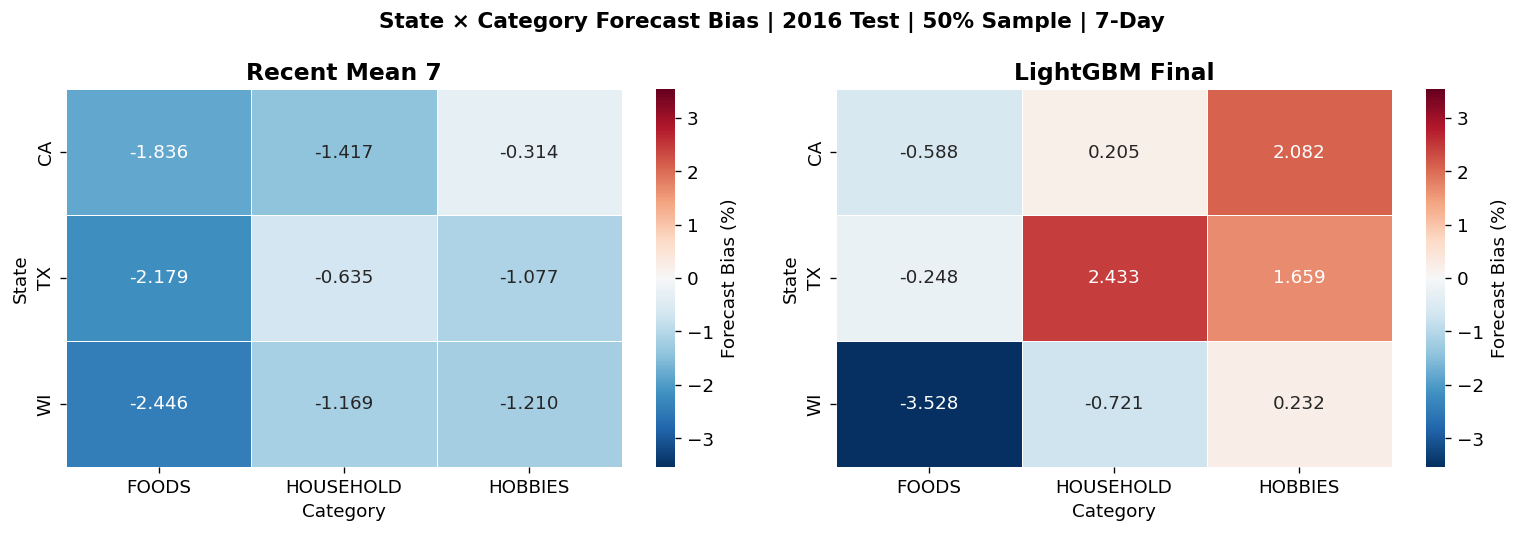

Saved three files to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:

# 16.14A — State × Category Bias Comparison | 2016 Held-Out Test

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Select comparable test results
models = ["recent_mean_7", "lightgbm_final"]
data = lg_test_final[(lg_test_final["sample"] == "50%") & (lg_test_final["horizon"] == 7) & (lg_test_final["model"].isin(models))].copy()
assert data["segment"].str.startswith("state_cat:").any(), "State-category results missing. Re-run the extended evaluation in Cell 153."

# 2. State Bias Comparison
state_bias = data[data["segment"].str.startswith("state:")].pivot(index="segment", columns="model", values="Bias_pct").reindex(columns=models)
state_bias["Bias_Improvement_pp"] = state_bias["recent_mean_7"].abs() - state_bias["lightgbm_final"].abs()
print("=== STATE BIAS | 50% SAMPLE | 7-DAY | 2016 TEST ===")
display(state_bias.round(3))

# 3. State × Category Bias Comparison
state_cat = data[data["segment"].str.startswith("state_cat:")].copy()
comparison = state_cat.pivot(index="segment", columns="model", values="Bias_pct").reindex(columns=models)
comparison["Bias_Improvement_pp"] = comparison["recent_mean_7"].abs() - comparison["lightgbm_final"].abs()
print("=== STATE × CATEGORY BIAS COMPARISON ===")
display(comparison.round(3))

# 4. Prepare the heatmaps
state_cat[["prefix", "state", "category"]] = state_cat["segment"].str.split(":", expand=True)
states, categories = ["CA", "TX", "WI"], ["FOODS", "HOUSEHOLD", "HOBBIES"]
limit = max(float(state_cat["Bias_pct"].abs().max()), 0.01)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 5. Plot Recent Mean and LightGBM with the same color scale
for ax, model in zip(axes, models):
    temp = state_cat[state_cat["model"] == model]
    matrix = temp.pivot(index="state", columns="category", values="Bias_pct").reindex(index=states, columns=categories)
    sns.heatmap(matrix, ax=ax, annot=True, fmt=".3f", cmap="RdBu_r", center=0, vmin=-limit, vmax=limit, linewidths=0.5, cbar_kws={"label": "Forecast Bias (%)"})
    ax.set_title("Recent Mean 7" if model == "recent_mean_7" else "LightGBM Final", fontweight="bold")
    ax.set_xlabel("Category")
    ax.set_ylabel("State")

fig.suptitle("State × Category Forecast Bias | 2016 Test | 50% Sample | 7-Day", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 6. Export outputs without overwriting existing forecasting files
out = Path(Forecasting_OUTPUT)
out.mkdir(parents=True, exist_ok=True)
state_bias.to_csv(out / "state_bias_comparison_2016.csv")
comparison.to_csv(out / "state_category_bias_comparison_2016.csv")
fig.savefig(out / "state_category_bias_comparison_2016.png", dpi=300, bbox_inches="tight")
print("Saved three files to:", out)


=== OVERALL ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,All,74.581,71.621,-1.753,-0.7,2.219,2.04,3.969,1.053


=== DEMAND TYPE ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,WAPE_Improvement_pct
0,Erratic,58.448,55.447,-1.043,1.050,5.133
1,Intermittent,89.424,86.927,-2.070,-1.339,2.791
2,Intermittent+Lumpy,87.393,84.556,-1.997,-1.176,3.245
3,Lumpy,83.773,80.331,-1.867,-0.887,4.109
4,No sales,88.806,89.532,-1.046,8.336,-0.817
5,Smooth,48.205,44.625,-1.503,-1.044,7.427
6,Smooth+Erratic,51.186,47.775,-1.369,-0.435,6.664


=== CATEGORY ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,cat:FOODS,67.888,64.625,-2.132,-1.500,2.746,2.501,4.807,0.632
1,cat:HOBBIES,104.789,102.704,-0.737,1.518,1.801,1.710,1.989,-0.781
2,cat:HOUSEHOLD,81.070,78.598,-1.112,0.624,1.496,1.399,3.049,0.488


=== STATE ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,state:CA,75.135,72.200,-1.563,-0.094,2.124,1.978,3.905,1.469
1,state:TX,74.472,72.884,-1.657,0.658,1.923,1.772,2.133,0.998
2,state:WI,73.948,69.779,-2.085,-2.659,2.588,2.350,5.638,-0.574


=== STATE × CATEGORY ===


,segment,WAPE_pct_recent_mean_7,WAPE_pct_lightgbm_final,Bias_pct_recent_mean_7,Bias_pct_lightgbm_final,RMSE_recent_mean_7,RMSE_lightgbm_final,WAPE_Improvement_pct,Absolute_Bias_Improvement_pp
0,state_cat:CA:FOODS,68.622,65.552,-1.836,-0.588,2.464,2.275,4.473,1.249
1,state_cat:CA:HOBBIES,100.349,98.138,-0.314,2.082,2.164,2.067,2.204,-1.768
2,state_cat:CA:HOUSEHOLD,80.676,77.766,-1.417,0.205,1.509,1.408,3.607,1.212
3,state_cat:TX:FOODS,66.861,65.071,-2.179,-0.248,2.311,2.101,2.677,1.931
4,state_cat:TX:HOBBIES,108.978,107.791,-1.077,1.659,1.519,1.445,1.089,-0.582
5,state_cat:TX:HOUSEHOLD,80.274,79.019,-0.635,2.433,1.480,1.399,1.564,-1.798
6,state_cat:WI:FOODS,67.804,63.192,-2.446,-3.528,3.419,3.089,6.803,-1.083
7,state_cat:WI:HOBBIES,109.058,106.237,-1.210,0.232,1.504,1.404,2.587,0.977
8,state_cat:WI:HOUSEHOLD,82.543,79.405,-1.169,-0.721,1.496,1.388,3.802,0.448


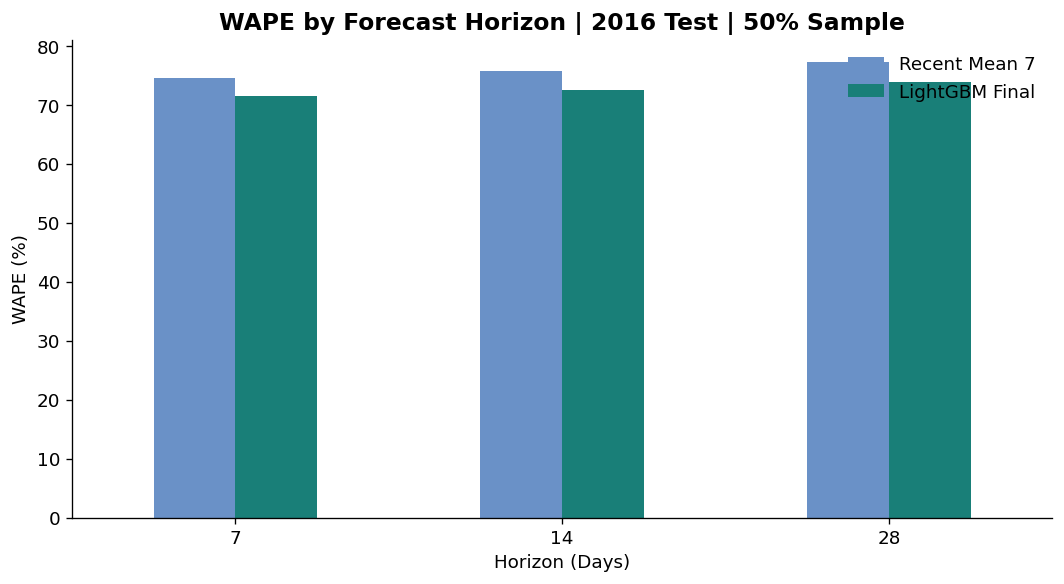

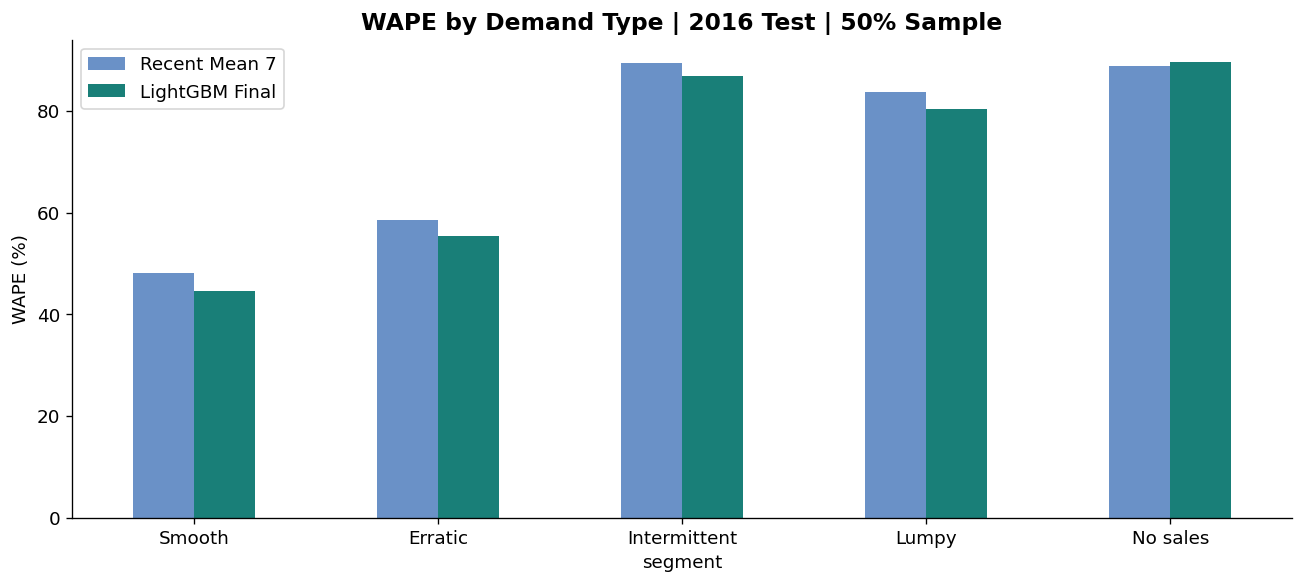

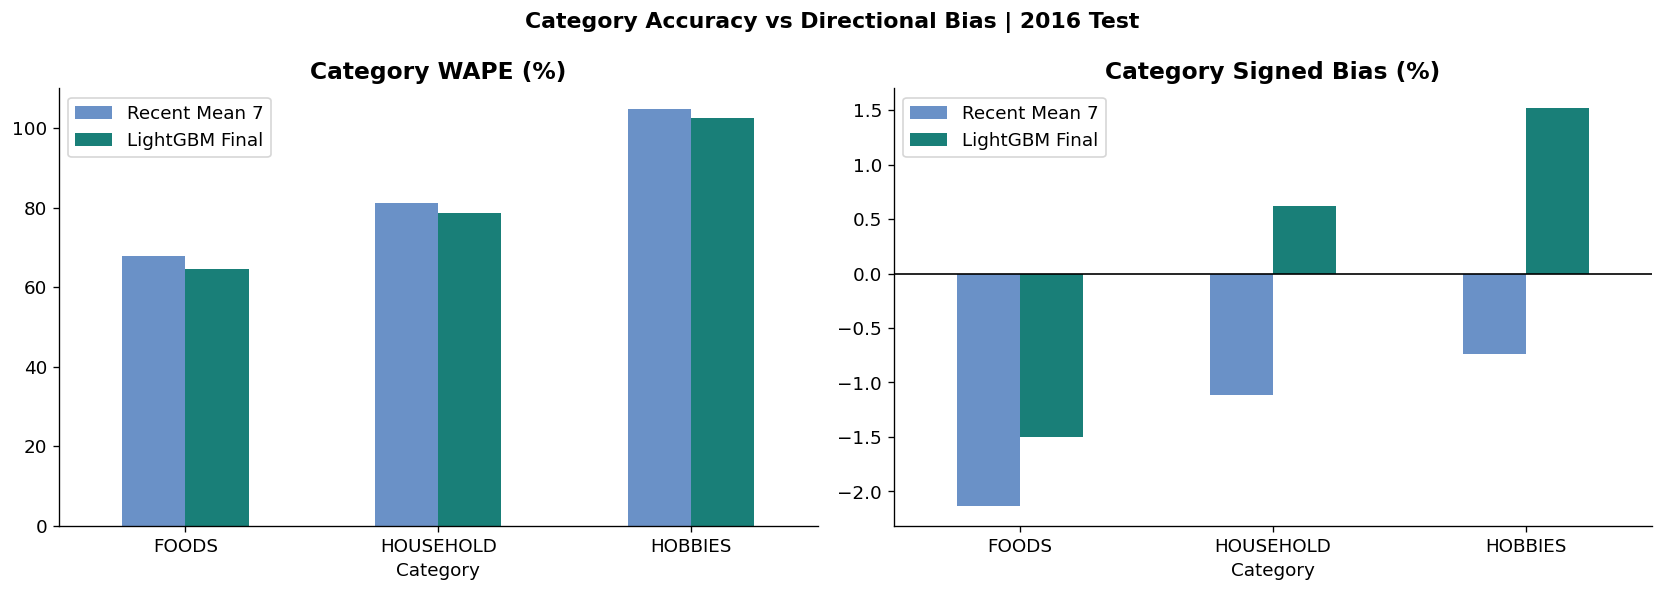

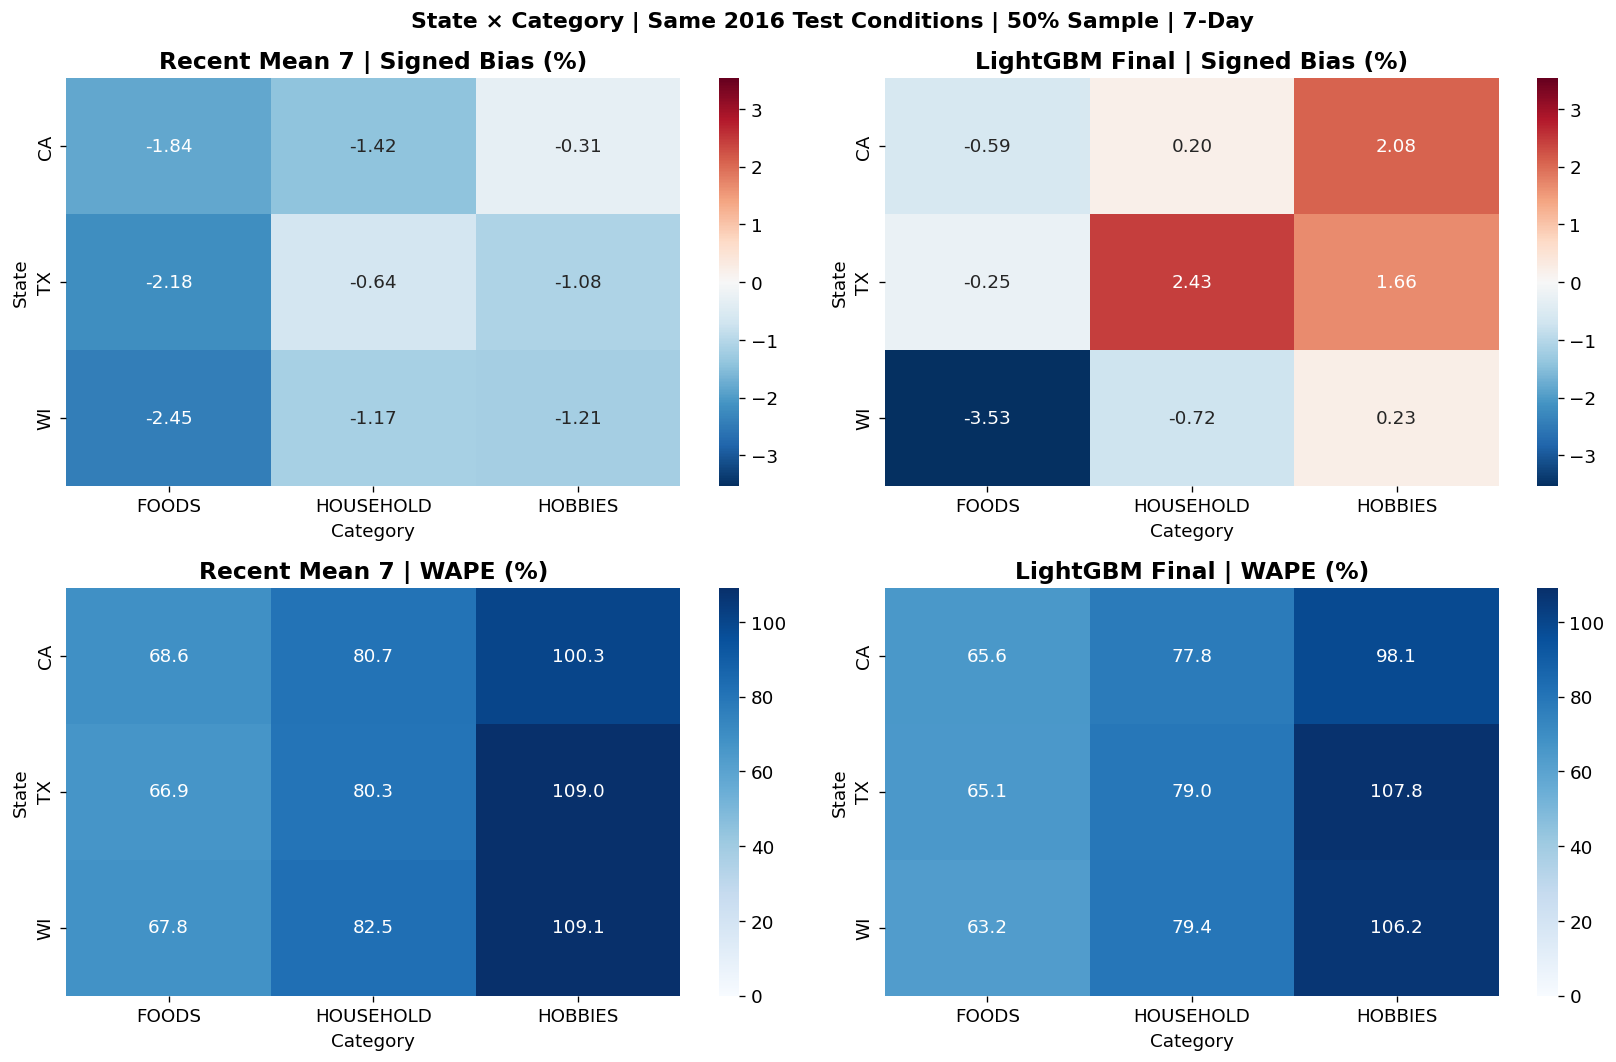

Saved 4 comparison figures and 5 CSV tables to: /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs


In [ ]:

# 16.14B — Sponsor Model Comparison | 2016 Held-Out Test | 50% Sample
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
out = Path(Forecasting_OUTPUT); out.mkdir(parents=True,exist_ok=True)
models = ["recent_mean_7","lightgbm_final"]; x = lg_test_final[(lg_test_final["sample"]=="50%") & (lg_test_final["model"].isin(models))].copy(); names = {"recent_mean_7":"Recent Mean 7","lightgbm_final":"LightGBM Final"}
def compare_segments(prefix,h=7,exact=False):
    d = x[(x["horizon"]==h) & (x["segment"].eq(prefix) if exact else x["segment"].str.startswith(prefix))].copy()
    p = d.pivot(index="segment",columns="model",values=["WAPE_pct","Bias_pct","RMSE"]).reindex(columns=models,level=1)
    p.columns = [f"{a}_{b}" for a,b in p.columns]; p["WAPE_Improvement_pct"] = 100*(p["WAPE_pct_recent_mean_7"]-p["WAPE_pct_lightgbm_final"])/p["WAPE_pct_recent_mean_7"]; p["Absolute_Bias_Improvement_pp"] = p["Bias_pct_recent_mean_7"].abs()-p["Bias_pct_lightgbm_final"].abs(); return p.reset_index()
overall = compare_segments("All",exact=True); dtype = x[(x["horizon"]==7)&(x["segment"].isin(LG_TYPES+["Intermittent+Lumpy","Smooth+Erratic"]))].copy(); demand = dtype.pivot(index="segment",columns="model",values=["WAPE_pct","Bias_pct"]).reindex(columns=models,level=1); demand.columns = [f"{a}_{b}" for a,b in demand.columns]; demand["WAPE_Improvement_pct"] = 100*(demand["WAPE_pct_recent_mean_7"]-demand["WAPE_pct_lightgbm_final"])/demand["WAPE_pct_recent_mean_7"]; demand = demand.reset_index()
category = compare_segments("cat:"); state = compare_segments("state:"); statecat = compare_segments("state_cat:")
assert len(overall)==1 and len(category)==3 and len(state)==3 and len(statecat)==9, "Missing expected segment rows: verify Cell 153 and lg_segments"
print("=== OVERALL ==="); display(overall.round(3)); print("=== DEMAND TYPE ==="); display(demand.round(3)); print("=== CATEGORY ==="); display(category.round(3)); print("=== STATE ==="); display(state.round(3)); print("=== STATE × CATEGORY ==="); display(statecat.round(3))
wide = x[x["segment"]=="All"].pivot(index="horizon",columns="model",values="WAPE_pct").reindex(columns=models); ax = wide.rename(columns=names).plot(kind="bar",figsize=(9,5),color=["#6A91C7","#197F78"],rot=0); ax.set_title("WAPE by Forecast Horizon | 2016 Test | 50% Sample",fontweight="bold"); ax.set_xlabel("Horizon (Days)"); ax.set_ylabel("WAPE (%)"); ax.legend(frameon=False); plt.tight_layout(); plt.savefig(out/"sponsor_model_overall_wape_2016.png",dpi=300,bbox_inches="tight"); plt.show()
d = demand[demand["segment"].isin(LG_TYPES)].set_index("segment").reindex(LG_TYPES); fig,ax = plt.subplots(figsize=(11,5)); pd.DataFrame({"Recent Mean 7":d["WAPE_pct_recent_mean_7"],"LightGBM Final":d["WAPE_pct_lightgbm_final"]}).plot.bar(ax=ax,color=["#6A91C7","#197F78"],rot=0); ax.set_title("WAPE by Demand Type | 2016 Test | 50% Sample",fontweight="bold"); ax.set_ylabel("WAPE (%)"); plt.tight_layout(); fig.savefig(out/"sponsor_model_demand_type_wape_2016.png",dpi=300,bbox_inches="tight"); plt.show()
c = category.copy(); c["Category"] = c["segment"].str.replace("cat:","",regex=False); c = c.set_index("Category").reindex(["FOODS","HOUSEHOLD","HOBBIES"]); fig,axes = plt.subplots(1,2,figsize=(14,5)); pd.DataFrame({"Recent Mean 7":c["WAPE_pct_recent_mean_7"],"LightGBM Final":c["WAPE_pct_lightgbm_final"]}).plot.bar(ax=axes[0],color=["#6A91C7","#197F78"],rot=0); axes[0].set_title("Category WAPE (%)"); pd.DataFrame({"Recent Mean 7":c["Bias_pct_recent_mean_7"],"LightGBM Final":c["Bias_pct_lightgbm_final"]}).plot.bar(ax=axes[1],color=["#6A91C7","#197F78"],rot=0); axes[1].axhline(0,color="black",lw=1); axes[1].set_title("Category Signed Bias (%)"); fig.suptitle("Category Accuracy vs Directional Bias | 2016 Test",fontweight="bold"); plt.tight_layout(); fig.savefig(out/"sponsor_model_category_wape_bias_2016.png",dpi=300,bbox_inches="tight"); plt.show()
sc = statecat.copy(); sc[["prefix","State","Category"]] = sc["segment"].str.split(":",expand=True); fig,axes = plt.subplots(2,2,figsize=(14,9)); lim = max(sc["Bias_pct_recent_mean_7"].abs().max(),sc["Bias_pct_lightgbm_final"].abs().max()); vmax = max(sc["WAPE_pct_recent_mean_7"].max(),sc["WAPE_pct_lightgbm_final"].max())
for j,m in enumerate(models):
    label = names[m]; b = sc.pivot(index="State",columns="Category",values=f"Bias_pct_{m}").reindex(index=["CA","TX","WI"],columns=["FOODS","HOUSEHOLD","HOBBIES"]); w = sc.pivot(index="State",columns="Category",values=f"WAPE_pct_{m}").reindex(index=["CA","TX","WI"],columns=["FOODS","HOUSEHOLD","HOBBIES"]); sns.heatmap(b,annot=True,fmt=".2f",cmap="RdBu_r",center=0,vmin=-lim,vmax=lim,ax=axes[0,j]); sns.heatmap(w,annot=True,fmt=".1f",cmap="Blues",vmin=0,vmax=vmax,ax=axes[1,j]); axes[0,j].set_title(f"{label} | Signed Bias (%)"); axes[1,j].set_title(f"{label} | WAPE (%)")
fig.suptitle("State × Category | Same 2016 Test Conditions | 50% Sample | 7-Day",fontweight="bold"); plt.tight_layout(); fig.savefig(out/"sponsor_model_state_category_wape_bias_2016.png",dpi=300,bbox_inches="tight"); plt.show()
for name,t in [("overall",overall),("demand_type",demand),("category",category),("state",state),("state_category",statecat)]: t.to_csv(out/f"sponsor_model_{name}_2016.csv",index=False)
print("Saved 4 comparison figures and 5 CSV tables to:",out)


## 16.15 Final forecast file (the only file saved)

In [ ]:
# 16.15 Final forecast file: teammate's early version (Recent Mean) + final LightGBM, same format, origin 2015-12-31, next 7 days (the only file this section saves)
assert "test_models" in globals() and "wf_raw" in globals(), "Run 16.12, 16.13 and 16.14 first (they hold the final model and the 2015 forecasts)."
t0 = time.time()
early = forecast_50.copy() if "forecast_50" in globals() else pd.read_csv(Path(Forecasting_OUTPUT) / "forecast_predictions_7day_50.csv")
o_final = LG_VAL_END - 1                                                        # last day of 2015 = forecast origin
assert early["forecast_origin"].nunique() == 1 and pd.Timestamp(early["forecast_origin"].iloc[0]) == pd.Timestamp(calendar.set_index("d").loc[day_cols[o_final], "date"])
M, ids = sample50_matrix, metadata_50["id"].tolist()
assert early["series_id"].drop_duplicates().tolist() == ids, "Series order differs from the early forecast file."
types = demand_type_50["Demand_Type"].to_numpy()

# 1) 2015 forecasts with the same trailing correction -> out-of-time errors -> P10/P90 offsets (same method as the early version)
raw_val, hist, resid = wf_raw["50%"], {}, []
def trailing_factor(o):
    past = [p for p in lg_val_origins if p <= o - 7][-LG_TRAIL_WEEKS:]
    f = np.ones(len(types), dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
            if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
    return f
for o in lg_val_origins:
    actual = M[:, o + 1:o + 8].astype(np.float64)
    resid.append(actual - raw_val[o][:, :7] * trailing_factor(o)[:, None])
    hist[o] = {t: (actual.sum(axis=1)[types == t].sum(), raw_val[o][:, :7].sum(axis=1)[types == t].sum()) for t in LG_TYPES}
resid = np.stack(resid)                                                          # origins x series x 7 leads
pooled10, pooled90 = np.quantile(resid, 0.10, axis=(0, 1)), np.quantile(resid, 0.90, axis=(0, 1))
type10, type90 = np.empty((len(types), 7)), np.empty((len(types), 7))
for t in np.unique(types):
    idx = np.where(types == t)[0]
    type10[idx], type90[idx] = np.quantile(resid[:, idx, :], 0.10, axis=(0, 1)), np.quantile(resid[:, idx, :], 0.90, axis=(0, 1))
del resid

# 2) final LightGBM point forecast for Jan 1-7, 2016 (model trained on 2011-2015 only, then the trailing correction)
ctx = lg_context(M, ids, demand_type_50)
point = lg_predict(ctx, test_models[LG_VAL_END], [o_final], LG_ALL)[o_final][:, :7] * trailing_factor(o_final)[:, None]
del ctx

# 3) same layout as the early version
dates = early.drop_duplicates("lead").set_index("lead")["target_date"]
parts = []
for method, q10, q90 in [("Pooled", pooled10[None, :], pooled90[None, :]), ("Demand-Type", type10, type90)]:
    p10 = np.maximum(0, point + q10); p90 = np.maximum(p10, point + q90)
    for lead in range(1, 8):
        parts.append(pd.DataFrame({"series_id": ids, "forecast_origin": early["forecast_origin"].iloc[0], "target_date": dates[lead], "lead": lead, "horizon": 7,
                                   "model": "LightGBM (retrained quarterly + bias correction)", "method": method, "point_forecast": point[:, lead - 1],
                                   "p10": p10[:, lead - 1], "p90": p90[:, lead - 1], "sample": "50%", "forecast_type": "historical_holdout", "model_role": "final"}))
final = pd.concat([early.assign(model_role="early_version")] + parts, ignore_index=True)

# 4) checks (same rules as the early version's data contract)
key = ["series_id", "forecast_origin", "target_date", "model", "method"]
assert final["p10"].le(final["p90"]).all() and np.isfinite(final[["point_forecast", "p10", "p90"]].to_numpy()).all() and (final[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not final.duplicated(key).any() and final.groupby(["series_id", "model", "method"]).size().eq(7).all()
assert final["series_id"].nunique() == len(ids) and final["model"].nunique() == 2

out_path = Path(Forecasting_OUTPUT) / "forecast_predictions_7day_50_final.csv"
final.to_csv(out_path, index=False)
print(f"Saved {len(final):,} rows to {out_path}  ({time.time() - t0:.0f}s)")
chk = final.groupby(["model", "method"]).agg(total_units_7d=("point_forecast", "sum"), mean_p10_p90_width=("p90", "sum"))
chk["mean_p10_p90_width"] = (final["p90"] - final["p10"]).groupby([final["model"], final["method"]]).mean()
display(chk.round(2))
display(final.query("series_id == @ids[0] and method == 'Pooled'").round(3))

Saved 426,860 rows to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_7day_50_final.csv  (24s)


total_units_7d  \
model                                            method                        
LightGBM (retrained quarterly + bias correction) Demand-Type   136271.640625   
                                                 Pooled        136271.640625   
Recent Mean (7-day)                              Demand-Type   105227.000000   
                                                 Pooled        105227.000000   

                                                              mean_p10_p90_width  
model                                            method                           
LightGBM (retrained quarterly + bias correction) Demand-Type                2.16  
                                                 Pooled                     1.99  
Recent Mean (7-day)                              Demand-Type                2.02  
                                                 Pooled                     1.77

,series_id,forecast_origin,target_date,lead,horizon,model,method,point_forecast,p10,p90,sample,forecast_type,model_role
0,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,Recent Mean (7-day),Pooled,0.143,0.0,1.857,50%,historical_holdout,early_version
15245,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-02,2,7,Recent Mean (7-day),Pooled,0.143,0.0,1.857,50%,historical_holdout,early_version
30490,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-03,3,7,Recent Mean (7-day),Pooled,0.143,0.0,1.286,50%,historical_holdout,early_version
45735,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-04,4,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
60980,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-05,5,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
76225,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-06,6,7,Recent Mean (7-day),Pooled,0.143,0.0,1.143,50%,historical_holdout,early_version
91470,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-07,7,7,Recent Mean (7-day),Pooled,0.143,0.0,1.429,50%,historical_holdout,early_version
213430,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-01,1,7,LightGBM (retrained quarterly + bias correction),Pooled,0.604,0.0,1.855,50%,historical_holdout,final
228675,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-02,2,7,LightGBM (retrained quarterly + bias correction),Pooled,0.910,0.0,2.261,50%,historical_holdout,final
243920,HOBBIES_1_002_CA_1_evaluation,2015-12-31,2016-01-03,3,7,LightGBM (retrained quarterly + bias correction),Pooled,0.835,0.0,2.346,50%,historical_holdout,final


In [ ]:
# One-off check: the file's Jan 1-7, 2016 forecast totals against what actually sold
actual = fulls["50%"][:, LG_VAL_END:LG_VAL_END + 7].sum()
print("Daily units, Dec 25-31 2015:", sample50_matrix[:, LG_VAL_END - 7:].sum(axis=0).astype(int))
print("Daily units, Jan 1-7 2016:  ", fulls["50%"][:, LG_VAL_END:LG_VAL_END + 7].sum(axis=0).astype(int))
print(f"Actual units sold Jan 1-7, 2016: {actual:,.0f}")
for m, v in final[final["method"] == "Pooled"].groupby("model")["point_forecast"].sum().items():
    print(f"{m}: forecast {v:,.0f}  ({100 * (v - actual) / actual:+.1f}% vs actual)")

Daily units, Dec 25-31 2015: [    9 18926 17378 14810 15885 16678 21541]
Daily units, Jan 1-7 2016:   [16446 22492 22093 18082 17534 16283 17985]
Actual units sold Jan 1-7, 2016: 130,915
LightGBM (retrained quarterly + bias correction): forecast 136,272  (+4.1% vs actual)
Recent Mean (7-day): forecast 105,227  (-19.6% vs actual)


In [ ]:
# 16.16 Check the P10-P90 ranges on 2016: how often did real daily sales fall inside them? (target is 80%)
assert "test_models" in globals() and "pooled10" in globals(), "Run 16.14 and 16.15 first."
t0 = time.time()
M, ids = fulls["50%"], metadata_50["id"].tolist()
types = demand_type_50["Demand_Type"].to_numpy()
masks = {"All": np.ones(len(types), dtype=bool), "Intermittent+Lumpy": np.isin(types, ["Intermittent", "Lumpy"]), "Smooth+Erratic": np.isin(types, ["Smooth", "Erratic"])}
ctx = lg_context(M, ids, demand_type_50)
raw = {}
for s_ in starts_t:
    os_ = [o for o in test_origins if block_of_t(o) == s_]
    if os_: raw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
del ctx
allraw = {**wf_raw["50%"], **raw}
rm7 = lg_recent_mean(M, 7, test_origins)
offsets = {"LightGBM (final)": {"Pooled": (pooled10[None, :], pooled90[None, :]), "Demand-Type": (type10, type90)},
           "Recent Mean (early version)": {"Pooled": (pi_cal_50["pooled10"][None, :], pi_cal_50["pooled90"][None, :]),
                                           "Demand-Type": (pi_cal_50["type10"], pi_cal_50["type90"])}}
stats, hist = {}, {}
for o in lg_val_origins + test_origins:                                # in time order, same trailing correction as 16.14
    if o in raw:
        past = [p for p in (lg_val_origins + test_origins) if p <= o - 7][-LG_TRAIL_WEEKS:]
        f = np.ones(len(types), dtype=np.float32)
        if len(past) >= LG_MIN_WEEKS:
            for t in LG_TYPES:
                a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
                if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
        points = {"LightGBM (final)": raw[o][:, :7] * f[:, None], "Recent Mean (early version)": np.repeat(rm7[o][:, None], 7, axis=1)}
        act = M[:, o + 1:o + 8]
        for model, point in points.items():
            for method, (q10, q90) in offsets[model].items():
                lo = np.maximum(0, point + q10); hi = np.maximum(lo, point + q90)
                inside = (act >= lo) & (act <= hi)
                for seg_name, m in masks.items():
                    s = stats.setdefault((model, method, seg_name), [0, 0, 0.0])
                    s[0] += inside[m].sum(); s[1] += inside[m].size; s[2] += (hi - lo)[m].sum()
    a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
    hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
cov = pd.DataFrame([{"model": k[0], "method": k[1], "series group": k[2], "coverage_%": 100 * v[0] / v[1], "mean_width": v[2] / v[1]} for k, v in stats.items()])
print(f"2016 test, 50% sample, daily sales inside P10-P90 (target 80%)  ({time.time() - t0:.0f}s)")
display(cov.pivot_table(index=["model", "method"], columns="series group", values="coverage_%").round(1))
display(cov.pivot_table(index=["model", "method"], columns="series group", values="mean_width").round(2))

2016 test, 50% sample, daily sales inside P10-P90 (target 80%)  (199s)


series group                              All  Intermittent+Lumpy  \
model                       method                                  
LightGBM (final)            Demand-Type  77.7                78.0   
                            Pooled       78.2                82.2   
Recent Mean (early version) Demand-Type  76.3                78.0   
                            Pooled       77.8                81.7   

series group                             Smooth+Erratic  
model                       method                       
LightGBM (final)            Demand-Type            79.6  
                            Pooled                 40.7  
Recent Mean (early version) Demand-Type            80.5  
                            Pooled                 41.6

series group                              All  Intermittent+Lumpy  \
model                       method                                  
LightGBM (final)            Demand-Type  2.19                1.75   
                            Pooled       2.02                1.97   
Recent Mean (early version) Demand-Type  2.14                1.72   
                            Pooled       1.88                1.83   

series group                             Smooth+Erratic  
model                       method                       
LightGBM (final)            Demand-Type            6.46  
                            Pooled                 2.48  
Recent Mean (early version) Demand-Type            6.79  
                            Pooled                 2.38

In [ ]:
# Feature engineering summary: the 28 features by group, and how much the final model relies on each (nothing is saved)
groups = {"Recent sales (averages, spread, zero days)": ["m7", "m14", "m28", "m56", "m365", "std28", "zero28", "zero365", "days_since_sale", "pos_mean56"],
          "Same weekday in recent weeks": ["sw_mean4", "sw_last"],
          "Calendar (weekday, day, month, events, SNAP)": ["dow", "dom", "month", "event", "snap"],
          "Price": ["price_t", "price_ratio_56", "price_change_vs_origin"],
          "Item and store type": ["cat", "dept", "store", "state", "demand_type", "adi", "cv2"],
          "How far ahead (lead)": ["lead"]}
assert sorted(sum(groups.values(), [])) == sorted(LG_FEATURES)
booster = test_models[LG_VAL_END].booster_                                       # final model, trained on 2011-2015
imp = pd.Series(booster.feature_importance(importance_type="gain"), index=booster.feature_name())
share = 100 * imp / imp.sum()
display(pd.DataFrame([{"feature group": g, "features": len(f), "share of model gain (%)": share[f].sum()} for g, f in groups.items()])
        .sort_values("share of model gain (%)", ascending=False).round(1))
display(share.sort_values(ascending=False).head(15).round(1).to_frame("share of gain (%)"))

,feature group,features,share of model gain (%)
0,"Recent sales (averages, spread, zero days)",10,89.3
3,Price,3,5.1
4,Item and store type,7,3.3
2,"Calendar (weekday, day, month, events, SNAP)",5,1.2
1,Same weekday in recent weeks,2,0.7
5,How far ahead (lead),1,0.3


,share of gain (%)
m28,52.0
m14,14.0
m56,8.6
pos_mean56,7.3
price_t,3.9
std28,3.3
adi,2.2
m7,1.8
m365,1.0
price_ratio_56,0.8


In [ ]:
# 16.17 RAG scenario forecasts: final LightGBM, 14 days ahead from each scenario date (for the RAG agent)
# Reads rag_scenarios_for_forecast_v2_lightgbm.csv (from the RAG notebook) and saves forecast_predictions_rag_scenarios.csv.
# Same recipe as the final file (16.15): for each date it uses only the model that existed then (wf_models in 2015,
# test_models from 2015-12-31), the same trailing bias correction from past weeks only, and Demand-Type P10/P90.
# Run after 16.12-16.15 in the same session (it needs wf_models, wf_raw, test_models, test_origins, fulls, type10/type90).
assert all(v in globals() for v in ["wf_models", "wf_raw", "test_models", "test_origins", "fulls", "type10", "type90"]), \
    "Run 16.12 to 16.15 first in this session."
t0 = time.time()
RAG_HORIZON = 14                                                    # lead time 7 + review period 7
REQUEST_NAME = "rag_scenarios_for_forecast_v2_lightgbm.csv"
_candidates = [Path(Forecasting_OUTPUT) / REQUEST_NAME, Path(Forecasting_OUTPUT).parent.parent / "RAG" / REQUEST_NAME]
req_path = next((p for p in _candidates if p.exists()), None)
assert req_path is not None, f"Put {REQUEST_NAME} in {Forecasting_OUTPUT} (or the shared RAG folder)."
req = pd.read_csv(req_path)
print(f"{len(req)} scenarios from {req_path}")

M, ids = fulls["50%"], metadata_50["id"].tolist()
types = demand_type_50["Demand_Type"].to_numpy()
row_of = {s: i for i, s in enumerate(ids)}
dates = pd.to_datetime(calendar.set_index("d").loc[day_cols, "date"]).reset_index(drop=True)
day_of = {d: i for i, d in enumerate(dates)}

# Past forecasts for the trailing correction: 2015 (walk-forward) + 2016 (test models), computed only if a scenario needs them
o_list = [day_of[pd.Timestamp(d)] for d in req["forecast_origin"]]
allraw = dict(wf_raw["50%"])
ctx = lg_context(M, ids, demand_type_50)
need_2016 = [p for p in test_origins if any(p <= o - 7 for o in o_list)]
for s_ in starts_t:
    os_ = [p for p in need_2016 if block_of_t(p) == s_]
    if os_: allraw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
past_origins = sorted(p for p in (lg_val_origins + test_origins) if p in allraw)

def trailing_factor_at(o):
    """Same correction as 16.13/16.14: scale each demand type by actual / forecast over the last 13 weeks already known at day o."""
    past = [p for p in past_origins if p <= o - 7][-LG_TRAIL_WEEKS:]
    f = np.ones(len(types), dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            m = types == t
            a = sum(M[m, p + 1:p + 8].sum() for p in past)
            fc = sum(allraw[p][m, :7].sum() for p in past)
            if a > 0 and fc > 0: f[m] = np.clip(a / fc, *LG_CLIP)
    return f

def model_at(o):
    """The model that existed on day o: walk-forward models during 2015, the 2011-2015 test models from 2015-12-31 on."""
    return test_models[block_of_t(o)] if o >= LG_VAL_END - 1 else wf_models[block_of(o)]

parts, skipped = [], []
for o in sorted(set(o_list)):
    rows = req[[day_of[pd.Timestamp(d)] == o for d in req["forecast_origin"]]]
    missing = [s for s in rows["series_id"] if s not in row_of]
    if missing: skipped += [(s, "not in the 50% sample") for s in missing]
    keep = [row_of[s] for s in rows["series_id"] if s in row_of]
    hmax = min(RAG_HORIZON, LG_N_DAYS - 1 - o)
    if hmax < RAG_HORIZON:
        skipped += [(ids[i], f"only {hmax} days of calendar/price data after {dates[o].date()}") for i in keep]
        if hmax <= 0: continue
    point = lg_predict(ctx, model_at(o), [o], LG_ALL)[o][:, :hmax] * trailing_factor_at(o)[:, None]
    lead_off = np.minimum(np.arange(hmax), 6)                         # days 8-14 reuse the day-7 Demand-Type offsets
    q10, q90 = type10[:, lead_off], type90[:, lead_off]
    p10 = np.maximum(0, point + q10); p90 = np.maximum(p10, point + q90)
    for i in keep:
        parts.append(pd.DataFrame({"series_id": ids[i], "forecast_origin": dates[o].strftime("%Y-%m-%d"),
                                   "target_date": [dates[o + h].strftime("%Y-%m-%d") for h in range(1, hmax + 1)],
                                   "lead": np.arange(1, hmax + 1), "horizon": RAG_HORIZON,
                                   "model": "LightGBM (retrained quarterly + bias correction)", "method": "Demand-Type",
                                   "point_forecast": point[i], "p10": p10[i], "p90": p90[i], "sample": "50%",
                                   "forecast_type": "historical_holdout", "model_role": "final"}))
    print(f"  {dates[o].date()}: {len(keep)} series, {hmax} days ({time.time() - t0:.0f}s)")

# Check: the same code for 2015-12-31 must reproduce the final file's LightGBM (first 7 days)
o_chk = LG_VAL_END - 1
chk_point = lg_predict(ctx, model_at(o_chk), [o_chk], LG_ALL)[o_chk][:, :7] * trailing_factor_at(o_chk)[:, None]
del ctx
ref = final.query("model_role == 'final' and method == 'Demand-Type'") if isinstance(globals().get("final"), pd.DataFrame) else None
if ref is not None:
    ref_pts = ref.pivot(index="series_id", columns="lead", values="point_forecast").loc[ids].to_numpy()
    print(f"Check against the final file (2015-12-31): largest difference {np.abs(ref_pts - chk_point).max():.6f} units",
          "(OK)" if np.allclose(ref_pts, chk_point, atol=1e-3) else "(CHECK)")

out = pd.concat(parts, ignore_index=True)
assert out["p10"].le(out["p90"]).all() and (out[["point_forecast", "p10", "p90"]] >= 0).all().all()
assert not out.duplicated(["series_id", "forecast_origin", "lead"]).any()
out_path = Path(Forecasting_OUTPUT) / "forecast_predictions_rag_scenarios.csv"
out.to_csv(out_path, index=False)
print(f"Saved {len(out):,} rows ({out['series_id'].nunique()} series, {out['forecast_origin'].nunique()} dates) to {out_path} "
      f"({time.time() - t0:.0f}s)")
for s, why in skipped:
    print("  Skipped or shortened:", s, "-", why)
display(out.groupby(["series_id", "forecast_origin"]).agg(days=("lead", "size"), units_14d=("point_forecast", "sum")).round(1))

8 scenarios from /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/RAG/rag_scenarios_for_forecast_v2_lightgbm.csv
  2015-01-05: 1 series, 14 days (207s)
  2015-05-27: 1 series, 14 days (219s)
  2015-06-01: 1 series, 14 days (230s)
  2015-08-03: 1 series, 14 days (242s)
  2015-09-01: 1 series, 14 days (253s)
  2015-11-16: 1 series, 14 days (263s)
  2015-12-14: 1 series, 14 days (275s)
  2016-05-08: 1 series, 14 days (279s)
Check against the final file (2015-12-31): largest difference 0.000008 units (OK)
Saved 112 rows (7 series, 8 dates) to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/forecast_predictions_rag_scenarios.csv (291s)


days    units_14d
series_id                       forecast_origin                   
FOODS_3_377_TX_3_evaluation     2015-05-27         14   544.500000
FOODS_3_586_CA_1_evaluation     2015-11-16         14   568.799988
                                2015-12-14         14   602.099976
FOODS_3_586_TX_1_evaluation     2015-08-03         14  1004.599976
HOBBIES_1_268_WI_2_evaluation   2015-01-05         14    47.099998
HOUSEHOLD_1_067_TX_2_evaluation 2015-06-01         14     1.400000
HOUSEHOLD_1_131_WI_1_evaluation 2015-09-01         14     0.500000
HOUSEHOLD_1_459_CA_2_evaluation 2016-05-08         14    95.500000

# Final Summary: Forecasting Model Selection

## What we did
We compared eight ways to forecast daily sales for the next 7, 14 and 28 days on the Walmart M5 data: Always guess zero, Copy last week (Weekly Seasonal Naive), Recent Mean (7-day and 28-day), Croston, SBA, TSB, and LightGBM. Every model used the same item samples (20% = 6,098 and 50% = 15,245 series), the same time splits (train 2011-2014, validation 2015, test 2016 used once), the same weekly forecast dates, and the same scores (WAPE, bias, RMSE, and results by demand type). A pass/fail rule was fixed before testing.

## Decision
**Final forecasting model: LightGBM, retrained about every quarter, with a trailing bias correction.**
Recent Mean (7-day) is the strongest simple baseline. Recent Mean (28-day) and TSB stay as comparison models.

## Results (50% sample, WAPE %, lower is better)

| Model | 7-day | 14-day | 28-day | Bias, 7-day |
|---|---|---|---|---|
| Recent Mean, 7-day | 77.5 | 79.1 | 81.0 | -0.1% |
| Recent Mean, 28-day | 77.8 | 78.6 | 80.2 | -0.5% |
| Croston | 87.2 | 87.3 | 87.6 | +7.1% |
| SBA | 85.9 | 86.3 | 86.8 | +0.9% |
| TSB | 76.4 | 77.5 | 79.2 | -1.0% |
| LightGBM, first try | 74.9 | 76.3 | 78.2 | -4.4% (failed) |
| LightGBM, final (2015 validation) | 75.0 | 76.3 | 78.2 | -0.3% |

**Final test on 2016 (run once, 50% sample):**

| | 7-day | 14-day | 28-day | Bias, 7-day | RMSE, 7-day |
|---|---|---|---|---|---|
| LightGBM, final | 71.6 | 72.6 | 73.9 | -0.7% | 2.040 |
| Recent Mean, 7-day | 74.6 | 75.8 | 77.3 | -1.8% | 2.219 |
| Recent Mean, 28-day | 73.9 | 74.7 | 75.9 | -2.8% | 2.202 |

LightGBM passed all four rules on both samples and at all three horizons. It made about 4% fewer mistakes than Recent Mean (7-day) and had about 8% lower RMSE. The 20% sample agrees (70.3 against 73.4 at 7 days).

## Why this model
- **Croston and SBA** made more mistakes than the simple average, and Croston guessed too high.
- **TSB** was only 1 to 2% better, below our 2% bar.
- **LightGBM's first try** was the most accurate but guessed about 4.4% too low, because sales grew 11 to 15% after its training years. Using 2014 data to adjust did not help. Retraining quarterly helped (-3.1%). Retraining plus nudging by the last 13 weeks of known errors fixed it (-0.3%).

## Prediction ranges (P10 to P90)
On 2016, real daily sales fell inside the LightGBM ranges 77.7% of the time (target 80%): 78.0% for rarely sold items and 79.6% for steady items. The Pooled method looked fine overall (78.2%) but covered only 40.7% for steady items. **Use the Demand-Type method.**

## What the model relies on (28 features in 6 groups)

| Group | Features | Share of model gain |
|---|---|---|
| Recent sales (averages, spread, zero days) | 10 | 89.3% |
| Price | 3 | 5.1% |
| Item and store type | 7 | 3.3% |
| Calendar (weekday, events, SNAP) | 5 | 1.2% |
| Same weekday in recent weeks | 2 | 0.7% |
| How far ahead | 1 | 0.3% |

The 28-day average alone is about half. The model's edge comes from blending several recent windows, not from calendar clues. This shows what the model relies on, not what each feature adds in accuracy. We did not run the test that turns features off one at a time.

## Final forecast file
`forecast_predictions_7day_50_final.csv` has 426,860 rows: the early Recent Mean version and the final LightGBM, each with both interval methods, for Jan 1 to 7, 2016 from the last day of 2015. Check: 130,915 units actually sold that week. LightGBM forecast 136,272 (+4.1%). Recent Mean forecast 105,227 (-19.6%), because Christmas Day was in its last 7 days.

## Limits
- It is a historical forecast, not a live one. The test covers about 20 weeks of 2016.
- Only the 50% sample (15,245 series) is in the file, and only the 7-day forecast.
- Zero sales do not always mean zero demand. Stock on hand, lead time and costs are assumptions, because M5 has no inventory data.
- We tried several fixes on 2015 data before the 2016 test, so the 2015 scores are slightly flattering.
- At 14 and 28 days the bias is above 1 point (-1.3%, -1.7%), but lower than Recent Mean's, which our rule allows.
- Overall range coverage is about 2 points under the 80% target.

## Next steps
1. Switch the dashboard and the assistant to the LightGBM rows with `method = Demand-Type`.
2. Agree on one ordering rule for both.
3. Test the ordering advice on 2016: stockouts and extra stock against a simple rule.
4. Optional: the feature on/off test, and weather data.

In [ ]:
# 16.18 Segment files for the RAG agent (run once after 16.14; about 4-5 minutes)
# Saves two small files to Forecasting_OUTPUT. Nothing else in the notebook changes.
#   series_segments_50.csv            One row per series: demand type and volume level (from 2011-2014 sales only, Section 11 rules),
#                                     plus the first date each item sold and the first date it had a price (for the new-item flag).
#   lightgbm_error_by_segment_50.csv  Final LightGBM error and bias by segment for every weekly forecast date in 2015-2016,
#                                     7- and 14-day horizons, with the date each result became known (known_date).
#                                     The RAG agent adds up only rows with known_date <= the decision date, so it never quotes future errors.
# Same forecasts as 16.13/16.14: walk-forward models in 2015, test models in 2016, same trailing bias correction (past weeks only).
need = ["wf_raw", "test_models", "test_origins", "starts_t", "block_of_t", "fulls", "demand_type_50", "demand_quantile_50", "lg_val_origins"]
missing = [v for v in need if v not in globals()]
assert not missing, f"Run Section 11 and 16.12-16.14 first in this session. Missing: {missing}"
t0 = time.time()
out_dir = Path(Forecasting_OUTPUT)
M, ids = fulls["50%"], metadata_50["id"].tolist()
n = len(ids)
dt, dq = demand_type_50.reset_index(drop=True), demand_quantile_50.reset_index(drop=True)
assert dt["id"].tolist() == ids and dq["id"].tolist() == ids, "Series order differs between metadata_50, demand_type_50 and demand_quantile_50."
dates = pd.to_datetime(calendar.set_index("d").loc[day_cols, "date"]).reset_index(drop=True)
parsed = lg_parse_ids(ids)
types = dt["Demand_Type"].astype(str).to_numpy()
levels = dq["Demand_Quantile"].astype(str).to_numpy()

# 1) One row per series: segments (training period only) + first sale / first price dates
def first_day(mask):
    """Date of the first True in each row, or NaT if never."""
    ix = mask.argmax(axis=1)
    return pd.Series(np.where(mask.any(axis=1), dates.values[ix], np.datetime64("NaT")))

PR = lg_price_matrix(parsed)
segments = pd.DataFrame({
    "series_id": ids, "item_id": parsed["item"].values, "dept_id": parsed["dept"].values, "cat_id": parsed["cat"].values,
    "store_id": parsed["store"].values, "state_id": parsed["state"].values,
    "demand_type": types, "ADI": dt["ADI"].round(4).values, "CV2": dt["CV2"].round(4).values,
    "volume_level": levels, "avg_daily_sales_train": dq["avg_daily_sales"].round(4).values,
    "zero_sales_rate_train": dq["zero_sales_rate"].round(4).values,
    "first_sale_date": first_day(M > 0).dt.date, "first_price_date": first_day(~np.isnan(PR)).dt.date,
    "segments_from": f"{dates[0]:%Y-%m-%d} to {dates[len(train_days) - 1]:%Y-%m-%d} (training period only)"})
del PR
seg_path = out_dir / "series_segments_50.csv"
segments.to_csv(seg_path, index=False)
print(f"Saved {len(segments):,} series to {seg_path}  ({time.time() - t0:.0f}s)")

# 2) Final LightGBM forecasts for every weekly origin, 2015 (walk-forward) + 2016 (test models), same trailing correction as 16.14
ctx = lg_context(M, ids, demand_type_50)
raw = {}
for s_ in starts_t:
    os_ = [o for o in test_origins if block_of_t(o) == s_]
    if os_: raw.update(lg_predict(ctx, test_models[s_], os_, LG_ALL))
del ctx
allraw = {**wf_raw["50%"], **raw}
order = lg_val_origins + test_origins                                   # in time order
hist, cal = {}, {}
for o in order:
    past = [p for p in order if p <= o - 7][-LG_TRAIL_WEEKS:]           # origins whose 7-day outcome is known at day o
    f = np.ones(n, dtype=np.float32)
    if len(past) >= LG_MIN_WEEKS:
        for t in LG_TYPES:
            a, fc = sum(hist[p][t][0] for p in past), sum(hist[p][t][1] for p in past)
            if a > 0 and fc > 0: f[types == t] = np.clip(a / fc, *LG_CLIP)
    cal[o] = allraw[o][:, :14] * f[:, None]
    a7, f7 = M[:, o + 1:o + 8].sum(axis=1), allraw[o][:, :7].sum(axis=1)
    hist[o] = {t: (a7[types == t].sum(), f7[types == t].sum()) for t in LG_TYPES}
del raw, allraw
print(f"Forecasts ready for {len(cal)} weekly origins  ({time.time() - t0:.0f}s)")

# 3) Error and bias by segment, per origin and horizon
masks = {("all", "All"): np.ones(n, dtype=bool)}
for t in LG_TYPES: masks[("demand_type", t)] = types == t
for q in ["Low", "Medium", "High"]: masks[("volume_level", q)] = levels == q
for c in LG_CODES["cat"]: masks[("category", c)] = parsed["cat"].to_numpy() == c
for s in LG_CODES["state"]: masks[("state", s)] = parsed["state"].to_numpy() == s
assert sum(masks[("volume_level", q)].sum() for q in ["Low", "Medium", "High"]) == n, "Unexpected volume level labels."

rows = []
for h in (7, 14):
    for period, origins in [("2015 validation", lg_origins(h, LG_FIRST, LG_VAL_END)), ("2016 test", lg_origins(h, LG_VAL_END - 1, LG_N_DAYS))]:
        for o in origins:
            a = M[:, o + 1:o + 1 + h].astype(np.float64)
            fc = cal[o][:, :h].astype(np.float64)
            act, fcs, ae, se = a.sum(axis=1), fc.sum(axis=1), np.abs(fc - a).sum(axis=1), (fc - a).sum(axis=1)
            for (kind, name), m in masks.items():
                if not m.any(): continue
                rows.append({"period": period, "origin_date": dates[o].date(), "horizon": h, "known_date": dates[o + h].date(),
                             "segment_type": kind, "segment": name, "n_series": int(m.sum()),
                             "actual_units": act[m].sum(), "forecast_units": fcs[m].sum(), "abs_error": ae[m].sum(), "signed_error": se[m].sum()})
err = pd.DataFrame(rows)
del cal

# 4) Check: pooled over each period, the totals must match 16.13 / 16.14 (lg_val, lg_test_final)
chk = []
for period, ref in [("2015 validation", globals().get("lg_val")), ("2016 test", globals().get("lg_test_final"))]:
    if ref is None: continue
    for h in (7, 14):
        for seg in ["All"] + LG_TYPES:
            r = ref.query("sample == '50%' and model == 'lightgbm_final' and horizon == @h and segment == @seg")
            e = err.query("period == @period and horizon == @h and segment == @seg")
            if r.empty or e.empty or e["actual_units"].sum() == 0: continue
            mine = 100 * e["abs_error"].sum() / e["actual_units"].sum()
            chk.append({"period": period, "horizon": h, "segment": seg, "WAPE_16.13/16.14": round(float(r["WAPE_pct"].iloc[0]), 3),
                        "WAPE_this_file": round(mine, 3), "abs_diff": round(abs(mine - float(r["WAPE_pct"].iloc[0])), 4)})
chk = pd.DataFrame(chk)
if len(chk):
    display(chk)
    assert (chk["abs_diff"] < 0.01).all(), "Totals differ from 16.13/16.14: do not use this file; check that 16.12-16.14 ran in this session."
    print("CHECK PASSED: matches the 2015 and 2016 results from 16.13 / 16.14")
else:
    print("Note: lg_val / lg_test_final not found, so the reconciliation check was skipped.")

err_path = out_dir / "lightgbm_error_by_segment_50.csv"
err.to_csv(err_path, index=False)
print(f"Saved {len(err):,} rows to {err_path}  ({time.time() - t0:.0f}s)")

# 5) Quick look: 14-day error by demand type and volume level, each period pooled
look = (err[err["horizon"] == 14].groupby(["segment_type", "segment", "period"], sort=False)[["actual_units", "abs_error", "signed_error"]].sum())
look["WAPE_%"] = 100 * look["abs_error"] / look["actual_units"]
look["Bias_%"] = 100 * look["signed_error"] / look["actual_units"]
display(look[["WAPE_%", "Bias_%"]].unstack("period").round(1))
display(segments.groupby(["demand_type", "volume_level"]).size().unstack(fill_value=0))

Saved 15,245 series to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/series_segments_50.csv  (2s)
Forecasts ready for 72 weekly origins  (201s)


,period,horizon,segment,WAPE_16.13/16.14,WAPE_this_file,abs_diff
0,2015 validation,7,All,75.025,75.025,0.0
1,2015 validation,7,Smooth,46.065,46.065,0.0
2,2015 validation,7,Erratic,58.525,58.525,0.0
3,2015 validation,7,Intermittent,93.509,93.509,0.0
4,2015 validation,7,Lumpy,85.217,85.217,0.0
5,2015 validation,7,No sales,95.281,95.281,0.0
6,2015 validation,14,All,76.339,76.339,0.0
7,2015 validation,14,Smooth,47.194,47.194,0.0
8,2015 validation,14,Erratic,60.337,60.337,0.0
9,2015 validation,14,Intermittent,94.711,94.711,0.0


CHECK PASSED: matches the 2015 and 2016 results from 16.13 / 16.14
Saved 2,130 rows to /content/drive/MyDrive/IDS 560- Agentic AI & Inventory Project/M5 Forecasting/M5_Forecasting_Outputs/lightgbm_error_by_segment_50.csv  (203s)


WAPE_%                    Bias_%          
period                    2015 validation 2016 test 2015 validation 2016 test
segment_type segment                                                         
all          All                     76.3      72.5            -0.6      -1.3
demand_type  Smooth                  47.2      45.4            -0.3      -2.0
             Erratic                 60.3      57.1            -0.8       1.1
             Intermittent            94.7      87.6            -0.4      -2.1
             Lumpy                   86.7      81.4            -0.4      -1.4
             No sales                96.3      90.8           -15.4       9.0
volume_level Low                    117.7     108.1            -7.6      -0.7
             Medium                 104.9      98.9             1.5      -1.1
             High                    64.2      60.7            -0.2      -1.5
category     FOODS                   70.7      65.8             0.1      -2.2
             HOBBIES                102.6     102.9            -2.3       1.2
             HOUSEHOLD               79.9      79.2            -1.9       0.2
state        CA                      75.3      73.0            -0.6      -0.6
             TX                      76.7      73.9            -0.1       0.2
             WI                      77.5      70.8            -1.1      -3.5

volume_level,High,Low,Medium
demand_type,,,
Erratic,414,0,12
Intermittent,2227,4251,4242
Lumpy,1520,311,754
No sales,0,493,0
Smooth,921,28,72
